# Projet Data Mining : Credit Scoring Dynamique

**Gestion des données fortement déséquilibrées par Régression Logistique et SMOTE**

**Réalisé par :** Omar Zinane  
**Formation :** Master Intelligence Artificielle et Ingénierie Informatique (IAII)  
**Année universitaire :** 2026–2027

---

## Phase 1 — Compréhension des données (Data Understanding)

### 1. Présentation du projet

Dans le cadre de ce projet de Data Mining, je vais développer un système de **Credit Scoring dynamique** permettant d'estimer le risque de défaut de paiement d'un client bancaire à partir de ses informations financières.

L'objectif est de construire un modèle de classification capable de distinguer deux catégories de clients :

- **Classe 0 :** Client sans défaut de paiement grave.
- **Classe 1 :** Client présentant un défaut de paiement grave.

Le projet repose principalement sur la **Régression Logistique** pour la prédiction et sur la technique **SMOTE** pour traiter le problème du déséquilibre des classes.

Le caractère dynamique du système consiste à recalculer le score de risque lorsque les informations financières d'un client sont mises à jour.

### 2. Présentation du dataset

Pour réaliser ce projet, j'utilise le dataset **Give Me Some Credit**, disponible sur Kaggle.

Ce dataset contient environ **150 000 observations** et **10 variables explicatives**, concernant notamment l'âge, le revenu mensuel, le niveau d'endettement et les retards de paiement.

La variable cible est `SeriousDlqin2yrs`. Elle indique si un client a connu un retard de paiement grave (90 jours ou plus) dans les deux années suivantes.

**Source :** https://www.kaggle.com/competitions/GiveMeSomeCredit/data

### 3. Objectif de cette phase

Dans cette première phase, je vais suivre la méthodologie **CRISP-DM**, en réalisant les quatre tâches suivantes :

1. **Collecte des données initiales :** récupérer les données et identifier leur provenance.
2. **Description des données :** examiner leur structure, leurs types et leurs caractéristiques.
3. **Exploration des données :** réaliser des analyses statistiques et des visualisations pour découvrir les relations entre les variables.
4. **Vérification de la qualité :** identifier les valeurs manquantes, les doublons, les incohérences et les valeurs aberrantes.

Cette phase permettra de mieux comprendre les données avant de passer à leur préparation et à la construction des modèles de Machine Learning.

## Tâche 1 : Collecte des données initiales

### 1.1. Importation des bibliothèques et chargement des données

Dans cette étape, je vais importer la bibliothèque Pandas
pour charger le dataset Give Me Some Credit.

Les données utilisées proviennent du fichier cs-training.csv
disponible sur Kaggle.

In [3]:
# Importation de la bibliothèque Pandas pour manipuler les données
import pandas as pd

# Chargement du dataset Give Me Some Credit
df = pd.read_csv("../data/raw/cs-training.csv")

# Affichage des 5 premières lignes du dataset
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## Tâche 2 : Description des données

### 2.1. Dimensions et structure du dataset

Dans cette étape, je vais examiner la structure de mon dataset
afin de connaître le nombre d'observations, le nombre de variables
et les types de données disponibles.

Cette analyse permet d'avoir une première vue globale sur
les données avant de passer à l'exploration statistique.

In [4]:
# Affichage des dimensions du dataset
print("Dimensions du dataset :", df.shape)

# Affichage du nombre d'observations
print("Nombre d'observations :", df.shape[0])

# Affichage du nombre de colonnes
print("Nombre de colonnes :", df.shape[1])

# Affichage des informations générales du dataset
print("\nInformations générales :")
df.info()

Dimensions du dataset : (150000, 12)
Nombre d'observations : 150000
Nombre de colonnes : 12

Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLo

#### Interprétation 

D'après les résultats obtenus, mon dataset contient **150 000 observations et 12 colonnes**, dont 10 variables explicatives, une variable cible (`SeriousDlqin2yrs`) et une colonne d'index (`Unnamed: 0`).

Les données sont principalement numériques, avec **8 variables de type `int64` et 4 variables de type `float64`**. Le dataset occupe environ **13,7 Mo en mémoire**.

J'ai également remarqué que deux variables contiennent des valeurs manquantes :

- **MonthlyIncome :** 29 731 valeurs manquantes (19,82 %).
- **NumberOfDependents :** 3 924 valeurs manquantes (2,62 %).

Les autres colonnes ne présentent aucune valeur manquante.

Ces premiers résultats montrent que le dataset contient un nombre important d'observations, mais qu'un traitement des valeurs manquantes sera nécessaire lors de la préparation des données.

### 2.2. Statistiques descriptives des variables

Dans cette étape, je vais calculer les principales statistiques
descriptives pour mieux comprendre les caractéristiques
des variables quantitatives de mon dataset.

Cette analyse permet d'observer les tendances centrales,
la dispersion des valeurs et de repérer les premières
valeurs potentiellement aberrantes.

In [5]:
# Sélection des variables explicatives du dataset
# On exclut la colonne d'index et la variable cible
X = df.drop(columns=["Unnamed: 0", "SeriousDlqin2yrs"])

# Calcul des statistiques descriptives
stats = X.describe().T

# Ajout de la médiane pour faciliter l'analyse
stats["median"] = X.median()

# Affichage du tableau des statistiques descriptives
display(stats.round(2))

,count,mean,std,min,25%,50%,75%,max,median
RevolvingUtilizationOfUnsecuredLines,150000.0,6.05,249.76,0.0,0.03,0.15,0.56,50708.0,0.15
age,150000.0,52.30,14.77,0.0,41.00,52.00,63.00,109.0,52.00
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.42,4.19,0.0,0.00,0.00,0.00,98.0,0.00
DebtRatio,150000.0,353.01,2037.82,0.0,0.18,0.37,0.87,329664.0,0.37
MonthlyIncome,120269.0,6670.22,14384.67,0.0,3400.00,5400.00,8249.00,3008750.0,5400.00
NumberOfOpenCreditLinesAndLoans,150000.0,8.45,5.15,0.0,5.00,8.00,11.00,58.0,8.00
NumberOfTimes90DaysLate,150000.0,0.27,4.17,0.0,0.00,0.00,0.00,98.0,0.00
NumberRealEstateLoansOrLines,150000.0,1.02,1.13,0.0,0.00,1.00,2.00,54.0,1.00
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.24,4.16,0.0,0.00,0.00,0.00,98.0,0.00
NumberOfDependents,146076.0,0.76,1.12,0.0,0.00,0.00,1.00,20.0,0.00


#### Interprétation 

D'après les statistiques descriptives obtenues, j'ai remarqué les points suivants :

- **Âge :** les clients ont un âge moyen de 52,30 ans et une médiane de 52 ans. Cependant, la présence d'un âge minimum de 0 an indique une valeur probablement incorrecte.

- **Revenu mensuel (`MonthlyIncome`) :** le revenu moyen est de 6 670,22, tandis que la médiane est de 5 400. Cette différence s'explique notamment par la présence de revenus très élevés, avec un maximum de 3 008 750.

- **Ratio d'endettement (`DebtRatio`) :** la moyenne est de 353,01, alors que la médiane est seulement de 0,37. Cette différence importante montre que la distribution contient des valeurs extrêmes qui influencent fortement la moyenne.

- **Utilisation du crédit (`RevolvingUtilizationOfUnsecuredLines`) :** la médiane est de 0,15, contre une moyenne de 6,05. La valeur maximale de 50 708 indique également la présence de valeurs atypiques à examiner.

- **Retards de paiement :** les trois variables liées aux retards présentent une médiane de 0 et un troisième quartile de 0. Cela signifie qu'au moins 75 % des observations n'ont aucun retard enregistré dans chacune de ces catégories. Cependant, certaines valeurs atteignent 98 et nécessitent une vérification.

- **Crédits ouverts :** les clients possèdent en moyenne 8,45 crédits ou lignes de crédit ouverts, avec une médiane de 8.

- **Personnes à charge :** la moyenne est de 0,76 personne et la médiane est de 0, ce qui montre qu'au moins la moitié des clients n'ont aucune personne à charge enregistrée parmi les valeurs disponibles.

Enfin, les variables `MonthlyIncome` et `NumberOfDependents` présentent des valeurs manquantes, comme nous l'avons observé précédemment.

**Conclusion :** cette analyse descriptive montre que plusieurs variables présentent des distributions asymétriques et des valeurs potentiellement aberrantes. Ces éléments devront être examinés pendant la vérification de la qualité des données, avant de choisir les méthodes de prétraitement adaptées.

### 2.3. Identification des types de variables

Dans cette étape, je vais identifier les types des variables
présentes dans mon dataset ainsi que leur nombre de valeurs
distinctes.

Cette analyse permet de distinguer les variables quantitatives
et qualitatives, et de mieux comprendre leur nature avant
de passer à l'exploration des données.

In [6]:
# Récupération des noms des variables
colonnes = df.columns

# Récupération des types de données de chaque variable
types = df.dtypes

# Calcul du nombre de valeurs distinctes pour chaque variable
valeurs_distinctes = df.nunique()

# Création d'un tableau récapitulatif
description = pd.DataFrame({
    "Variable": colonnes,
    "Type de données": types.values,
    "Valeurs distinctes": valeurs_distinctes.values
})

# Affichage du tableau
display(description)

,Variable,Type de données,Valeurs distinctes
0,Unnamed: 0,int64,150000
1,SeriousDlqin2yrs,int64,2
2,RevolvingUtilizationOfUnsecuredLines,float64,125728
3,age,int64,86
4,NumberOfTime30-59DaysPastDueNotWorse,int64,16
5,DebtRatio,float64,114194
6,MonthlyIncome,float64,13594
7,NumberOfOpenCreditLinesAndLoans,int64,58
8,NumberOfTimes90DaysLate,int64,19
9,NumberRealEstateLoansOrLines,int64,28


#### Interprétation 

D'après les résultats obtenus, mon dataset contient **12 colonnes**, avec 8 variables de type `int64` et 4 variables de type `float64`.

J'ai remarqué que :

- **`SeriousDlqin2yrs`** possède seulement 2 valeurs distinctes (0 et 1). C'est notre variable cible qualitative binaire, utilisée pour prédire le défaut de paiement.
- **`age`** contient 86 valeurs distinctes. Il s'agit d'une variable quantitative discrète.
- **`MonthlyIncome`, `DebtRatio` et `RevolvingUtilizationOfUnsecuredLines`** sont des variables quantitatives continues, avec un grand nombre de valeurs distinctes.
- **Les variables de retards de paiement** sont des variables quantitatives discrètes, car elles représentent des nombres d'incidents.
- **`NumberOfDependents`** est de type `float64`, mais représente un nombre de personnes à charge. Elle reste donc une variable quantitative discrète.
- **`Unnamed: 0`** contient 150 000 valeurs distinctes. Il s'agit d'un index technique qui ne sera pas utilisé pour entraîner notre modèle.

**Conclusion :** notre dataset est composé principalement de variables quantitatives. La variable cible est qualitative binaire, ce qui confirme que notre problème de Credit Scoring correspond à une **classification supervisée binaire**.

### 2.4. Dictionnaire des données

Dans cette étape, je vais construire un dictionnaire des données
afin de documenter les différentes variables de mon dataset.

Pour chaque variable, je vais préciser sa signification,
son type de données, son unité et son rôle dans le projet.

Ce dictionnaire permettra de mieux comprendre les informations
utilisées pour prédire le risque de défaut de paiement.

In [7]:
# Définition des informations de chaque variable
# Signification, nature statistique, unité et rôle

variables_info = {
    "Unnamed: 0": [
        "Index technique de la ligne",
        "Identifiant technique",
        "Aucune",
        "À exclure"
    ],
    "SeriousDlqin2yrs": [
        "Défaut de paiement grave dans les 2 ans suivants",
        "Qualitative binaire",
        "0 = Non, 1 = Oui",
        "Variable cible"
    ],
    "RevolvingUtilizationOfUnsecuredLines": [
        "Taux d'utilisation du crédit renouvelable",
        "Quantitative continue",
        "Ratio",
        "Explicative"
    ],
    "age": [
        "Âge du client",
        "Quantitative discrète",
        "Années",
        "Explicative"
    ],
    "NumberOfTime30-59DaysPastDueNotWorse": [
        "Nombre de retards de 30 à 59 jours",
        "Quantitative discrète",
        "Nombre de retards",
        "Explicative"
    ],
    "DebtRatio": [
        "Ratio des charges mensuelles sur le revenu brut",
        "Quantitative continue",
        "Ratio",
        "Explicative"
    ],
    "MonthlyIncome": [
        "Revenu mensuel du client",
        "Quantitative continue",
        "Unité monétaire d'origine",
        "Explicative"
    ],
    "NumberOfOpenCreditLinesAndLoans": [
        "Nombre de crédits et lignes de crédit ouverts",
        "Quantitative discrète",
        "Nombre de crédits",
        "Explicative"
    ],
    "NumberOfTimes90DaysLate": [
        "Nombre de retards de 90 jours ou plus",
        "Quantitative discrète",
        "Nombre de retards",
        "Explicative"
    ],
    "NumberRealEstateLoansOrLines": [
        "Nombre de crédits immobiliers",
        "Quantitative discrète",
        "Nombre de crédits",
        "Explicative"
    ],
    "NumberOfTime60-89DaysPastDueNotWorse": [
        "Nombre de retards de 60 à 89 jours",
        "Quantitative discrète",
        "Nombre de retards",
        "Explicative"
    ],
    "NumberOfDependents": [
        "Nombre de personnes à charge",
        "Quantitative discrète",
        "Nombre de personnes",
        "Explicative"
    ]
}

# Création du dictionnaire sous forme de DataFrame
dictionnaire = pd.DataFrame.from_dict(
    variables_info,
    orient="index",
    columns=["Signification", "Nature", "Unité", "Rôle"]
)

# Ajout des types informatiques du dataset
dictionnaire["Type Python"] = df.dtypes

# Remise des noms des variables dans une colonne
dictionnaire = dictionnaire.reset_index()

# Renommage de la colonne index
dictionnaire = dictionnaire.rename(
    columns={"index": "Variable"}
)

# Affichage du dictionnaire des données
display(dictionnaire)

,Variable,Signification,Nature,Unité,Rôle,Type Python
0,Unnamed: 0,Index technique de la ligne,Identifiant technique,Aucune,À exclure,int64
1,SeriousDlqin2yrs,Défaut de paiement grave dans les 2 ans suivants,Qualitative binaire,"0 = Non, 1 = Oui",Variable cible,int64
2,RevolvingUtilizationOfUnsecuredLines,Taux d'utilisation du crédit renouvelable,Quantitative continue,Ratio,Explicative,float64
3,age,Âge du client,Quantitative discrète,Années,Explicative,int64
4,NumberOfTime30-59DaysPastDueNotWorse,Nombre de retards de 30 à 59 jours,Quantitative discrète,Nombre de retards,Explicative,int64
5,DebtRatio,Ratio des charges mensuelles sur le revenu brut,Quantitative continue,Ratio,Explicative,float64
6,MonthlyIncome,Revenu mensuel du client,Quantitative continue,Unité monétaire d'origine,Explicative,float64
7,NumberOfOpenCreditLinesAndLoans,Nombre de crédits et lignes de crédit ouverts,Quantitative discrète,Nombre de crédits,Explicative,int64
8,NumberOfTimes90DaysLate,Nombre de retards de 90 jours ou plus,Quantitative discrète,Nombre de retards,Explicative,int64
9,NumberRealEstateLoansOrLines,Nombre de crédits immobiliers,Quantitative discrète,Nombre de crédits,Explicative,int64


### 2.5. Adéquation des données à l'objectif métier

Dans cette étape, je vais vérifier si mon dataset contient
les variables nécessaires pour prédire le risque de défaut
de paiement.

Je vais identifier les variables explicatives et la variable
cible, puis examiner les limites du dataset par rapport
à l'objectif de Credit Scoring dynamique.

In [8]:
# Identification de la variable cible
target = "SeriousDlqin2yrs"

# Sélection des variables explicatives
# On exclut la variable cible et la colonne d'index
features = df.drop(columns=["Unnamed: 0", target]).columns

# Affichage du nombre de variables explicatives
print("Nombre de variables explicatives :", len(features))

# Affichage des variables explicatives
print("\nListe des variables explicatives :")
for variable in features:
    print("-", variable)

# Vérification des classes de la variable cible
print("\nVariable cible :", target)
print("Classes disponibles :", sorted(df[target].unique()))

# Vérification du nombre d'observations
print("\nNombre d'observations :", len(df))

Nombre de variables explicatives : 10

Liste des variables explicatives :
- RevolvingUtilizationOfUnsecuredLines
- age
- NumberOfTime30-59DaysPastDueNotWorse
- DebtRatio
- MonthlyIncome
- NumberOfOpenCreditLinesAndLoans
- NumberOfTimes90DaysLate
- NumberRealEstateLoansOrLines
- NumberOfTime60-89DaysPastDueNotWorse
- NumberOfDependents

Variable cible : SeriousDlqin2yrs
Classes disponibles : [np.int64(0), np.int64(1)]

Nombre d'observations : 150000


#### Conclusion de la description des données

Après avoir examiné mon dataset, je constate qu'il contient **150 000 observations, 10 variables explicatives et une variable cible binaire**.

Les informations disponibles concernent principalement la situation financière des clients, leur niveau d'endettement et leurs historiques de retard de paiement.

Ces données sont adaptées à notre objectif de classification du risque de défaut de paiement.

Cependant, le dataset ne contient pas d'historique temporel détaillé pour chaque client. Dans notre application, l'aspect dynamique sera donc réalisé à travers la mise à jour des informations financières et le recalcul du score de risque.

Je peux maintenant passer à l'exploration des données pour identifier les distributions, les relations entre variables et les facteurs associés au défaut de paiement.

## Tâche 3 : Exploration des données (EDA)

### 3.1. Analyse univariée de la variable cible

Dans cette étape, je vais analyser la distribution de la variable
cible SeriousDlqin2yrs afin de connaître la proportion de clients
ayant connu un défaut de paiement grave.

L'objectif est de vérifier si les deux classes sont équilibrées
ou si certaines sont beaucoup plus représentées que d'autres.

In [9]:
# Calcul du nombre de clients pour chaque classe
effectifs = df["SeriousDlqin2yrs"].value_counts().sort_index()

# Calcul du pourcentage de chaque classe
pourcentages = df["SeriousDlqin2yrs"].value_counts(
    normalize=True
).sort_index() * 100

# Création d'un tableau récapitulatif
repartition = pd.DataFrame({
    "Nombre de clients": effectifs,
    "Pourcentage (%)": pourcentages.round(2)
})

# Renommage des classes pour faciliter la lecture
repartition.index = ["Sans défaut (0)", "Défaut (1)"]

# Affichage des résultats
display(repartition)

,Nombre de clients,Pourcentage (%)
Sans défaut (0),139974,93.32
Défaut (1),10026,6.68


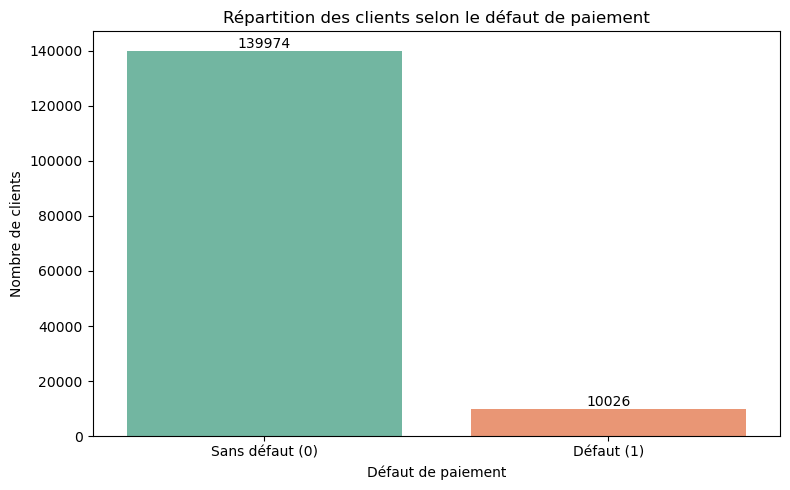

In [10]:
# Importation des bibliothèques de visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Création de la figure
plt.figure(figsize=(8, 5))

# Diagramme en barres de la variable cible
ax = sns.countplot(
    data=df,
    x="SeriousDlqin2yrs",
    hue="SeriousDlqin2yrs",
    palette="Set2",
    legend=False
)

# Ajout des effectifs au-dessus des barres
for container in ax.containers:
    ax.bar_label(container)

# Personnalisation du graphique
plt.title("Répartition des clients selon le défaut de paiement")
plt.xlabel("Défaut de paiement")
plt.ylabel("Nombre de clients")
plt.xticks([0, 1], ["Sans défaut (0)", "Défaut (1)"])

# Affichage du graphique
plt.tight_layout()
plt.show()

#### Interprétation 

D'après le graphique, je remarque que les deux classes sont fortement déséquilibrées :

- **Classe 0 (Sans défaut) :** 139 974 clients, soit 93,32 %.
- **Classe 1 (Défaut) :** 10 026 clients, soit 6,68 %.

La majorité des clients n'ont donc pas connu de défaut de paiement grave, tandis qu'une faible proportion appartient à la classe des clients en défaut.

Ce déséquilibre peut poser un problème lors de l'entraînement de notre modèle de classification. En effet, un modèle qui prédit toujours la classe 0 pourrait obtenir une Accuracy de 93,32 %, sans détecter aucun client en défaut.

**Conclusion :** cette analyse confirme la présence d'un fort déséquilibre des classes dans notre dataset. Nous allons donc étudier la technique **SMOTE** pour améliorer la détection des clients à risque, puis comparer ses performances avec celles d'une Régression Logistique sans SMOTE.

### 3.2. Analyse univariée des variables quantitatives

#### 3.2.1. Analyse de la variable age

Dans cette étape, je vais analyser la distribution des âges
des clients à l'aide des statistiques descriptives,
d'un histogramme et d'une boîte à moustaches.

L'objectif est d'étudier la tendance centrale, la dispersion,
l'asymétrie et de repérer les valeurs potentiellement aberrantes.

In [11]:
# Sélection de la variable age
age = df["age"]

# Calcul des mesures de tendance centrale
print("Moyenne :", round(age.mean(), 2))
print("Médiane :", age.median())
print("Mode :", age.mode()[0])

# Calcul des mesures de dispersion
print("\nMinimum :", age.min())
print("Maximum :", age.max())
print("Étendue :", age.max() - age.min())
print("Variance :", round(age.var(), 2))
print("Écart-type :", round(age.std(), 2))

# Calcul des quartiles et de l'écart interquartile
Q1 = age.quantile(0.25)
Q3 = age.quantile(0.75)
IQR = Q3 - Q1

print("\nQ1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)

# Calcul de la forme de la distribution
print("\nSkewness :", round(age.skew(), 2))
print("Kurtosis :", round(age.kurt(), 2))

Moyenne : 52.3
Médiane : 52.0
Mode : 49

Minimum : 0
Maximum : 109
Étendue : 109
Variance : 218.21
Écart-type : 14.77

Q1 : 41.0
Q3 : 63.0
IQR : 22.0

Skewness : 0.19
Kurtosis : -0.49


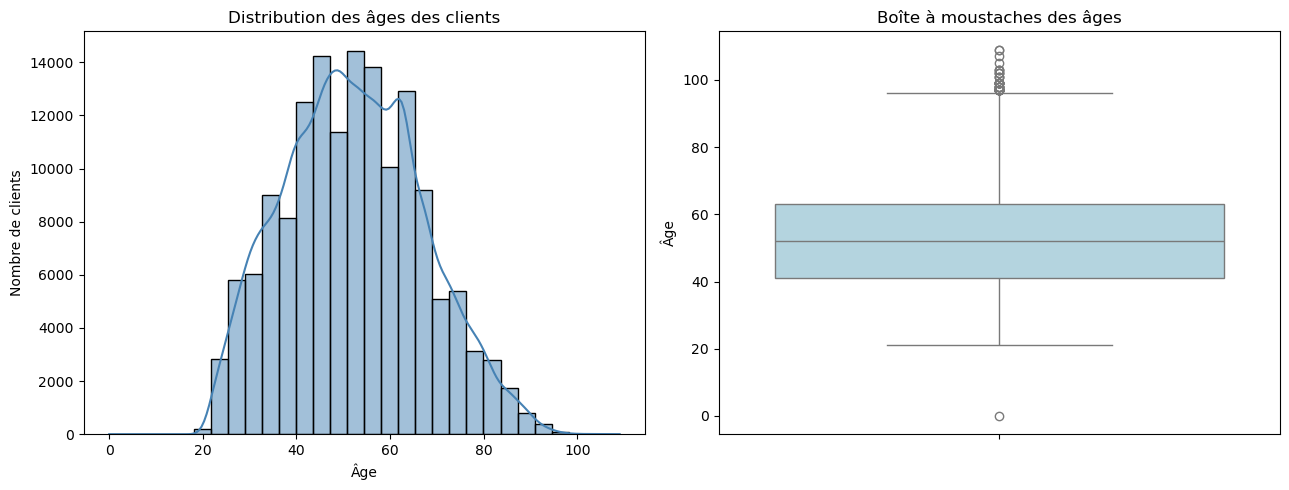

In [12]:
# Création de deux graphiques
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogramme pour visualiser la distribution des âges
sns.histplot(
    data=df,
    x="age",
    bins=30,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Distribution des âges des clients")
axes[0].set_xlabel("Âge")
axes[0].set_ylabel("Nombre de clients")

# Boxplot pour visualiser la dispersion et les valeurs extrêmes
sns.boxplot(
    data=df,
    y="age",
    color="lightblue",
    ax=axes[1]
)

axes[1].set_title("Boîte à moustaches des âges")
axes[1].set_ylabel("Âge")

# Ajustement et affichage
plt.tight_layout()
plt.show()

#### Interprétation 

D'après les résultats obtenus, je remarque que :

- **Tendance centrale :** l'âge moyen des clients est de 52,3 ans, avec une médiane de 52 ans et un mode de 49 ans. Ces valeurs proches montrent que les âges sont principalement concentrés autour de 50 ans.
- **Dispersion :** l'écart-type est de 14,77 ans et l'IQR est de 22 ans. Ainsi, 50 % des clients ont un âge compris entre 41 et 63 ans.
- **Asymétrie (Skewness = 0,19) :** la distribution est presque symétrique, avec une légère asymétrie vers la droite.
- **Kurtosis (-0,49) :** la distribution est légèrement moins pointue qu'une distribution normale, selon cette mesure.
- **Valeurs aberrantes :** le boxplot montre quelques valeurs atypiques, notamment un âge minimum de 0 an, qui est incorrect, et des âges supérieurs à 96 ans, qui sont rares mais pas nécessairement erronés.

**Conclusion :** la distribution des âges est relativement équilibrée et centrée autour de 52 ans. Cependant, certaines valeurs nécessitent une vérification lors de la phase de qualité des données.

#### 3.2.2. Analyse de la variable MonthlyIncome

Dans cette étape, je vais analyser la distribution des revenus
mensuels des clients à l'aide des statistiques descriptives
et des visualisations.

L'objectif est d'étudier la tendance centrale, la dispersion
et l'asymétrie des revenus, ainsi que d'identifier les valeurs
extrêmes et les valeurs manquantes.

In [13]:
# Sélection de la variable MonthlyIncome
revenus = df["MonthlyIncome"]

# Suppression temporaire des valeurs manquantes pour les calculs
# Le dataset original reste inchangé
revenus_valides = revenus.dropna()

# Calcul des mesures de tendance centrale
print("Moyenne :", round(revenus_valides.mean(), 2))
print("Médiane :", revenus_valides.median())
print("Mode :", revenus_valides.mode()[0])

# Calcul des mesures de dispersion
print("\nMinimum :", revenus_valides.min())
print("Maximum :", revenus_valides.max())
print("Étendue :", revenus_valides.max() - revenus_valides.min())
print("Variance :", round(revenus_valides.var(), 2))
print("Écart-type :", round(revenus_valides.std(), 2))

# Calcul des quartiles et de l'écart interquartile
Q1 = revenus_valides.quantile(0.25)
Q3 = revenus_valides.quantile(0.75)
IQR = Q3 - Q1

print("\nQ1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)

# Calcul du coefficient de variation
CV = revenus_valides.std() / revenus_valides.mean()
print("Coefficient de variation :", round(CV, 2))

# Calcul de la forme de la distribution
print("\nSkewness :", round(revenus_valides.skew(), 2))
print("Kurtosis :", round(revenus_valides.kurt(), 2))

# Vérification des valeurs manquantes
print("\nValeurs manquantes :", revenus.isnull().sum())
print("Pourcentage manquant :",
      round(revenus.isnull().mean() * 100, 2), "%")

Moyenne : 6670.22
Médiane : 5400.0
Mode : 5000.0

Minimum : 0.0
Maximum : 3008750.0
Étendue : 3008750.0
Variance : 206918852.28
Écart-type : 14384.67

Q1 : 3400.0
Q3 : 8249.0
IQR : 4849.0
Coefficient de variation : 2.16

Skewness : 114.04
Kurtosis : 19504.71

Valeurs manquantes : 29731
Pourcentage manquant : 19.82 %


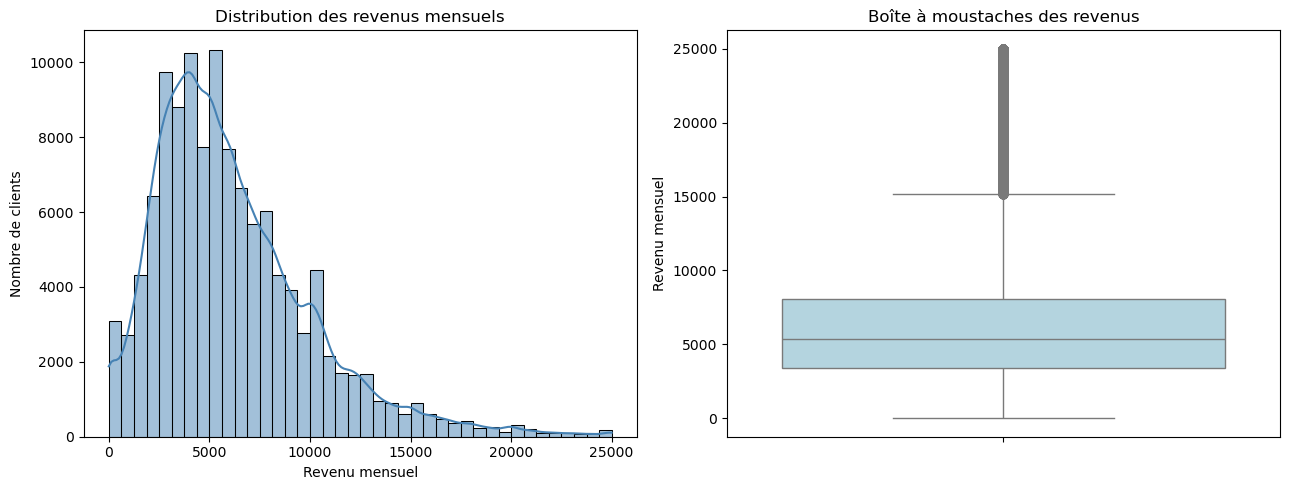

In [14]:
# Calcul du 99ème percentile des revenus
limite = revenus_valides.quantile(0.99)

# Sélection des revenus jusqu'au 99ème percentile
# Cette sélection est utilisée uniquement pour la visualisation
revenus_zoom = revenus_valides[revenus_valides <= limite]

# Création de deux graphiques
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogramme des revenus mensuels
sns.histplot(
    revenus_zoom,
    bins=40,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Distribution des revenus mensuels")
axes[0].set_xlabel("Revenu mensuel")
axes[0].set_ylabel("Nombre de clients")

# Boxplot pour visualiser la dispersion
sns.boxplot(
    y=revenus_zoom,
    color="lightblue",
    ax=axes[1]
)

axes[1].set_title("Boîte à moustaches des revenus")
axes[1].set_ylabel("Revenu mensuel")

# Ajustement et affichage des graphiques
plt.tight_layout()
plt.show()

#### Interprétation

D'après les résultats obtenus, je remarque que :

- **Tendance centrale :** le revenu mensuel moyen est de 6 670,22, tandis que la médiane est de 5 400 et le mode de 5 000. La moyenne est supérieure à la médiane, ce qui montre l'influence des revenus élevés.

- **Dispersion :** l'écart-type est de 14 384,67 et le coefficient de variation est de 2,16. Ces valeurs indiquent une forte dispersion des revenus. De plus, 50 % des revenus renseignés sont compris entre 3 400 et 8 249 (IQR = 4 849).

- **Asymétrie (Skewness = 114,04) :** la distribution est fortement asymétrique vers la droite, avec une longue queue correspondant aux revenus les plus élevés.

- **Kurtosis (19 504,71) :** cette valeur extrêmement élevée indique la présence de valeurs extrêmes qui influencent fortement la distribution.

- **Valeurs aberrantes :** le revenu maximum atteint 3 008 750, une valeur très éloignée des revenus habituels. Le boxplot confirme la présence de nombreuses valeurs atypiques élevées.

- **Valeurs manquantes :** la variable contient 29 731 valeurs manquantes, soit 19,82 % des observations. Ces valeurs devront être prises en compte pendant la préparation des données.

**Conclusion :** la variable `MonthlyIncome` présente une forte asymétrie, une dispersion importante et des valeurs manquantes. Pour la préparation des données, il sera nécessaire d'étudier un traitement adapté, notamment une imputation robuste et une gestion des valeurs extrêmes, sans supprimer automatiquement les revenus élevés.

#### 3.2.3. Analyse de la variable DebtRatio

Dans cette étape, je vais analyser la distribution du ratio
d'endettement des clients à l'aide des statistiques descriptives
et des visualisations.

L'objectif est d'étudier la tendance centrale, la dispersion,
l'asymétrie et d'identifier les valeurs potentiellement aberrantes.

In [15]:
# Sélection de la variable DebtRatio
debt = df["DebtRatio"]

# Calcul des mesures de tendance centrale
print("Moyenne :", round(debt.mean(), 2))
print("Médiane :", debt.median())
print("Mode :", debt.mode()[0])

# Calcul des mesures de dispersion
print("\nMinimum :", debt.min())
print("Maximum :", debt.max())
print("Étendue :", debt.max() - debt.min())
print("Variance :", round(debt.var(), 2))
print("Écart-type :", round(debt.std(), 2))

# Calcul des quartiles et de l'écart interquartile
Q1 = debt.quantile(0.25)
Q3 = debt.quantile(0.75)
IQR = Q3 - Q1

print("\nQ1 :", round(Q1, 2))
print("Q3 :", round(Q3, 2))
print("IQR :", round(IQR, 2))

# Calcul du coefficient de variation
CV = debt.std() / debt.mean()
print("Coefficient de variation :", round(CV, 2))

# Analyse de la forme de la distribution
print("\nSkewness :", round(debt.skew(), 2))
print("Kurtosis :", round(debt.kurt(), 2))

# Vérification des valeurs manquantes
print("\nValeurs manquantes :", debt.isnull().sum())

Moyenne : 353.01
Médiane : 0.366507841
Mode : 0.0

Minimum : 0.0
Maximum : 329664.0
Étendue : 329664.0
Variance : 4152704.33
Écart-type : 2037.82

Q1 : 0.18
Q3 : 0.87
IQR : 0.69
Coefficient de variation : 5.77

Skewness : 95.16
Kurtosis : 13734.29

Valeurs manquantes : 0


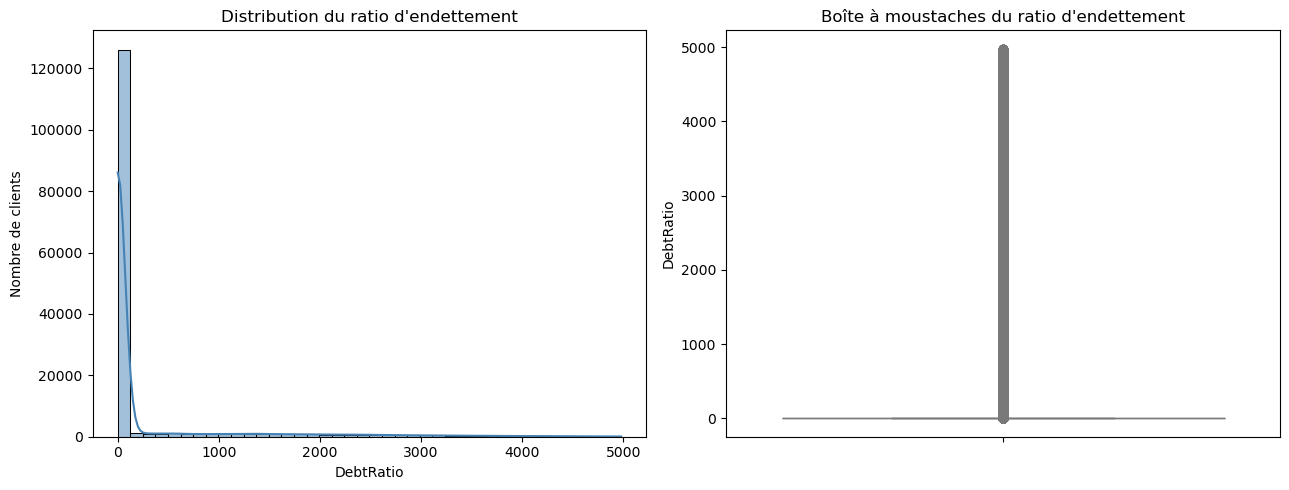

In [16]:
# Calcul du 99ème percentile de DebtRatio
limite = debt.quantile(0.99)

# Sélection des valeurs jusqu'au 99ème percentile
# Cette sélection concerne uniquement les graphiques
debt_zoom = debt[debt <= limite]

# Création de deux graphiques
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogramme du ratio d'endettement
sns.histplot(
    debt_zoom,
    bins=40,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Distribution du ratio d'endettement")
axes[0].set_xlabel("DebtRatio")
axes[0].set_ylabel("Nombre de clients")

# Boxplot pour visualiser la dispersion
sns.boxplot(
    y=debt_zoom,
    color="lightblue",
    ax=axes[1]
)

axes[1].set_title("Boîte à moustaches du ratio d'endettement")
axes[1].set_ylabel("DebtRatio")

# Ajustement et affichage
plt.tight_layout()
plt.show()

#### Interprétation 

D'après les résultats obtenus, je remarque que :

- **Tendance centrale :** la moyenne du ratio d'endettement est de 353,01, alors que la médiane est seulement de 0,37. Cette différence importante montre que la moyenne est fortement influencée par les valeurs extrêmes.

- **Dispersion :** l'écart-type est de 2 037,82 et le coefficient de variation est de 5,77, ce qui indique une très forte dispersion. Cependant, 50 % des observations se situent entre 0,18 et 0,87 (IQR = 0,69).

- **Asymétrie (Skewness = 95,16) :** la distribution est extrêmement asymétrique vers la droite, avec une longue queue de valeurs élevées.

- **Kurtosis (13 734,29) :** cette valeur très élevée indique la présence de valeurs extrêmes qui influencent fortement la forme de la distribution.

- **Valeurs aberrantes :** le maximum atteint 329 664, une valeur très éloignée de la médiane. Le boxplot confirme la présence de nombreuses valeurs atypiques qui nécessitent une vérification.

- **Valeurs manquantes :** aucune valeur manquante n'a été détectée dans cette variable.

**Conclusion :** la variable `DebtRatio` présente une distribution fortement asymétrique avec des valeurs extrêmes. Ces observations devront être étudiées pendant la vérification de la qualité des données afin de choisir un traitement adapté avant la modélisation.

#### 3.2.4. Analyse de la variable RevolvingUtilizationOfUnsecuredLines

Dans cette étape, je vais analyser la distribution du taux
d'utilisation du crédit renouvelable des clients.

L'objectif est d'étudier la tendance centrale, la dispersion,
l'asymétrie et d'identifier les valeurs extrêmes qui pourraient
influencer notre futur modèle de Credit Scoring.

In [17]:
# Sélection de la variable d'utilisation du crédit renouvelable
utilisation = df["RevolvingUtilizationOfUnsecuredLines"]

# Calcul des mesures de tendance centrale
print("Moyenne :", round(utilisation.mean(), 2))
print("Médiane :", utilisation.median())
print("Mode :", utilisation.mode()[0])

# Calcul des mesures de dispersion
print("\nMinimum :", utilisation.min())
print("Maximum :", utilisation.max())
print("Étendue :", utilisation.max() - utilisation.min())
print("Variance :", round(utilisation.var(), 2))
print("Écart-type :", round(utilisation.std(), 2))

# Calcul des quartiles et de l'écart interquartile
Q1 = utilisation.quantile(0.25)
Q3 = utilisation.quantile(0.75)
IQR = Q3 - Q1

print("\nQ1 :", round(Q1, 2))
print("Q3 :", round(Q3, 2))
print("IQR :", round(IQR, 2))

# Calcul du coefficient de variation
CV = utilisation.std() / utilisation.mean()
print("Coefficient de variation :", round(CV, 2))

# Calcul des mesures de forme
print("\nSkewness :", round(utilisation.skew(), 2))
print("Kurtosis :", round(utilisation.kurt(), 2))

# Vérification des valeurs manquantes
print("\nValeurs manquantes :", utilisation.isnull().sum())

Moyenne : 6.05
Médiane : 0.154180737
Mode : 0.0

Minimum : 0.0
Maximum : 50708.0
Étendue : 50708.0
Variance : 62377.75
Écart-type : 249.76

Q1 : 0.03
Q3 : 0.56
IQR : 0.53
Coefficient de variation : 41.29

Skewness : 97.63
Kurtosis : 14544.71

Valeurs manquantes : 0


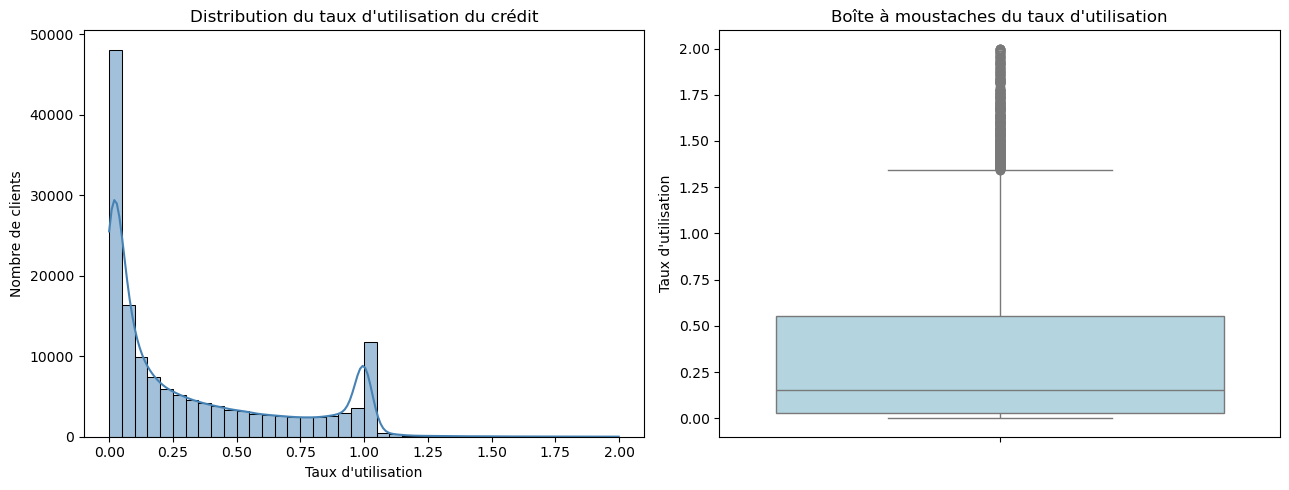

In [18]:
# Sélection des valeurs comprises entre 0 et 2
# Ce filtrage sert uniquement à la visualisation
utilisation_zoom = utilisation[
    (utilisation >= 0) & (utilisation <= 2)
]

# Création de deux graphiques
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogramme du taux d'utilisation du crédit
sns.histplot(
    utilisation_zoom,
    bins=40,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Distribution du taux d'utilisation du crédit")
axes[0].set_xlabel("Taux d'utilisation")
axes[0].set_ylabel("Nombre de clients")

# Boxplot pour visualiser la dispersion
sns.boxplot(
    y=utilisation_zoom,
    color="lightblue",
    ax=axes[1]
)

axes[1].set_title("Boîte à moustaches du taux d'utilisation")
axes[1].set_ylabel("Taux d'utilisation")

# Ajustement et affichage
plt.tight_layout()
plt.show()

#### Interprétation 
D'après les résultats obtenus, je remarque que :

- **Tendance centrale :** la moyenne du taux d'utilisation du crédit est de 6,05, tandis que la médiane est seulement de 0,15 (15 %). Cette grande différence montre que la moyenne est fortement influencée par les valeurs extrêmes.

- **Dispersion :** l'écart-type est de 249,76 et le coefficient de variation est de 41,29, ce qui indique une dispersion extrêmement élevée. Cependant, 50 % des observations se situent entre 0,03 et 0,56 (IQR = 0,53).

- **Asymétrie (Skewness = 97,63) :** la distribution est fortement asymétrique vers la droite. L'histogramme montre une concentration des observations près de 0, ainsi qu'un pic autour de 1, correspondant à une utilisation proche de 100 %.

- **Kurtosis (14 544,71) :** cette valeur très élevée indique la présence de valeurs extrêmes qui influencent fortement la distribution.

- **Valeurs aberrantes :** la valeur maximale atteint 50 708, ce qui est extrêmement élevé pour un taux d'utilisation du crédit. Le boxplot montre également plusieurs valeurs atypiques supérieures à 1, qui nécessitent une vérification.

- **Valeurs manquantes :** aucune valeur manquante n'a été détectée dans cette variable.

**Conclusion :** la variable `RevolvingUtilizationOfUnsecuredLines` présente une forte asymétrie et des valeurs extrêmes. Il sera nécessaire d'examiner ces observations pendant la vérification de la qualité des données, afin de choisir un traitement adapté avant la modélisation.

#### 3.2.5. Analyse des variables de retards de paiement

Dans cette étape, je vais analyser les trois variables
qui représentent les retards de paiement des clients :

- Retards de 30 à 59 jours
- Retards de 60 à 89 jours
- Retards de 90 jours ou plus

L'objectif est d'étudier la fréquence des retards,
leur dispersion et d'identifier les valeurs atypiques.

Cette analyse permettra de mieux comprendre les
antécédents de paiement des clients.

In [19]:
# Sélection des trois variables de retards de paiement
variables_retards = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

# Calcul des statistiques descriptives
stats_retards = df[variables_retards].describe().T

# Ajout de l'écart interquartile (IQR)
stats_retards["IQR"] = (
    stats_retards["75%"] - stats_retards["25%"]
)

# Ajout du pourcentage de clients sans retard
stats_retards["Sans retard (%)"] = (
    df[variables_retards].eq(0).mean() * 100
)

# Calcul de l'asymétrie et de la kurtosis
stats_retards["Skewness"] = df[variables_retards].skew()
stats_retards["Kurtosis"] = df[variables_retards].kurt()

# Affichage des résultats
display(stats_retards.round(2))

,count,mean,std,min,25%,50%,75%,max,IQR,Sans retard (%),Skewness,Kurtosis
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.42,4.19,0.0,0.0,0.0,0.0,98.0,0.0,84.01,22.60,522.38
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.24,4.16,0.0,0.0,0.0,0.0,98.0,0.0,94.93,23.33,545.68
NumberOfTimes90DaysLate,150000.0,0.27,4.17,0.0,0.0,0.0,0.0,98.0,0.0,94.44,23.09,537.74


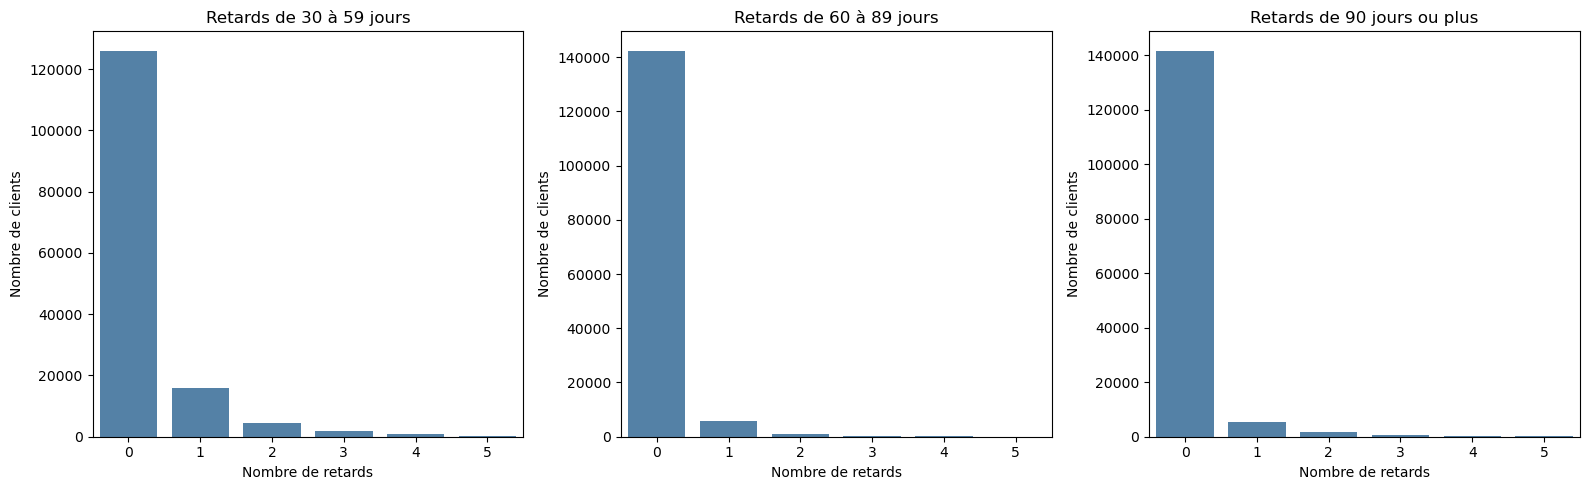

In [20]:
# Création d'une figure contenant trois graphiques
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Titres des trois graphiques
titres = [
    "Retards de 30 à 59 jours",
    "Retards de 60 à 89 jours",
    "Retards de 90 jours ou plus"
]

# Parcours des trois variables
for i, variable in enumerate(variables_retards):

    # Je sélectionne les retards compris entre 0 et 5
    # Cette sélection sert uniquement à la visualisation
    donnees_zoom = df[
        df[variable].between(0, 5)
    ]

    # Création du diagramme en barres
    sns.countplot(
        data=donnees_zoom,
        x=variable,
        order=range(6),
        color="steelblue",
        ax=axes[i]
    )

    # Personnalisation de chaque graphique
    axes[i].set_title(titres[i])
    axes[i].set_xlabel("Nombre de retards")
    axes[i].set_ylabel("Nombre de clients")

# Ajustement de l'affichage
plt.tight_layout()
plt.show()

In [21]:
# Vérification des valeurs inhabituelles dans les retards
for variable in variables_retards:

    print("\nVariable :", variable)

    # Je compte les occurrences des valeurs 96 et 98
    valeurs_suspectes = df[variable].isin([96, 98])

    print(
        "Nombre de valeurs 96 ou 98 :",
        valeurs_suspectes.sum()
    )

    # Affichage des fréquences de ces valeurs
    print(
        df.loc[valeurs_suspectes, variable]
        .value_counts()
        .sort_index()
    )


Variable : NumberOfTime30-59DaysPastDueNotWorse
Nombre de valeurs 96 ou 98 : 269
NumberOfTime30-59DaysPastDueNotWorse
96      5
98    264
Name: count, dtype: int64

Variable : NumberOfTime60-89DaysPastDueNotWorse
Nombre de valeurs 96 ou 98 : 269
NumberOfTime60-89DaysPastDueNotWorse
96      5
98    264
Name: count, dtype: int64

Variable : NumberOfTimes90DaysLate
Nombre de valeurs 96 ou 98 : 269
NumberOfTimes90DaysLate
96      5
98    264
Name: count, dtype: int64


#### Interprétation 

D'après les résultats obtenus, je remarque que :

- **Retards de 30 à 59 jours :** 84,01 % des clients n'ont enregistré aucun retard de cette catégorie. La moyenne est de 0,42 et la médiane est de 0.

- **Retards de 60 à 89 jours :** 94,93 % des clients n'ont aucun retard de cette catégorie. La moyenne est de 0,24 et la médiane est de 0.

- **Retards de 90 jours ou plus :** 94,44 % des clients n'ont aucun retard grave enregistré dans cette catégorie. La moyenne est de 0,27 et la médiane est de 0.

- **Dispersion et asymétrie :** les trois variables présentent un IQR de 0 et une asymétrie positive importante (Skewness supérieure à 22). Les distributions sont fortement concentrées sur la valeur 0, avec quelques valeurs extrêmes.

- **Valeurs suspectes :** j'ai identifié 269 occurrences des valeurs 96 et 98 dans chacune des trois variables, dont 5 occurrences de 96 et 264 de 98. Ces valeurs sont inhabituelles et pourraient correspondre à des anomalies ou à un codage particulier.

**Conclusion :** la majorité des clients présentent peu ou pas de retards de paiement. Cependant, les trois variables contiennent des valeurs extrêmes qui influencent les statistiques descriptives. Ces observations devront être examinées pendant la phase de vérification de la qualité des données avant leur traitement.

#### 3.2.6. Analyse des crédits et des personnes à charge

Dans cette étape, je vais analyser trois variables :
le nombre de crédits ouverts, le nombre de crédits immobiliers
et le nombre de personnes à charge.

L'objectif est d'étudier leur distribution à l'aide
des statistiques descriptives et des diagrammes en barres,
afin d'identifier les valeurs fréquentes et les valeurs atypiques.

In [22]:
# Sélection des trois variables à analyser
variables_credits = [
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    "NumberOfDependents"
]

# Calcul des statistiques descriptives
stats_credits = df[variables_credits].describe().T

# Calcul de l'écart interquartile
stats_credits["IQR"] = (
    stats_credits["75%"] - stats_credits["25%"]
)

# Calcul du pourcentage de clients ayant une valeur égale à 0
stats_credits["Valeurs nulles (%)"] = (
    df[variables_credits].eq(0).mean() * 100
)

# Calcul du nombre de valeurs manquantes
stats_credits["Valeurs manquantes"] = (
    df[variables_credits].isnull().sum()
)

# Calcul de l'asymétrie et de la kurtosis
stats_credits["Skewness"] = df[variables_credits].skew()
stats_credits["Kurtosis"] = df[variables_credits].kurt()

# Affichage des résultats
display(stats_credits.round(2))

,count,mean,std,min,25%,50%,75%,max,IQR,Valeurs nulles (%),Valeurs manquantes,Skewness,Kurtosis
NumberOfOpenCreditLinesAndLoans,150000.0,8.45,5.15,0.0,5.0,8.0,11.0,58.0,6.0,1.26,0,1.22,3.09
NumberRealEstateLoansOrLines,150000.0,1.02,1.13,0.0,0.0,1.0,2.0,54.0,2.0,37.46,0,3.48,60.48
NumberOfDependents,146076.0,0.76,1.12,0.0,0.0,0.0,1.0,20.0,1.0,57.93,3924,1.59,3.00


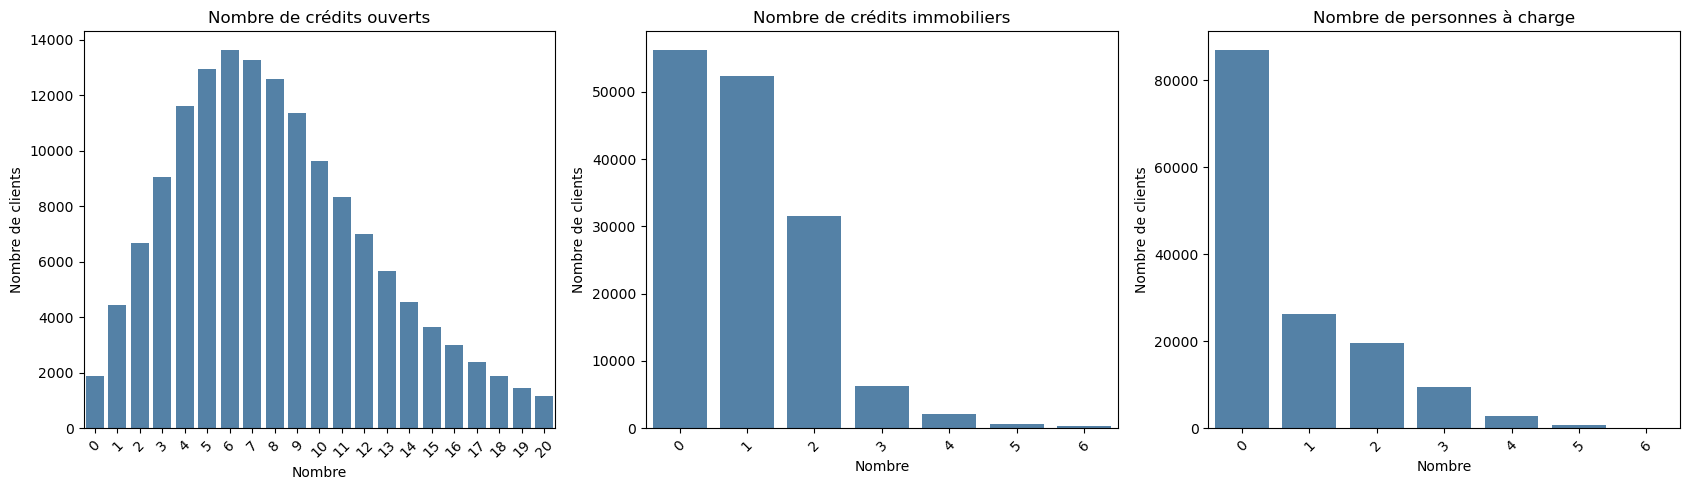

In [23]:
# Définition des limites pour faciliter la visualisation
limites = [20, 6, 6]

# Titres des graphiques
titres = [
    "Nombre de crédits ouverts",
    "Nombre de crédits immobiliers",
    "Nombre de personnes à charge"
]

# Création de trois graphiques
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Parcours des trois variables
for i, variable in enumerate(variables_credits):

    # Sélection des valeurs comprises entre 0 et la limite choisie
    donnees_zoom = df.loc[
        df[variable].between(0, limites[i]),
        variable
    ].dropna().astype(int)

    # Création du diagramme en barres
    sns.countplot(
        x=donnees_zoom,
        order=list(range(limites[i] + 1)),
        color="steelblue",
        ax=axes[i]
    )

    # Personnalisation de chaque graphique
    axes[i].set_title(titres[i])
    axes[i].set_xlabel("Nombre")
    axes[i].set_ylabel("Nombre de clients")

    # Rotation des étiquettes pour faciliter la lecture
    axes[i].tick_params(axis="x", rotation=45)

# Ajustement et affichage des graphiques
plt.tight_layout()
plt.show()

#### Interprétation 
D'après les graphiques obtenus, je remarque que :

- **Nombre de crédits ouverts :** la majorité des clients possèdent entre 4 et 11 crédits ou lignes de crédit ouverts, avec une concentration autour de 6 à 8. Au-delà, le nombre de clients diminue progressivement.

- **Nombre de crédits immobiliers :** la plupart des clients possèdent entre 0 et 2 crédits immobiliers. Le nombre de clients diminue fortement à partir de 3 crédits, ce qui montre une distribution asymétrique vers la droite.

- **Nombre de personnes à charge :** la majorité des clients n'ont aucune personne à charge (environ 57,93 % de l'ensemble des observations). Les clients ayant une ou deux personnes à charge sont également représentés, mais les effectifs diminuent progressivement à partir de trois.

**Conclusion :** les trois distributions montrent que les clients sont principalement concentrés autour de valeurs relativement faibles ou modérées. Certaines observations présentent des nombres élevés de crédits ou de personnes à charge, qui devront être examinés lors de la vérification de la qualité des données.

### 3.3. Analyse bivariée

#### 3.3.1. Relation entre l'âge et le défaut de paiement

Dans cette étape, je vais étudier la relation entre l'âge
des clients et le défaut de paiement.

L'objectif est de comparer la distribution des âges entre
les clients sans défaut (classe 0) et les clients ayant
connu un défaut de paiement (classe 1).

Pour cela, je vais utiliser les statistiques descriptives,
un boxplot et le test statistique de Mann-Whitney.

In [24]:
# Calcul des statistiques de l'âge selon la classe de défaut
stats_age_defaut = df.groupby("SeriousDlqin2yrs")["age"].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

# Affichage des résultats
display(stats_age_defaut.round(2))

,count,mean,median,std,min,max
SeriousDlqin2yrs,,,,,,
0,139974,52.75,52.0,14.79,0,109
1,10026,45.93,45.0,12.92,21,101


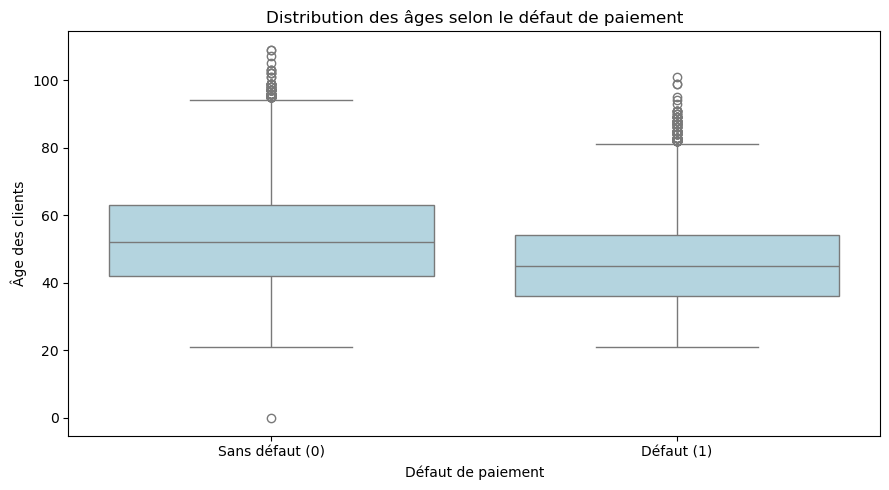

In [25]:
# Création de la figure
plt.figure(figsize=(9, 5))

# Comparaison des âges selon le défaut de paiement
sns.boxplot(
    data=df,
    x="SeriousDlqin2yrs",
    y="age",
    order=[0, 1],
    color="lightblue"
)

# Personnalisation du graphique
plt.title("Distribution des âges selon le défaut de paiement")
plt.xlabel("Défaut de paiement")
plt.ylabel("Âge des clients")
plt.xticks([0, 1], ["Sans défaut (0)", "Défaut (1)"])

# Affichage
plt.tight_layout()
plt.show()

In [26]:
# Importation du test statistique
from scipy.stats import mannwhitneyu

# Sélection des âges des clients sans défaut
age_sans_defaut = df.loc[
    df["SeriousDlqin2yrs"] == 0, "age"
].dropna()

# Sélection des âges des clients avec défaut
age_avec_defaut = df.loc[
    df["SeriousDlqin2yrs"] == 1, "age"
].dropna()

# Application du test de Mann-Whitney
statistique, p_value = mannwhitneyu(
    age_sans_defaut,
    age_avec_defaut,
    alternative="two-sided",
    method="asymptotic"
)

# Affichage des résultats
print("Statistique U :", statistique)
print(f"P-value : {p_value:.3e}")

# Interprétation statistique du test
alpha = 0.05

if p_value < alpha:
    print("Résultat : différence statistiquement significative.")
else:
    print("Résultat : différence non statistiquement significative.")
    

Statistique U : 891498378.5
P-value : 0.000e+00
Résultat : différence statistiquement significative.


#### Interprétation 

D'après les résultats obtenus, je remarque que :

- **Clients sans défaut (Classe 0) :** l'âge moyen est de 52,75 ans, avec une médiane de 52 ans.
- **Clients avec défaut (Classe 1) :** l'âge moyen est de 45,93 ans, avec une médiane de 45 ans.
- **Comparaison :** les clients ayant connu un défaut de paiement sont en moyenne environ 6,82 ans plus jeunes que ceux sans défaut.
- **Boxplot :** le graphique montre que la distribution des âges des clients en défaut est décalée vers les âges plus jeunes.
- **Test de Mann-Whitney :** la p-value affichée est extrêmement faible (inférieure à 0,05). Je rejette donc l'hypothèse nulle H0, ce qui indique une différence statistiquement significative entre les distributions des âges des deux groupes.

**Conclusion :** cette analyse montre une association statistiquement significative entre l'âge et le défaut de paiement. Dans notre dataset, les clients plus jeunes sont davantage représentés parmi les cas de défaut. L'âge pourrait donc être une variable utile pour notre modèle de Credit Scoring, mais cette relation ne prouve pas un lien de causalité.

#### 3.3.2. Relation entre le revenu mensuel et le défaut de paiement

Dans cette étape, je vais étudier la relation entre le revenu
mensuel des clients et le défaut de paiement.

L'objectif est de comparer les revenus des clients sans défaut
et ceux ayant connu un défaut de paiement, afin de vérifier
s'il existe une différence statistiquement significative.

Pour cela, je vais utiliser les statistiques descriptives,
un boxplot et le test de Mann-Whitney.

In [27]:
# Calcul des statistiques du revenu selon la classe de défaut
stats_revenus_defaut = df.groupby("SeriousDlqin2yrs")["MonthlyIncome"].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

# Affichage des résultats avec deux décimales
display(stats_revenus_defaut.round(2))

,count,mean,median,std,min,max
SeriousDlqin2yrs,,,,,,
0,111912,6747.84,5466.0,14813.50,0.0,3008750.0
1,8357,5630.83,4500.0,6171.72,0.0,250000.0


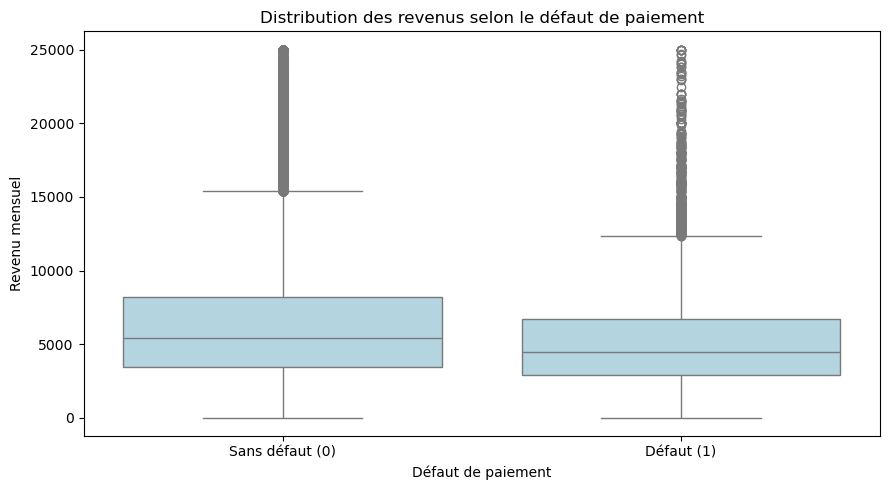

In [28]:
# Calcul du 99ème percentile des revenus mensuels
limite_revenu = df["MonthlyIncome"].quantile(0.99)

# Sélection des revenus renseignés inférieurs ou égaux à la limite
# Cette sélection sert uniquement à la visualisation
df_revenus_zoom = df[
    df["MonthlyIncome"].notna() &
    (df["MonthlyIncome"] <= limite_revenu)
]

# Création de la figure
plt.figure(figsize=(9, 5))

# Comparaison des revenus selon le défaut de paiement
sns.boxplot(
    data=df_revenus_zoom,
    x="SeriousDlqin2yrs",
    y="MonthlyIncome",
    order=[0, 1],
    color="lightblue"
)

# Personnalisation du graphique
plt.title("Distribution des revenus selon le défaut de paiement")
plt.xlabel("Défaut de paiement")
plt.ylabel("Revenu mensuel")
plt.xticks([0, 1], ["Sans défaut (0)", "Défaut (1)"])

# Affichage du graphique
plt.tight_layout()
plt.show()

In [29]:
# Sélection des revenus des clients sans défaut
revenus_sans_defaut = df.loc[
    df["SeriousDlqin2yrs"] == 0,
    "MonthlyIncome"
].dropna()

# Sélection des revenus des clients avec défaut
revenus_avec_defaut = df.loc[
    df["SeriousDlqin2yrs"] == 1,
    "MonthlyIncome"
].dropna()

# Application du test de Mann-Whitney
statistique, p_value = mannwhitneyu(
    revenus_sans_defaut,
    revenus_avec_defaut,
    alternative="two-sided",
    method="asymptotic"
)

# Affichage des résultats
print("Statistique U :", statistique)
print(f"P-value : {p_value:.3e}")

# Vérification de la significativité statistique
alpha = 0.05

if p_value < alpha:
    print("Résultat : différence statistiquement significative.")
else:
    print("Résultat : différence non statistiquement significative.")

Statistique U : 538739284.5
P-value : 2.354e-119
Résultat : différence statistiquement significative.


#### Interprétation 

D'après les résultats obtenus, je remarque que :

- **Clients sans défaut (Classe 0) :** le revenu mensuel moyen est de 6 747,84, avec une médiane de 5 466.
- **Clients avec défaut (Classe 1) :** le revenu mensuel moyen est de 5 630,83, avec une médiane de 4 500.
- **Comparaison :** les clients sans défaut ont un revenu moyen supérieur d'environ 1 117 unités monétaires à celui des clients en défaut.
- **Boxplot :** le graphique montre que les revenus des clients sans défaut sont globalement plus élevés. Cependant, les deux distributions se chevauchent et présentent de nombreuses valeurs extrêmes.
- **Test de Mann-Whitney :** la p-value obtenue est de 2,354 × 10⁻¹¹⁹, largement inférieure au seuil de 0,05. Je rejette donc l'hypothèse nulle H0, ce qui indique une différence statistiquement significative entre les distributions des revenus des deux groupes.

**Conclusion :** cette analyse montre une association statistiquement significative entre le revenu mensuel et le défaut de paiement. Les clients ayant connu un défaut présentent généralement des revenus plus faibles. La variable `MonthlyIncome` pourrait donc apporter des informations utiles à notre modèle de Credit Scoring, sans constituer à elle seule un critère suffisant pour prédire le défaut.

#### 3.3.3. Relation entre le ratio d'endettement et le défaut de paiement

Dans cette étape, je vais étudier la relation entre le ratio
d'endettement (DebtRatio) et le défaut de paiement.

L'objectif est de comparer les ratios d'endettement des clients
sans défaut (classe 0) et des clients avec défaut (classe 1).

Pour cela, je vais utiliser les statistiques descriptives,
un boxplot et le test statistique de Mann-Whitney.

In [30]:
# Calcul des statistiques du ratio d'endettement selon la classe
stats_debt_defaut = df.groupby("SeriousDlqin2yrs")["DebtRatio"].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

# Affichage des résultats avec deux décimales
display(stats_debt_defaut.round(2))

,count,mean,median,std,min,max
SeriousDlqin2yrs,,,,,,
0,139974,357.15,0.36,2083.28,0.0,329664.0
1,10026,295.12,0.43,1238.36,0.0,38793.0


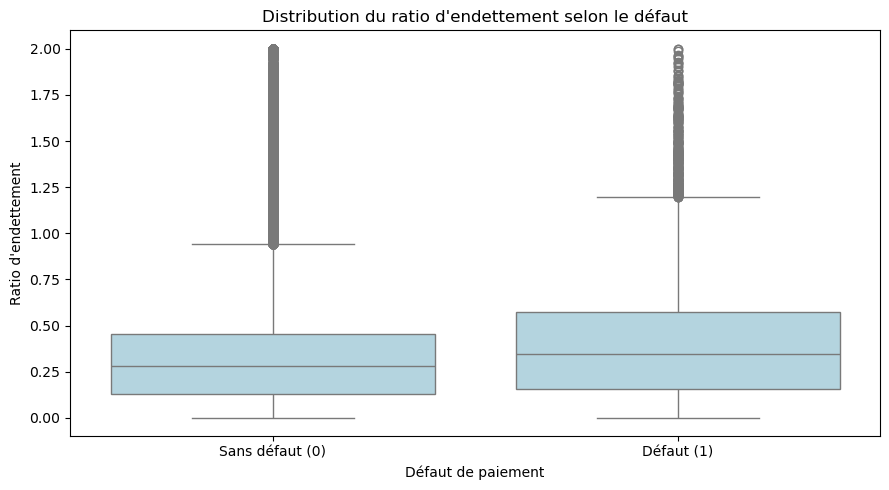

In [31]:
# Sélection des ratios d'endettement compris entre 0 et 2
# Cette sélection sert uniquement à la visualisation
df_debt_zoom = df[
    df["DebtRatio"].between(0, 2)
]

# Création de la figure
plt.figure(figsize=(9, 5))

# Comparaison du ratio d'endettement selon la classe
sns.boxplot(
    data=df_debt_zoom,
    x="SeriousDlqin2yrs",
    y="DebtRatio",
    order=[0, 1],
    color="lightblue"
)

# Personnalisation du graphique
plt.title("Distribution du ratio d'endettement selon le défaut")
plt.xlabel("Défaut de paiement")
plt.ylabel("Ratio d'endettement")
plt.xticks([0, 1], ["Sans défaut (0)", "Défaut (1)"])

# Affichage du graphique
plt.tight_layout()
plt.show()

In [32]:
# Importation du test statistique
from scipy.stats import mannwhitneyu

# Sélection des ratios des clients sans défaut
debt_sans_defaut = df.loc[
    df["SeriousDlqin2yrs"] == 0,
    "DebtRatio"
].dropna()

# Sélection des ratios des clients avec défaut
debt_avec_defaut = df.loc[
    df["SeriousDlqin2yrs"] == 1,
    "DebtRatio"
].dropna()

# Application du test de Mann-Whitney
statistique, p_value = mannwhitneyu(
    debt_sans_defaut,
    debt_avec_defaut,
    alternative="two-sided",
    method="asymptotic"
)

# Affichage des résultats
print("Statistique U :", statistique)
print(f"P-value : {p_value:.3e}")

# Vérification de la significativité statistique
alpha = 0.05

if p_value < alpha:
    print("Résultat : différence statistiquement significative.")
else:
    print("Résultat : différence non statistiquement significative.")

Statistique U : 668279072.0
P-value : 1.498e-15
Résultat : différence statistiquement significative.


#### Interprétation 

D'après les résultats obtenus, je remarque que :

- **Clients sans défaut (Classe 0) :** le ratio d'endettement moyen est de 357,15, avec une médiane de 0,36.
- **Clients avec défaut (Classe 1) :** le ratio d'endettement moyen est de 295,12, avec une médiane de 0,43.
- **Comparaison :** les clients en défaut présentent une médiane plus élevée (0,43 contre 0,36). En revanche, leur moyenne est plus faible, car les valeurs extrêmes influencent fortement cette statistique.
- **Boxplot :** le graphique montre que les ratios d'endettement des clients en défaut sont globalement plus élevés dans la plage visualisée (entre 0 et 2), mais les deux distributions se chevauchent.
- **Test de Mann-Whitney :** la p-value obtenue est de 1,498 × 10⁻¹⁵, largement inférieure au seuil de 0,05. Je rejette donc l'hypothèse nulle H0, ce qui indique une différence statistiquement significative entre les distributions des deux groupes.

**Conclusion :** cette analyse montre une association statistiquement significative entre le ratio d'endettement et le défaut de paiement. La variable `DebtRatio` pourrait donc être utile pour notre modèle de Credit Scoring. Cependant, la présence de valeurs extrêmes nécessite une analyse plus approfondie avant la modélisation.

#### 3.3.4. Relation entre l'utilisation du crédit et le défaut de paiement

Dans cette étape, je vais étudier la relation entre le taux
d'utilisation du crédit renouvelable et le défaut de paiement.

L'objectif est de comparer les taux d'utilisation des clients
sans défaut (classe 0) et des clients avec défaut (classe 1).

Pour cela, je vais utiliser les statistiques descriptives,
un boxplot et le test de Mann-Whitney.

In [33]:
# Sélection de la variable à analyser
variable = "RevolvingUtilizationOfUnsecuredLines"

# Calcul des statistiques selon la classe de défaut
stats_utilisation_defaut = df.groupby("SeriousDlqin2yrs")[variable].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

# Affichage des résultats avec deux décimales
display(stats_utilisation_defaut.round(2))

,count,mean,median,std,min,max
SeriousDlqin2yrs,,,,,,
0,139974,6.17,0.13,256.13,0.0,50708.0
1,10026,4.37,0.84,131.84,0.0,8328.0


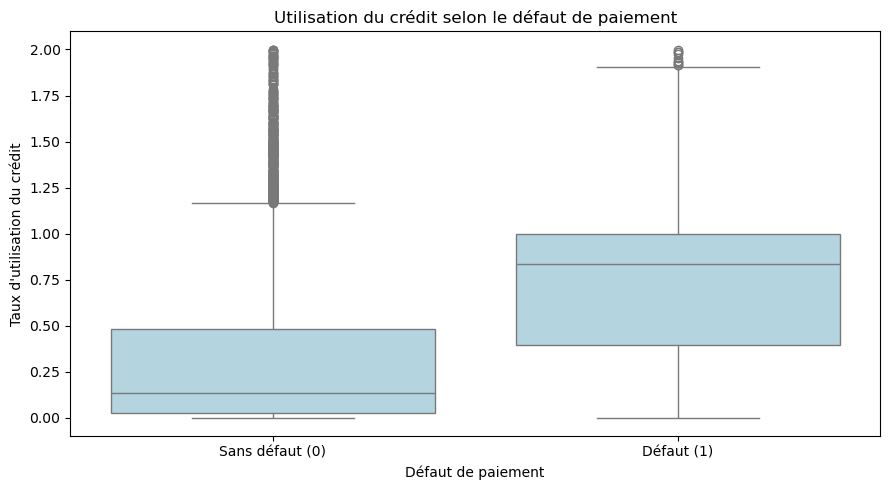

In [34]:
# Sélection des taux d'utilisation compris entre 0 et 2
# Cette sélection sert uniquement à la visualisation
df_utilisation_zoom = df[
    df["RevolvingUtilizationOfUnsecuredLines"].between(0, 2)
]

# Création de la figure
plt.figure(figsize=(9, 5))

# Comparaison du taux d'utilisation selon le défaut de paiement
sns.boxplot(
    data=df_utilisation_zoom,
    x="SeriousDlqin2yrs",
    y="RevolvingUtilizationOfUnsecuredLines",
    order=[0, 1],
    color="lightblue"
)

# Personnalisation du graphique
plt.title("Utilisation du crédit selon le défaut de paiement")
plt.xlabel("Défaut de paiement")
plt.ylabel("Taux d'utilisation du crédit")
plt.xticks([0, 1], ["Sans défaut (0)", "Défaut (1)"])

# Affichage du graphique
plt.tight_layout()
plt.show()

In [35]:
# Importation du test statistique
from scipy.stats import mannwhitneyu

# Sélection des taux d'utilisation des clients sans défaut
utilisation_sans_defaut = df.loc[
    df["SeriousDlqin2yrs"] == 0,
    "RevolvingUtilizationOfUnsecuredLines"
].dropna()

# Sélection des taux d'utilisation des clients avec défaut
utilisation_avec_defaut = df.loc[
    df["SeriousDlqin2yrs"] == 1,
    "RevolvingUtilizationOfUnsecuredLines"
].dropna()

# Application du test de Mann-Whitney
statistique, p_value = mannwhitneyu(
    utilisation_sans_defaut,
    utilisation_avec_defaut,
    alternative="two-sided",
    method="asymptotic"
)

# Affichage des résultats
print("Statistique U :", statistique)
print(f"P-value : {p_value:.3e}")

# Vérification de la significativité statistique
alpha = 0.05

if p_value < alpha:
    print("Résultat : différence statistiquement significative.")
else:
    print("Résultat : différence non statistiquement significative.")

Statistique U : 311899450.0
P-value : 0.000e+00
Résultat : différence statistiquement significative.


#### Interprétation

D'après les résultats obtenus, je remarque que :

- **Clients sans défaut (Classe 0) :** le taux d'utilisation moyen est de 6,17, avec une médiane de 0,13 (13 %).
- **Clients avec défaut (Classe 1) :** le taux d'utilisation moyen est de 4,37, avec une médiane de 0,84 (84 %).
- **Comparaison :** les clients en défaut présentent une médiane nettement plus élevée (84 % contre 13 %). Cependant, la moyenne est plus élevée pour la classe 0 à cause des valeurs extrêmes.
- **Boxplot :** le graphique montre que les clients ayant

#### 3.3.5. Relation entre les retards de paiement et le défaut de paiement

Dans cette étape, je vais étudier la relation entre les
trois variables de retards de paiement et la variable cible.

L'objectif est de vérifier si les clients ayant des
antécédents de retard présentent des taux de défaut
plus élevés.

Pour cela, je vais comparer les taux de défaut selon
le nombre de retards, puis utiliser le test du Khi-deux
et le V de Cramér pour mesurer leur association.

Les valeurs suspectes 96 et 98 seront temporairement
écartées de cette analyse, sans modifier le dataset original.

In [36]:
# Importation de la bibliothèque NumPy
import numpy as np

# Sélection des trois variables de retards
variables_retards = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

# Dictionnaire pour conserver les résultats
resultats_retards = {}

# Analyse de chaque variable de retard
for variable in variables_retards:

    # Exclusion temporaire des valeurs suspectes 96 et 98
    # Le dataset original df reste inchangé
    donnees = df.loc[
        ~df[variable].isin([96, 98]),
        [variable, "SeriousDlqin2yrs"]
    ].copy()

    # Regroupement des retards en quatre catégories
    donnees["Groupe"] = pd.cut(
        donnees[variable],
        bins=[-0.5, 0.5, 1.5, 2.5, float("inf")],
        labels=["0", "1", "2", "3+"]
    )

    # Calcul des effectifs et des taux de défaut
    tableau = donnees.groupby(
        "Groupe", observed=False
    )["SeriousDlqin2yrs"].agg([
        "size", "sum", "mean"
    ])

    # Renommage des colonnes
    tableau.columns = [
        "Nombre de clients",
        "Clients en défaut",
        "Taux de défaut (%)"
    ]

    # Conversion du taux de défaut en pourcentage
    tableau["Taux de défaut (%)"] *= 100

    # Conservation des résultats pour les graphiques
    resultats_retards[variable] = tableau

    # Affichage du résultat
    print("\nVariable :", variable)
    display(tableau.round(2))


Variable : NumberOfTime30-59DaysPastDueNotWorse


,Nombre de clients,Clients en défaut,Taux de défaut (%)
Groupe,,,
0,126018,5041,4.00
1,16033,2409,15.03
2,4598,1219,26.51
3+,3082,1210,39.26



Variable : NumberOfTime60-89DaysPastDueNotWorse


,Nombre de clients,Clients en défaut,Taux de défaut (%)
Groupe,,,
0,142396,7256,5.10
1,5731,1777,31.01
2,1118,561,50.18
3+,486,285,58.64



Variable : NumberOfTimes90DaysLate


,Nombre de clients,Clients en défaut,Taux de défaut (%)
Groupe,,,
0,141662,6554,4.63
1,5243,1765,33.66
2,1555,776,49.90
3+,1271,784,61.68


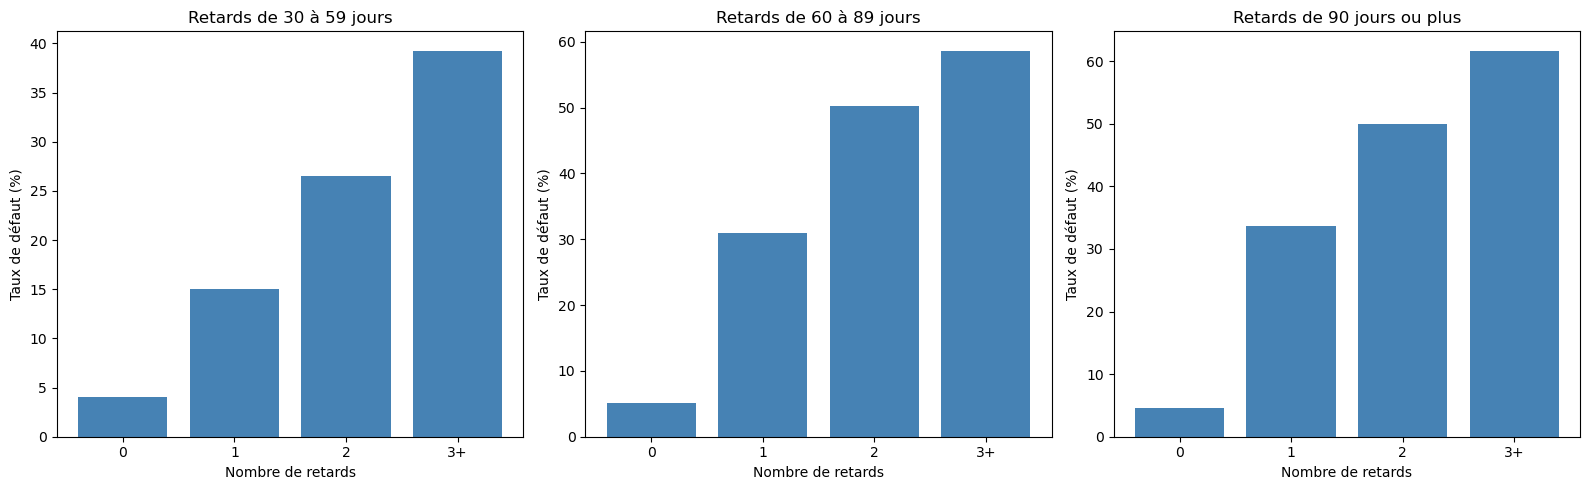

In [37]:
# Titres des graphiques
titres = [
    "Retards de 30 à 59 jours",
    "Retards de 60 à 89 jours",
    "Retards de 90 jours ou plus"
]

# Création de trois graphiques
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Parcours des trois variables
for i, variable in enumerate(variables_retards):

    # Récupération des résultats calculés précédemment
    tableau = resultats_retards[variable]

    # Création du diagramme en barres
    axes[i].bar(
        tableau.index.astype(str),
        tableau["Taux de défaut (%)"],
        color="steelblue"
    )

    # Personnalisation du graphique
    axes[i].set_title(titres[i])
    axes[i].set_xlabel("Nombre de retards")
    axes[i].set_ylabel("Taux de défaut (%)")

# Ajustement des graphiques
plt.tight_layout()
plt.show()

In [38]:
# Importation du test du Khi-deux
from scipy.stats import chi2_contingency

# Parcours des trois variables de retards
for variable in variables_retards:

    # Exclusion temporaire des valeurs 96 et 98
    donnees = df.loc[
        ~df[variable].isin([96, 98]),
        [variable, "SeriousDlqin2yrs"]
    ].copy()

    # Regroupement des retards en catégories
    donnees["Groupe"] = pd.cut(
        donnees[variable],
        bins=[-0.5, 0.5, 1.5, 2.5, float("inf")],
        labels=["0", "1", "2", "3+"]
    )

    # Création du tableau de contingence
    tableau_croise = pd.crosstab(
        donnees["Groupe"],
        donnees["SeriousDlqin2yrs"]
    )

    # Application du test du Khi-deux
    chi2, p_value, ddl, effectifs_attendus = chi2_contingency(
        tableau_croise
    )

    # Calcul du V de Cramér
    n = tableau_croise.to_numpy().sum()
    k = min(tableau_croise.shape) - 1

    v_cramer = np.sqrt(chi2 / (n * k))

    # Affichage des résultats
    print("\nVariable :", variable)
    print("Khi-deux :", round(chi2, 2))
    print(f"P-value : {p_value:.3e}")
    print("V de Cramér :", round(v_cramer, 4))

    # Vérification de la significativité
    if p_value < 0.05:
        print("Association statistiquement significative.")
    else:
        print("Association non statistiquement significative.")


Variable : NumberOfTime30-59DaysPastDueNotWorse
Khi-deux : 11521.82
P-value : 0.000e+00
V de Cramér : 0.2774
Association statistiquement significative.

Variable : NumberOfTime60-89DaysPastDueNotWorse
Khi-deux : 11644.02
P-value : 0.000e+00
V de Cramér : 0.2789
Association statistiquement significative.

Variable : NumberOfTimes90DaysLate
Khi-deux : 18116.64
P-value : 0.000e+00
V de Cramér : 0.3478
Association statistiquement significative.


#### Interprétation des résultats

D'après les résultats obtenus, je remarque que :

- **Retards de 30 à 59 jours :** le taux de défaut passe de 4 % chez les clients sans retard à 39,26 % chez ceux ayant au moins trois retards.
- **Retards de 60 à 89 jours :** le taux de défaut augmente de 5,10 % pour les clients sans retard à 58,64 % pour ceux ayant au moins trois retards.
- **Retards de 90 jours ou plus :** le taux de défaut passe de 4,63 % chez les clients sans retard à 61,68 % chez ceux ayant au moins trois retards. Cette variable présente une association particulièrement importante avec le défaut de paiement.

**Tests statistiques :**

Les trois tests du Khi-deux donnent des p-values extrêmement faibles, inférieures à 0,05. Je rejette donc l'hypothèse d'indépendance entre les groupes de retards et le défaut de paiement.

Les valeurs du V de Cramér sont :

- Retards de 30–59 jours : **0,2774**
- Retards de 60–89 jours : **0,2789**
- Retards de 90 jours ou plus : **0,3478**

La variable `NumberOfTimes90DaysLate` présente donc l'association la plus forte avec le défaut de paiement parmi les trois variables étudiées.

**Conclusion :** cette analyse montre que les antécédents de retard de paiement sont fortement associés au risque de défaut. Plus le nombre de retards augmente, plus le taux de défaut observé est élevé. Ces variables semblent donc particulièrement intéressantes pour notre futur modèle de Credit Scoring.

Les valeurs suspectes 96 et 98 ont été exclues temporairement de cette analyse et devront être examinées pendant la vérification de la qualité des données.

#### 3.3.6. Relation entre les crédits, les personnes à charge et le défaut de paiement

Dans cette étape, je vais étudier la relation entre
le nombre de crédits ouverts, les crédits immobiliers,
les personnes à charge et le défaut de paiement.

L'objectif est de vérifier si ces variables sont associées
au risque de défaut.

Pour cela, je vais calculer les taux de défaut par groupe,
visualiser les résultats et appliquer le test du Khi-deux
ainsi que le V de Cramér.

In [39]:
# Importation de NumPy
import numpy as np

# Définition des variables et de leurs catégories
config_variables = {
    "NumberOfOpenCreditLinesAndLoans": {
        "bins": [-0.5, 3.5, 7.5, 12.5, np.inf],
        "labels": ["0-3", "4-7", "8-12", "13+"]
    },

    "NumberRealEstateLoansOrLines": {
        "bins": [-0.5, 0.5, 1.5, 2.5, np.inf],
        "labels": ["0", "1", "2", "3+"]
    },

    "NumberOfDependents": {
        "bins": [-0.5, 0.5, 1.5, 2.5, np.inf],
        "labels": ["0", "1", "2", "3+"]
    }
}

# Dictionnaire pour conserver les résultats
resultats_credits = {}

# Parcours des trois variables
for variable, config in config_variables.items():

    # Sélection des données nécessaires
    donnees = df[[variable, "SeriousDlqin2yrs"]].copy()

    # Regroupement des valeurs en catégories
    donnees["Groupe"] = pd.cut(
        donnees[variable],
        bins=config["bins"],
        labels=config["labels"]
    )

    # Calcul des effectifs et du taux de défaut
    tableau = donnees.groupby(
        "Groupe", observed=True
    )["SeriousDlqin2yrs"].agg([
        "size", "sum", "mean"
    ])

    # Renommage des colonnes
    tableau.columns = [
        "Nombre de clients",
        "Clients en défaut",
        "Taux de défaut (%)"
    ]

    # Conversion en pourcentage
    tableau["Taux de défaut (%)"] *= 100

    # Conservation du résultat
    resultats_credits[variable] = tableau

    # Affichage du tableau
    print("\nVariable :", variable)
    display(tableau.round(2))
    


Variable : NumberOfOpenCreditLinesAndLoans


,Nombre de clients,Clients en défaut,Taux de défaut (%)
Groupe,,,
0-3,22050,2360,10.70
4-7,51399,3063,5.96
8-12,48867,2757,5.64
13+,27684,1846,6.67



Variable : NumberRealEstateLoansOrLines


,Nombre de clients,Clients en défaut,Taux de défaut (%)
Groupe,,,
0,56188,4672,8.31
1,52338,2748,5.25
2,31522,1765,5.60
3+,9952,841,8.45



Variable : NumberOfDependents


,Nombre de clients,Clients en défaut,Taux de défaut (%)
Groupe,,,
0,86902,5095,5.86
1,26316,1935,7.35
2,19522,1584,8.11
3+,13336,1233,9.25


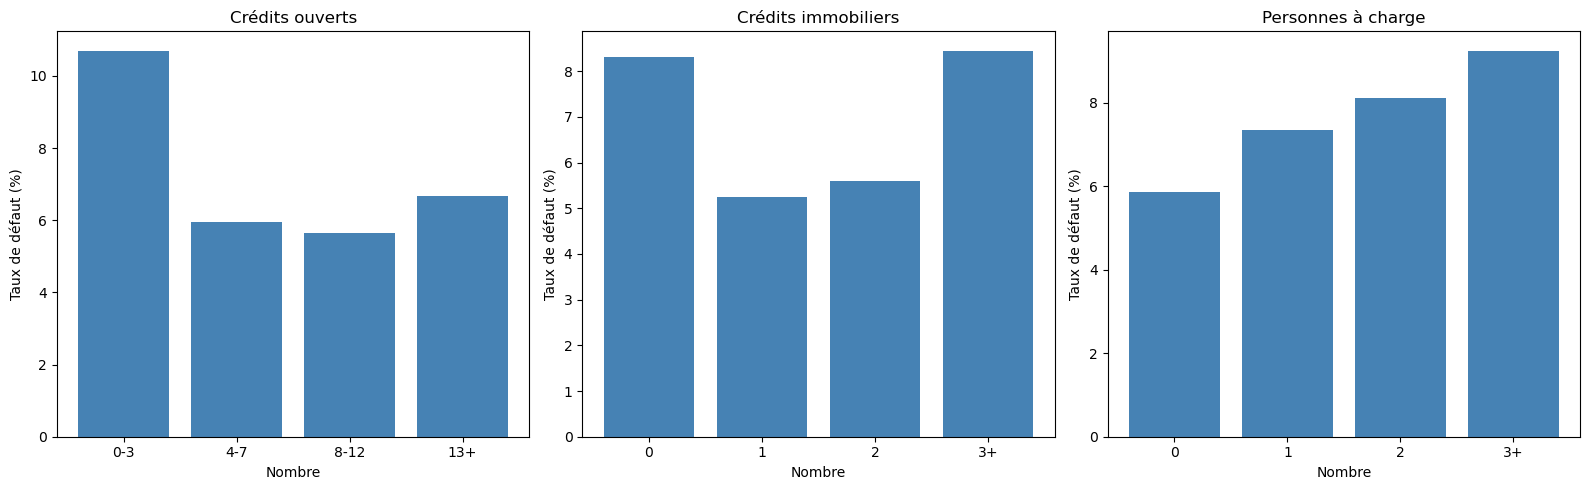

In [40]:
# Titres des trois graphiques
titres = [
    "Crédits ouverts",
    "Crédits immobiliers",
    "Personnes à charge"
]

# Création des trois graphiques
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Parcours des variables
for i, variable in enumerate(config_variables):

    # Récupération du tableau de résultats
    tableau = resultats_credits[variable]

    # Création du diagramme en barres
    axes[i].bar(
        tableau.index.astype(str),
        tableau["Taux de défaut (%)"],
        color="steelblue"
    )

    # Personnalisation du graphique
    axes[i].set_title(titres[i])
    axes[i].set_xlabel("Nombre")
    axes[i].set_ylabel("Taux de défaut (%)")

# Ajustement de l'affichage
plt.tight_layout()
plt.show()

In [41]:
# Importation du test du Khi-deux
from scipy.stats import chi2_contingency

# Parcours des trois variables
for variable, config in config_variables.items():

    # Sélection des données nécessaires
    donnees = df[[variable, "SeriousDlqin2yrs"]].copy()

    # Création des groupes
    donnees["Groupe"] = pd.cut(
        donnees[variable],
        bins=config["bins"],
        labels=config["labels"]
    )

    # Création du tableau croisé
    tableau_croise = pd.crosstab(
        donnees["Groupe"],
        donnees["SeriousDlqin2yrs"]
    )

    # Application du test du Khi-deux
    chi2, p_value, ddl, attendus = chi2_contingency(
        tableau_croise
    )

    # Calcul du V de Cramér
    n = tableau_croise.to_numpy().sum()
    k = min(tableau_croise.shape) - 1

    v_cramer = np.sqrt(chi2 / (n * k))

    # Affichage des résultats
    print("\nVariable :", variable)
    print("Khi-deux :", round(chi2, 2))
    print(f"P-value : {p_value:.3e}")
    print("V de Cramér :", round(v_cramer, 4))
    print("Effectif attendu minimum :", round(attendus.min(), 2))

    # Vérification de la significativité
    if p_value < 0.05:
        print("Association statistiquement significative.")
    else:
        print("Association non statistiquement significative.")


Variable : NumberOfOpenCreditLinesAndLoans
Khi-deux : 699.39
P-value : 2.842e-151
V de Cramér : 0.0683
Effectif attendu minimum : 1473.82
Association statistiquement significative.

Variable : NumberRealEstateLoansOrLines
Khi-deux : 521.32
P-value : 1.144e-112
V de Cramér : 0.059
Effectif attendu minimum : 665.19
Association statistiquement significative.

Variable : NumberOfDependents
Khi-deux : 313.87
P-value : 9.921e-68
V de Cramér : 0.0464
Effectif attendu minimum : 898.98
Association statistiquement significative.


#### Interprétation des résultats

D'après les résultats obtenus, je remarque que :

- **Nombre de crédits ouverts :** les clients ayant entre 0 et 3 crédits présentent le taux de défaut le plus élevé (10,70 %). Ce taux diminue pour les clients ayant entre 4 et 12 crédits, puis remonte légèrement à 6,67 % pour ceux ayant 13 crédits ou plus. La relation n'est donc pas linéaire.

- **Crédits immobiliers :** les clients sans crédit immobilier présentent un taux de défaut de 8,31 %, contre 5,25 % pour ceux ayant un seul crédit. Le taux remonte à 8,45 % chez les clients ayant au moins trois crédits immobiliers.

- **Personnes à charge :** le taux de défaut augmente progressivement avec le nombre de personnes à charge, passant de 5,86 % pour les clients sans personne à charge à 9,25 % pour ceux ayant trois personnes ou plus.

**Tests statistiques :**

Les trois tests du Khi-deux donnent des p-values très faibles, inférieures à 0,05. Je rejette donc l'hypothèse d'indépendance pour les trois variables.

Cependant, les valeurs du V de Cramér restent faibles :

- Crédits ouverts : **0,0683**
- Crédits immobiliers : **0,0590**
- Personnes à charge : **0,0464**

Ces résultats montrent que les associations sont statistiquement significatives, mais de faible intensité.

**Conclusion :** les trois variables présentent une relation avec le défaut de paiement, mais leur pouvoir explicatif individuel semble limité. Elles pourront néanmoins apporter des informations complémentaires à notre modèle de Credit Scoring lorsqu'elles seront combinées avec les autres variables financières.

### 3.4. Analyse multivariée

#### 3.4.1. Matrice de corrélation de Pearson

Dans cette étape, je vais étudier les relations linéaires
entre les différentes variables explicatives de mon dataset.

L'objectif est d'identifier les variables fortement corrélées
et de détecter les éventuels problèmes de multicolinéarité.

Pour cela, je vais calculer la matrice de corrélation
de Pearson et la visualiser avec une heatmap.

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
RevolvingUtilizationOfUnsecuredLines,1.00,-0.01,-0.00,0.00,0.01,-0.01,-0.00,0.01,-0.00,0.00
age,-0.01,1.00,-0.06,0.02,0.04,0.15,-0.06,0.03,-0.06,-0.21
NumberOfTime30-59DaysPastDueNotWorse,-0.00,-0.06,1.00,-0.01,-0.01,-0.06,0.98,-0.03,0.99,-0.00
DebtRatio,0.00,0.02,-0.01,1.00,-0.03,0.05,-0.01,0.12,-0.01,-0.04
MonthlyIncome,0.01,0.04,-0.01,-0.03,1.00,0.09,-0.01,0.12,-0.01,0.06
NumberOfOpenCreditLinesAndLoans,-0.01,0.15,-0.06,0.05,0.09,1.00,-0.08,0.43,-0.07,0.07
NumberOfTimes90DaysLate,-0.00,-0.06,0.98,-0.01,-0.01,-0.08,1.00,-0.05,0.99,-0.01
NumberRealEstateLoansOrLines,0.01,0.03,-0.03,0.12,0.12,0.43,-0.05,1.00,-0.04,0.12
NumberOfTime60-89DaysPastDueNotWorse,-0.00,-0.06,0.99,-0.01,-0.01,-0.07,0.99,-0.04,1.00,-0.01
NumberOfDependents,0.00,-0.21,-0.00,-0.04,0.06,0.07,-0.01,0.12,-0.01,1.00


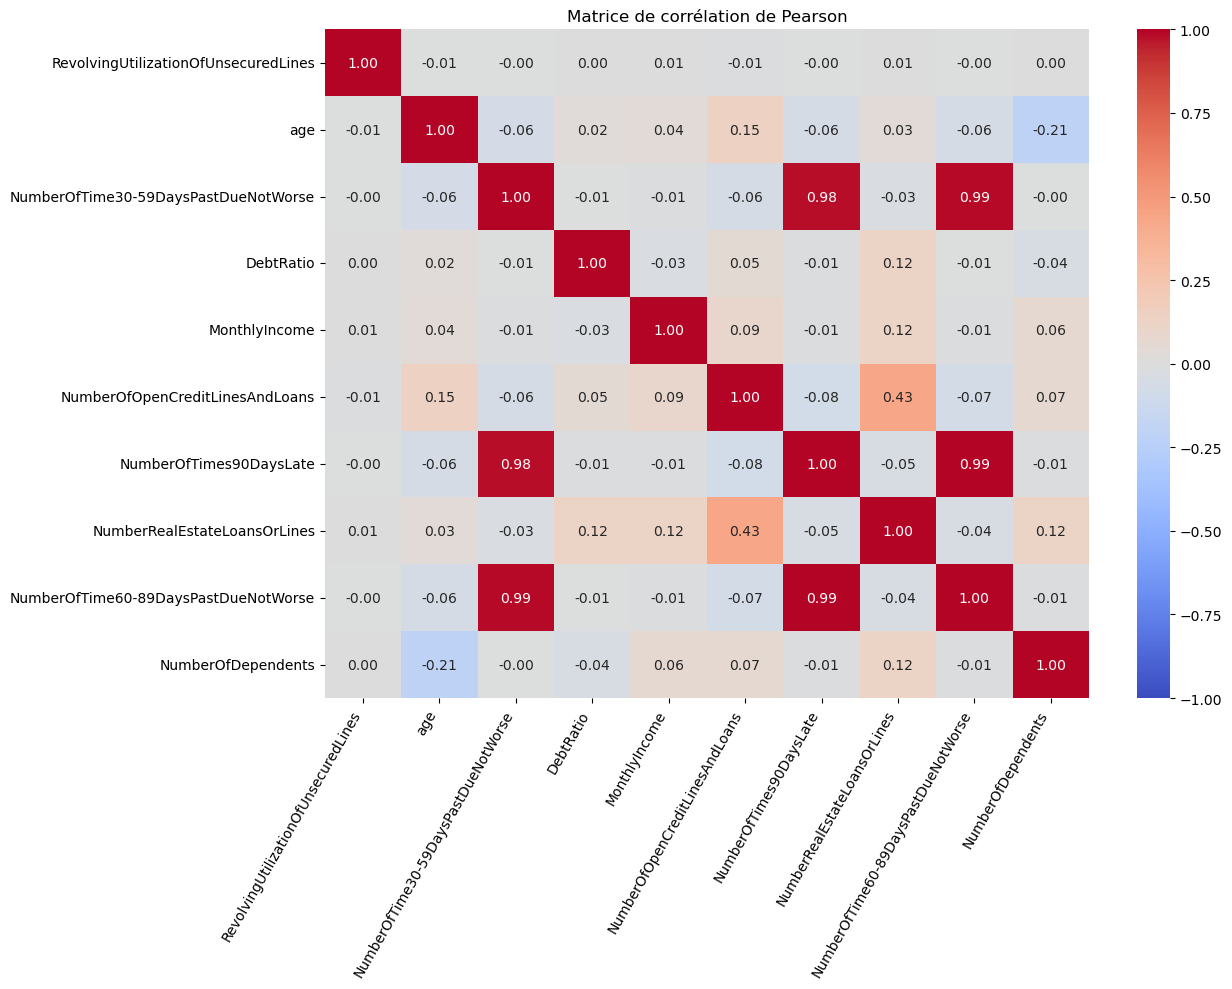

In [42]:
# Importation des bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sélection des variables explicatives
# J'exclus l'index technique et la variable cible
X_eda = df.drop(
    columns=["Unnamed: 0", "SeriousDlqin2yrs"]
).copy()

# Calcul de la matrice de corrélation de Pearson
corr_pearson = X_eda.corr(method="pearson")

# Affichage de la matrice de corrélation
display(corr_pearson.round(2))

# Création de la figure
plt.figure(figsize=(13, 10))

# Visualisation de la matrice avec une heatmap
sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

# Personnalisation du graphique
plt.title("Matrice de corrélation de Pearson")
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)

# Ajustement et affichage
plt.tight_layout()
plt.show()

#### Interprétation

D'après la matrice de corrélation de Pearson, je remarque que :

- **Retards de paiement :** les trois variables de retards présentent des corrélations positives très fortes, comprises entre **0,98 et 0,99**. Cela peut indiquer une forte dépendance linéaire entre ces variables. Cependant, ces résultats pourraient être influencés par les valeurs suspectes 96 et 98 identifiées précédemment.

- **Crédits ouverts et crédits immobiliers :** la corrélation est positive et modérée (**r = 0,43**). Les clients ayant davantage de crédits ouverts ont donc tendance à posséder également plus de crédits immobiliers.

- **Âge et personnes à charge :** la corrélation est négative et faible (**r = -0,21**). Dans notre dataset, le nombre de personnes à charge a légèrement tendance à diminuer avec l'âge.

- **Autres variables :** la majorité des coefficients sont proches de zéro, ce qui indique de faibles relations linéaires entre les variables concernées.

- **Variables financières :** `DebtRatio` et `RevolvingUtilizationOfUnsecuredLines` présentent des corrélations de Pearson très faibles avec la plupart des autres variables. Cela peut notamment être lié aux distributions fortement asymétriques et aux valeurs extrêmes observées précédemment.

**Conclusion :** cette analyse montre une forte corrélation entre les trois variables de retards de paiement, ce qui peut poser un problème de multicolinéarité lors de la Régression Logistique. Il sera nécessaire de vérifier l'influence des valeurs suspectes 96 et 98 avant de prendre une décision sur le traitement de ces variables.

Je vais également utiliser la corrélation de Spearman pour compléter cette analyse, car elle est généralement moins sensible aux valeurs extrêmes.

#### 3.4.2. Matrice de corrélation de Spearman

Dans cette étape, je vais calculer la corrélation de
Spearman afin d'étudier les relations monotones entre
les variables explicatives.

Cette méthode complète la corrélation de Pearson
et permet d'examiner les relations entre variables
sans supposer une relation linéaire.

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
RevolvingUtilizationOfUnsecuredLines,1.00,-0.28,0.23,0.08,-0.08,-0.09,0.24,-0.03,0.19,0.12
age,-0.28,1.00,-0.09,0.03,0.13,0.16,-0.10,0.05,-0.09,-0.23
NumberOfTime30-59DaysPastDueNotWorse,0.23,-0.09,1.00,0.04,-0.01,0.06,0.25,0.02,0.28,0.07
DebtRatio,0.08,0.03,0.04,1.00,-0.13,0.23,-0.03,0.40,0.00,-0.04
MonthlyIncome,-0.08,0.13,-0.01,-0.13,1.00,0.31,-0.09,0.39,-0.05,0.20
NumberOfOpenCreditLinesAndLoans,-0.09,0.16,0.06,0.23,0.31,1.00,-0.13,0.47,-0.05,0.10
NumberOfTimes90DaysLate,0.24,-0.10,0.25,-0.03,-0.09,-0.13,1.00,-0.10,0.32,0.03
NumberRealEstateLoansOrLines,-0.03,0.05,0.02,0.40,0.39,0.47,-0.10,1.00,-0.04,0.17
NumberOfTime60-89DaysPastDueNotWorse,0.19,-0.09,0.28,0.00,-0.05,-0.05,0.32,-0.04,1.00,0.04
NumberOfDependents,0.12,-0.23,0.07,-0.04,0.20,0.10,0.03,0.17,0.04,1.00


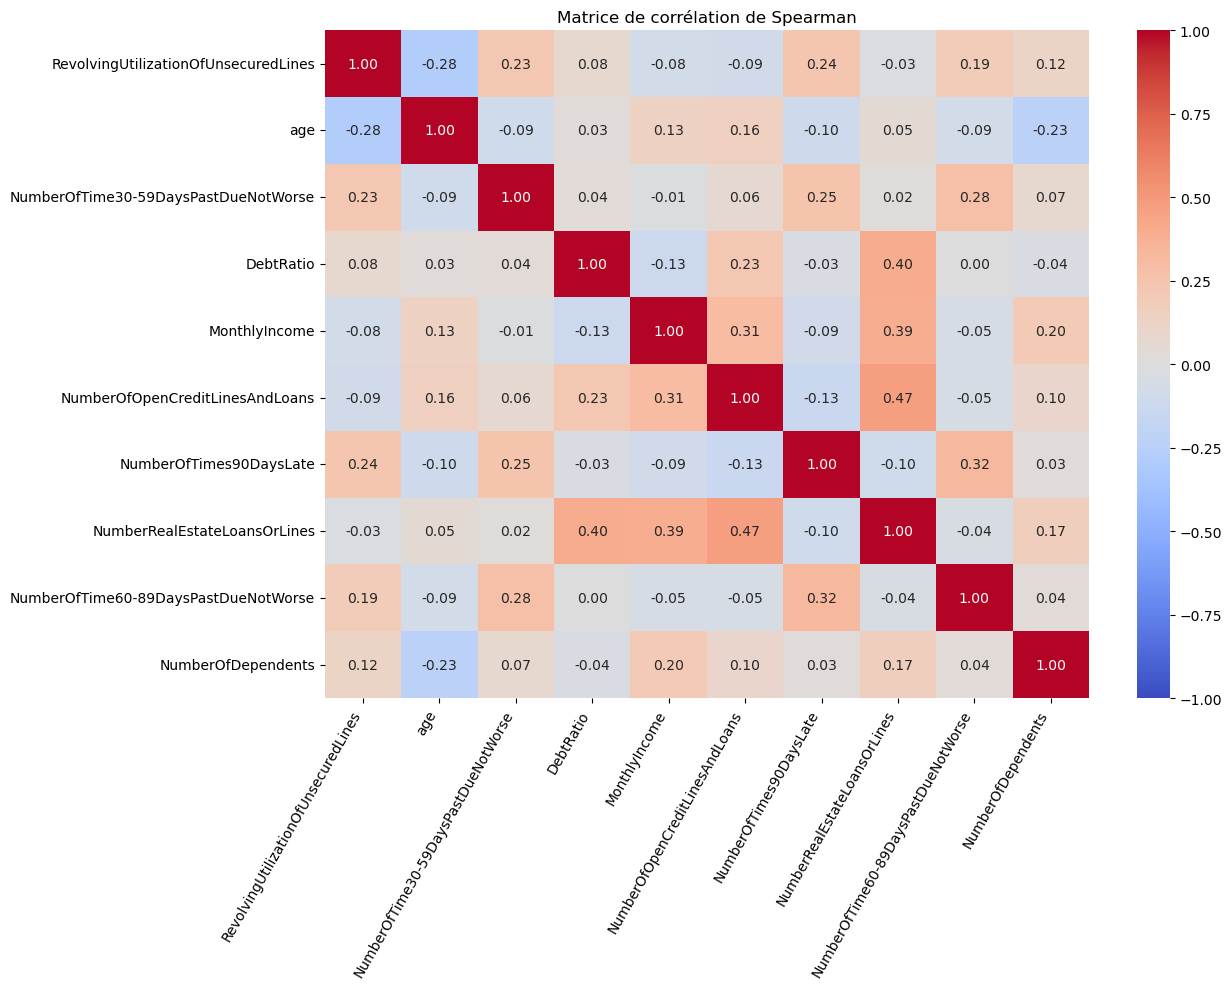

In [43]:
# Calcul de la matrice de corrélation de Spearman
corr_spearman = X_eda.corr(method="spearman")

# Affichage de la matrice
display(corr_spearman.round(2))

# Création de la figure
plt.figure(figsize=(13, 10))

# Visualisation avec une heatmap
sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

# Personnalisation du graphique
plt.title("Matrice de corrélation de Spearman")
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)

# Ajustement et affichage
plt.tight_layout()
plt.show()

#### Interprétation 

D'après la matrice de corrélation de Spearman, je remarque que :

- **Crédits ouverts et crédits immobiliers :** la corrélation positive de **0,47** indique une association monotone modérée. Les clients ayant davantage de crédits ouverts ont tendance à posséder également plus de crédits immobiliers.

- **Ratio d'endettement et crédits immobiliers :** la corrélation est positive (**0,40**), ce qui montre une tendance à l'augmentation du ratio d'endettement avec le nombre de crédits immobiliers.

- **Revenu mensuel et crédits immobiliers :** la corrélation positive de **0,39** indique que les clients ayant des revenus plus élevés ont tendance à posséder davantage de crédits immobiliers.

- **Retards de paiement :** les corrélations entre les trois catégories de retards sont comprises entre **0,25 et 0,32**, ce qui indique des associations positives, mais nettement moins fortes que celles observées avec Pearson (0,98 à 0,99).

- **Âge et utilisation du crédit :** la corrélation négative de **-0,28** montre que l'utilisation du crédit renouvelable a tendance à diminuer avec l'âge.

- **Âge et personnes à charge :** la corrélation négative de **-0,23** indique une faible tendance à la diminution du nombre de personnes à charge avec l'âge.

**Comparaison avec Pearson :**

J'ai remarqué que les trois variables de retards présentent des corrélations de Pearson très élevées (0,98 à 0,99), alors que leurs corrélations de Spearman restent beaucoup plus faibles (0,25 à 0,32).

Cette différence suggère que les valeurs extrêmes, notamment 96 et 98, pourraient influencer fortement les coefficients de Pearson.

**Conclusion :** l'analyse de Spearman met en évidence plusieurs associations entre les variables financières. Elle montre également que certaines fortes corrélations observées avec Pearson doivent être interprétées avec prudence. Il sera donc nécessaire d'étudier l'influence des valeurs suspectes avant de conclure à un problème de multicolinéarité.

#### 3.4.3. Identification des corrélations fortes

Dans cette étape, je vais identifier les paires
de variables qui présentent les corrélations les plus fortes.

L'objectif est de repérer les relations importantes
entre les caractéristiques financières des clients
et les éventuels problèmes de multicolinéarité.

Je vais comparer les coefficients de Pearson et
de Spearman pour chaque paire de variables.

In [44]:
# Importation de combinations pour créer les paires de variables
from itertools import combinations

# Liste pour stocker les corrélations
liste_correlations = []

# Parcours de toutes les paires de variables
for var1, var2 in combinations(X_eda.columns, 2):

    # Récupération des coefficients de Pearson et Spearman
    pearson = corr_pearson.loc[var1, var2]
    spearman = corr_spearman.loc[var1, var2]

    # Enregistrement des résultats
    liste_correlations.append({
        "Variable 1": var1,
        "Variable 2": var2,
        "Pearson": pearson,
        "Spearman": spearman,
        "Spearman absolu": abs(spearman)
    })

# Création du tableau des corrélations
tableau_correlations = pd.DataFrame(liste_correlations)

# Classement des paires selon la force de Spearman
top_correlations = tableau_correlations.sort_values(
    by="Spearman absolu",
    ascending=False
).head(10)

# Affichage des 10 corrélations les plus fortes
display(top_correlations.round(3))

# Identification des fortes corrélations linéaires
# Le seuil de 0.70 est utilisé comme indicateur exploratoire
correlations_fortes = tableau_correlations[
    tableau_correlations["Pearson"].abs() >= 0.70
]

print("Nombre de paires avec |Pearson| >= 0.70 :",
      len(correlations_fortes))

# Affichage des paires concernées
display(correlations_fortes.round(3))

,Variable 1,Variable 2,Pearson,Spearman,Spearman absolu
36,NumberOfOpenCreditLinesAndLoans,NumberRealEstateLoansOrLines,0.434,0.473,0.473
27,DebtRatio,NumberRealEstateLoansOrLines,0.120,0.400,0.400
32,MonthlyIncome,NumberRealEstateLoansOrLines,0.125,0.391,0.391
40,NumberOfTimes90DaysLate,NumberOfTime60-89DaysPastDueNotWorse,0.993,0.321,0.321
30,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,0.091,0.312,0.312
22,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,0.987,0.280,0.280
0,RevolvingUtilizationOfUnsecuredLines,age,-0.006,-0.278,0.278
20,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTimes90DaysLate,0.984,0.253,0.253
5,RevolvingUtilizationOfUnsecuredLines,NumberOfTimes90DaysLate,-0.001,0.238,0.238
1,RevolvingUtilizationOfUnsecuredLines,NumberOfTime30-59DaysPastDueNotWorse,-0.001,0.234,0.234


Nombre de paires avec |Pearson| >= 0.70 : 3


,Variable 1,Variable 2,Pearson,Spearman,Spearman absolu
20,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTimes90DaysLate,0.984,0.253,0.253
22,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,0.987,0.280,0.280
40,NumberOfTimes90DaysLate,NumberOfTime60-89DaysPastDueNotWorse,0.993,0.321,0.321


#### Interprétation 

D'après les résultats obtenus, je remarque que :

- **Crédits ouverts et crédits immobiliers :** cette paire présente la corrélation de Spearman la plus élevée (**0,473**), ce qui indique une association positive modérée entre les deux variables.

- **Ratio d'endettement et crédits immobiliers :** la corrélation de Spearman est de **0,400**, ce qui montre une association positive entre ces deux variables.

- **Revenu mensuel et crédits immobiliers :** la corrélation de Spearman est de **0,391**, indiquant que les clients ayant des revenus plus élevés ont tendance à posséder davantage de crédits immobiliers.

- **Retards de paiement :** j'ai identifié trois paires présentant des corrélations de Pearson très fortes, comprises entre **0,984 et 0,993**. Cependant, leurs corrélations de Spearman sont beaucoup plus faibles, entre **0,253 et 0,321**.

- **Multicolinéarité :** les trois paires de variables de retards dépassent le seuil exploratoire de 0,70 selon Pearson. Cela peut indiquer un problème de multicolinéarité, mais les valeurs suspectes 96 et 98 pourraient fortement influencer ces résultats.

**Conclusion :** cette analyse met en évidence plusieurs associations entre les variables financières. Les corrélations les plus fortes selon Pearson concernent les retards de paiement, mais elles doivent être vérifiées avant la modélisation.

Je vais donc examiner l'influence des valeurs suspectes 96 et 98 avant de décider si ces variables nécessitent un traitement particulier.

#### 3.4.4. Influence des valeurs suspectes sur les corrélations

Dans cette étape, je vais étudier l'influence des
valeurs suspectes 96 et 98 sur les corrélations
entre les variables de retards de paiement.

L'objectif est de comparer les coefficients obtenus
avec toutes les observations et ceux obtenus après
une exclusion temporaire de ces valeurs.

Cette analyse permettra de vérifier la sensibilité
des corrélations aux observations inhabituelles.

In [45]:
# Sélection des trois variables de retards
variables_retards = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

# Identification des observations contenant 96 ou 98
# dans au moins une variable de retard
masque_suspects = df[variables_retards].isin([96, 98]).any(axis=1)

# Affichage du nombre d'observations suspectes
print("Observations suspectes :", masque_suspects.sum())

# Création d'une copie sans ces observations
# Cette exclusion est provisoire et concerne uniquement l'EDA
df_sans_suspects = df.loc[~masque_suspects].copy()

# Liste pour comparer les corrélations
comparaison_corr = []

# Parcours des paires de variables de retards
for var1, var2 in combinations(variables_retards, 2):

    # Corrélation de Pearson sur les données originales
    pearson_avant = df[[var1, var2]].corr(
        method="pearson"
    ).iloc[0, 1]

    # Corrélation après exclusion temporaire
    pearson_apres = df_sans_suspects[[var1, var2]].corr(
        method="pearson"
    ).iloc[0, 1]

    # Corrélation de Spearman sur les données originales
    spearman_avant = df[[var1, var2]].corr(
        method="spearman"
    ).iloc[0, 1]

    # Corrélation de Spearman après exclusion temporaire
    spearman_apres = df_sans_suspects[[var1, var2]].corr(
        method="spearman"
    ).iloc[0, 1]

    # Enregistrement des résultats
    comparaison_corr.append({
        "Variable 1": var1,
        "Variable 2": var2,
        "Pearson avant": pearson_avant,
        "Pearson après": pearson_apres,
        "Spearman avant": spearman_avant,
        "Spearman après": spearman_apres
    })

# Création et affichage du tableau comparatif
comparaison_corr = pd.DataFrame(comparaison_corr)

display(comparaison_corr.round(3))

Observations suspectes : 269


,Variable 1,Variable 2,Pearson avant,Pearson après,Spearman avant,Spearman après
0,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,0.987,0.306,0.280,0.264
1,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTimes90DaysLate,0.984,0.218,0.253,0.237
2,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,0.993,0.295,0.321,0.296


#### Interprétation 

D'après les résultats obtenus, je remarque que :

- **Valeurs suspectes :** j'ai identifié 269 observations contenant les valeurs 96 ou 98, soit environ 0,18 % du dataset.

- **Corrélation de Pearson :** avant l'exclusion de ces observations, les corrélations entre les trois variables de retards étaient très élevées (entre 0,984 et 0,993). Après leur exclusion temporaire, elles diminuent fortement et se situent entre 0,218 et 0,306.

- **Corrélation de Spearman :** les coefficients diminuent légèrement après l'exclusion, passant de 0,253–0,321 à 0,237–0,296. Cette différence montre que Spearman est moins sensible à ces valeurs extrêmes.

- **Multicolinéarité :** les corrélations de Pearson proches de 1 étaient donc principalement influencées par les observations suspectes. Après leur exclusion, aucune des trois paires ne présente de forte corrélation linéaire selon le seuil de 0,70 utilisé.

**Conclusion :** cette analyse montre que les valeurs 96 et 98 influencent fortement les corrélations entre les variables de retards de paiement. Il sera donc nécessaire d'examiner leur signification et de définir un traitement adapté pendant la phase de préparation des données, sans les supprimer automatiquement.

#### 3.4.5. Corrélation des variables explicatives avec la cible

Dans cette étape, je vais mesurer les corrélations
entre les variables explicatives et la variable cible
SeriousDlqin2yrs.

L'objectif est d'identifier les caractéristiques
financières qui présentent les associations les plus
marquées avec le défaut de paiement.

Je vais comparer les corrélations de Pearson
et de Spearman, puis visualiser les résultats.

,Pearson,Spearman
NumberOfTimes90DaysLate,0.117,0.342
NumberOfTime60-89DaysPastDueNotWorse,0.102,0.277
NumberOfTime30-59DaysPastDueNotWorse,0.126,0.257
RevolvingUtilizationOfUnsecuredLines,-0.002,0.240
age,-0.115,-0.117
MonthlyIncome,-0.020,-0.067
NumberOfDependents,0.046,0.046
NumberOfOpenCreditLinesAndLoans,-0.030,-0.039
NumberRealEstateLoansOrLines,-0.007,-0.034
DebtRatio,-0.008,0.021


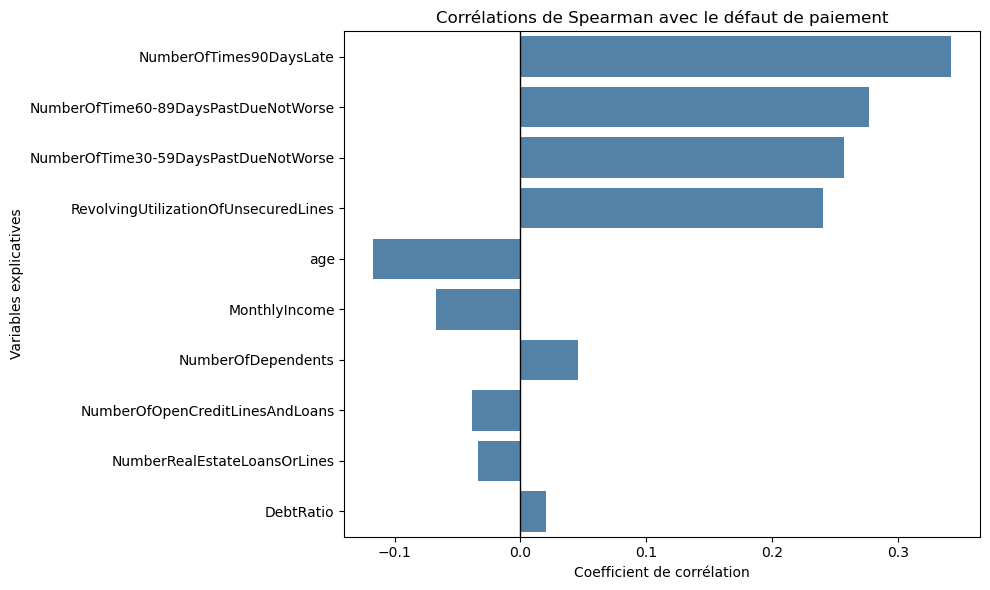

In [46]:
# Sélection des variables explicatives et de la cible
donnees_corr = df.drop(columns=["Unnamed: 0"])

# Calcul des corrélations de Pearson avec la cible
pearson_cible = donnees_corr.corr(
    method="pearson"
)["SeriousDlqin2yrs"].drop("SeriousDlqin2yrs")

# Calcul des corrélations de Spearman avec la cible
spearman_cible = donnees_corr.corr(
    method="spearman"
)["SeriousDlqin2yrs"].drop("SeriousDlqin2yrs")

# Création du tableau comparatif
correlations_cible = pd.DataFrame({
    "Pearson": pearson_cible,
    "Spearman": spearman_cible
})

# Classement selon la valeur absolue de Spearman
correlations_cible = correlations_cible.reindex(
    spearman_cible.abs().sort_values(
        ascending=False
    ).index
)

# Affichage du tableau
display(correlations_cible.round(3))

# Création du graphique
plt.figure(figsize=(10, 6))

# Visualisation des corrélations de Spearman
sns.barplot(
    x=correlations_cible["Spearman"].values,
    y=correlations_cible.index,
    color="steelblue"
)

# Ajout d'une ligne verticale à zéro
plt.axvline(0, color="black", linewidth=1)

# Personnalisation du graphique
plt.title("Corrélations de Spearman avec le défaut de paiement")
plt.xlabel("Coefficient de corrélation")
plt.ylabel("Variables explicatives")

plt.tight_layout()
plt.show()

#### Interprétation des résultats

D'après les résultats obtenus, je remarque que :

- **Retards de paiement :** les trois variables de retards présentent les corrélations positives les plus importantes avec le défaut de paiement. La variable `NumberOfTimes90DaysLate` possède le coefficient de Spearman le plus élevé (**0,342**), suivie des retards de 60–89 jours (**0,277**) et de 30–59 jours (**0,257**).

- **Utilisation du crédit renouvelable :** cette variable présente une corrélation positive de **0,240** selon Spearman, contre une corrélation de Pearson proche de zéro (-0,002). Cette différence peut notamment s'expliquer par la présence de valeurs extrêmes.

- **Âge :** la corrélation est négative (**-0,117**), ce qui indique que les clients plus âgés ont globalement tendance à présenter moins de défauts de paiement dans notre dataset.

- **Revenu mensuel :** la corrélation de Spearman est négative et faible (**-0,067**). Les revenus plus élevés ont donc une légère tendance à être associés à l'absence de défaut.

- **Autres variables :** le nombre de personnes à charge (0,046), les crédits ouverts (-0,039), les crédits immobiliers (-0,034) et le ratio d'endettement (0,021) présentent des corrélations faibles avec la cible.

**Comparaison entre Pearson et Spearman :**

Les deux méthodes donnent des résultats différents pour certaines variables, notamment l'utilisation du crédit renouvelable. Cette différence montre l'importance de tenir compte des distributions asymétriques et des valeurs extrêmes.

**Conclusion :** les retards de paiement et l'utilisation du crédit renouvelable présentent les associations monotones les plus marquées avec le défaut de paiement. Ces variables semblent donc particulièrement intéressantes pour notre futur modèle de Credit Scoring.

Cependant, une faible corrélation ne signifie pas qu'une variable est inutile. Nous conserverons les variables candidates pour évaluer leur contribution réelle pendant la modélisation.

#### 3.4.6. Analyse combinée de l'âge, de l'utilisation du crédit et du défaut

Dans cette étape, je vais étudier simultanément
l'âge, le taux d'utilisation du crédit et le défaut
de paiement.

L'objectif est de vérifier si les taux de défaut
varient selon les différentes combinaisons de
tranches d'âge et de niveaux d'utilisation du crédit.

Pour cela, je vais construire un tableau croisé
des taux de défaut et le visualiser avec une heatmap.

Taux de défaut (%) :


Utilisation,0-20%,20-50%,50-80%,80-100%
Tranche_age,,,,
18-34,3.40,6.13,11.44,20.69
35-49,2.56,5.27,12.12,20.86
50-64,1.95,4.81,9.95,17.19
65+,1.18,3.46,7.54,8.97


Nombre de clients :


Utilisation,0-20%,20-50%,50-80%,80-100%
Tranche_age,,,,
18-34,7090,3524,2553,5190
35-49,21502,9699,6311,8261
50-64,29694,10056,5566,6253
65+,23423,3724,1725,2107


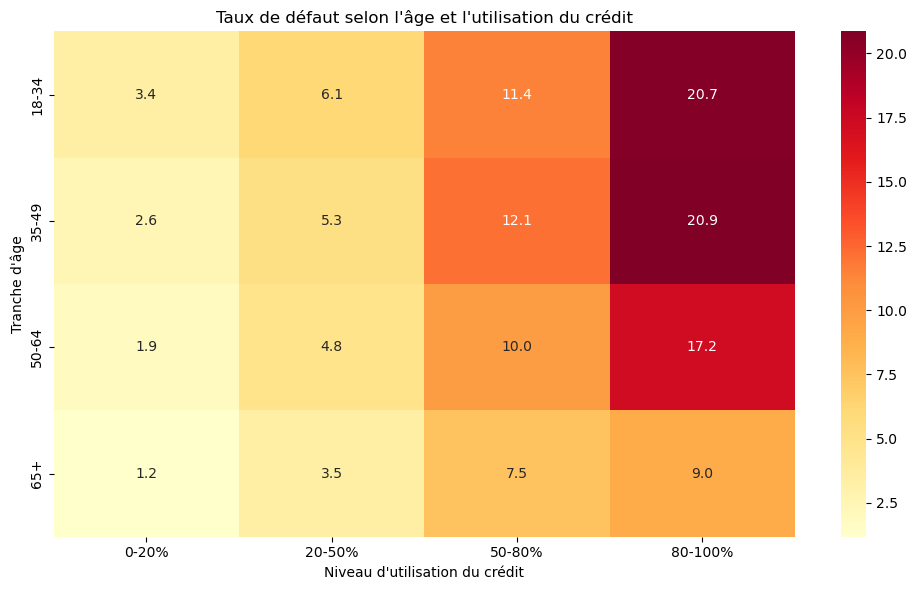

In [47]:
# Sélection des variables nécessaires
# On limite cette visualisation aux âges adultes
# et aux taux d'utilisation compris entre 0 et 1
# Le dataset original reste inchangé
donnees_multi = df.loc[
    df["age"].between(18, 109) &
    df["RevolvingUtilizationOfUnsecuredLines"].between(0, 1),
    [
        "age",
        "RevolvingUtilizationOfUnsecuredLines",
        "SeriousDlqin2yrs"
    ]
].copy()

# Création des tranches d'âge
donnees_multi["Tranche_age"] = pd.cut(
    donnees_multi["age"],
    bins=[17, 34, 49, 64, np.inf],
    labels=["18-34", "35-49", "50-64", "65+"]
)

# Création des catégories d'utilisation du crédit
donnees_multi["Utilisation"] = pd.cut(
    donnees_multi["RevolvingUtilizationOfUnsecuredLines"],
    bins=[-0.001, 0.20, 0.50, 0.80, 1.0],
    labels=["0-20%", "20-50%", "50-80%", "80-100%"]
)

# Calcul des effectifs et du taux de défaut
resultats_multi = donnees_multi.groupby(
    ["Tranche_age", "Utilisation"],
    observed=False
)["SeriousDlqin2yrs"].agg(["size", "mean"])

# Création du tableau des taux de défaut
taux_defaut_multi = (
    resultats_multi["mean"].unstack() * 100
)

# Création du tableau des effectifs
effectifs_multi = resultats_multi["size"].unstack()

# Affichage des résultats
print("Taux de défaut (%) :")
display(taux_defaut_multi.round(2))

print("Nombre de clients :")
display(effectifs_multi)

# Masquage des groupes contenant moins de 100 clients
# pour éviter de surinterpréter de petits effectifs
taux_affiches = taux_defaut_multi.mask(
    effectifs_multi < 100
)

# Création de la heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    taux_affiches,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

# Personnalisation du graphique
plt.title("Taux de défaut selon l'âge et l'utilisation du crédit")
plt.xlabel("Niveau d'utilisation du crédit")
plt.ylabel("Tranche d'âge")

plt.tight_layout()
plt.show()

#### Interprétation 
D'après les résultats obtenus, je remarque que :

- **Utilisation du crédit :** le taux de défaut augmente progressivement avec le niveau d'utilisation du crédit renouvelable, quelle que soit la tranche d'âge. Par exemple, chez les clients de 18 à 34 ans, il passe de 3,40 % pour une utilisation de 0 à 20 % à 20,69 % pour une utilisation de 80 à 100 %.

- **Influence de l'âge :** les clients les plus âgés présentent généralement des taux de défaut plus faibles. Pour une utilisation du crédit entre 80 et 100 %, le taux de défaut est de 20,86 % chez les 35–49 ans, contre 8,97 % chez les 65 ans et plus.

- **Combinaison des variables :** les taux de défaut les plus élevés sont observés chez les clients de 18 à 49 ans utilisant entre 80 et 100 % de leur crédit disponible, avec des taux proches de 21 %.

- **Clients à faible risque observé :** les clients de 65 ans et plus utilisant moins de 20 % de leur crédit présentent le taux de défaut le plus faible, soit 1,18 %.

- **Effectifs :** les différentes combinaisons contiennent des effectifs suffisants pour cette analyse descriptive, avec au minimum 1 725 clients par groupe.

**Conclusion :** cette analyse montre que l'âge et le taux d'utilisation du crédit sont conjointement associés au défaut de paiement. Une utilisation élevée du crédit correspond à des taux de défaut plus importants, particulièrement chez les clients de moins de 50 ans.

Ces résultats suggèrent que les deux variables pourraient apporter des informations complémentaires à notre modèle de Credit Scoring. Cependant, les associations observées ne prouvent pas de relation causale.

## Tâche 4 : Vérification de la qualité des données

### 4.1. Vérification de la complétude des données

Dans cette étape, je vais analyser les valeurs manquantes
de mon dataset afin d'évaluer sa complétude.

L'objectif est d'identifier les variables concernées,
de calculer le nombre et le pourcentage des valeurs
manquantes et de visualiser leur répartition.

Cette analyse me permettra de déterminer les problèmes
à traiter lors de la phase de préparation des données.

In [48]:
# Calcul du nombre de valeurs manquantes par variable
valeurs_manquantes = df.isnull().sum()

# Calcul du pourcentage de valeurs manquantes
pourcentage_manquant = df.isnull().mean() * 100

# Calcul du nombre de valeurs présentes
valeurs_presentes = df.notnull().sum()

# Création d'un tableau récapitulatif
rapport_completude = pd.DataFrame({
    "Valeurs présentes": valeurs_presentes,
    "Valeurs manquantes": valeurs_manquantes,
    "Pourcentage manquant (%)": pourcentage_manquant
})

# Classement des variables par pourcentage de valeurs manquantes
rapport_completude = rapport_completude.sort_values(
    by="Pourcentage manquant (%)",
    ascending=False
)

# Affichage du rapport de complétude
display(rapport_completude.round(2))

# Calcul du nombre de lignes contenant au moins une valeur manquante
lignes_incompletes = df.isnull().any(axis=1).sum()

# Calcul du pourcentage de lignes incomplètes
pourcentage_lignes = (lignes_incompletes / len(df)) * 100

# Affichage des résultats globaux
print("\nNombre de lignes incomplètes :", lignes_incompletes)
print("Pourcentage de lignes incomplètes :",
      round(pourcentage_lignes, 2), "%")

,Valeurs présentes,Valeurs manquantes,Pourcentage manquant (%)
MonthlyIncome,120269,29731,19.82
NumberOfDependents,146076,3924,2.62
Unnamed: 0,150000,0,0.00
SeriousDlqin2yrs,150000,0,0.00
age,150000,0,0.00
RevolvingUtilizationOfUnsecuredLines,150000,0,0.00
DebtRatio,150000,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,150000,0,0.00
NumberOfOpenCreditLinesAndLoans,150000,0,0.00
NumberOfTimes90DaysLate,150000,0,0.00



Nombre de lignes incomplètes : 29731
Pourcentage de lignes incomplètes : 19.82 %


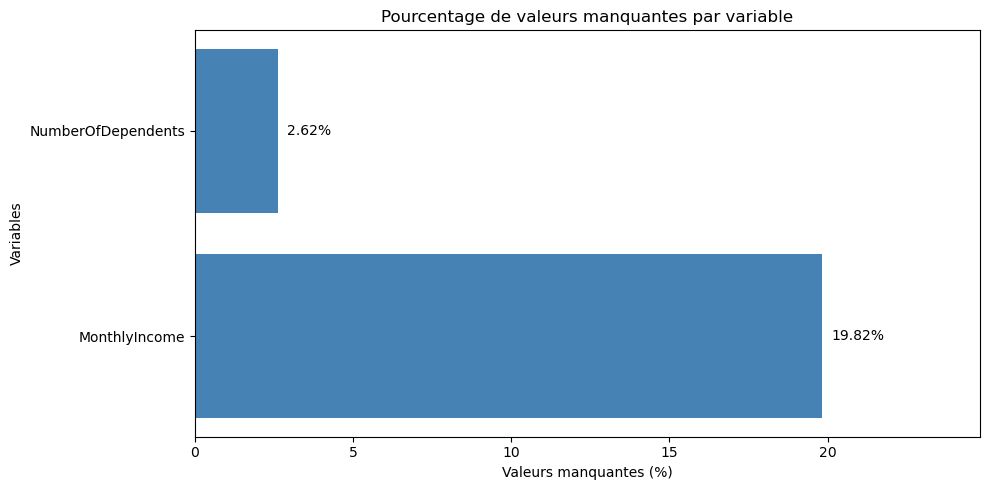

In [49]:
# Sélection des variables ayant des valeurs manquantes
variables_incompletes = rapport_completude[
    rapport_completude["Valeurs manquantes"] > 0
]

# Création de la figure
plt.figure(figsize=(10, 5))

# Création du diagramme en barres horizontales
plt.barh(
    variables_incompletes.index,
    variables_incompletes["Pourcentage manquant (%)"],
    color="steelblue"
)

# Ajout des pourcentages sur les barres
for i, valeur in enumerate(
    variables_incompletes["Pourcentage manquant (%)"]
):
    plt.text(
        valeur + 0.3,
        i,
        f"{valeur:.2f}%",
        va="center"
    )

# Personnalisation du graphique
plt.title("Pourcentage de valeurs manquantes par variable")
plt.xlabel("Valeurs manquantes (%)")
plt.ylabel("Variables")

# Limitation de l'axe horizontal
plt.xlim(
    0,
    variables_incompletes["Pourcentage manquant (%)"].max() + 5
)

# Ajustement et affichage
plt.tight_layout()
plt.show()

### Interprétation

D'après les résultats obtenus, je remarque que :

- **MonthlyIncome** contient 29 731 valeurs manquantes, soit **19,82 %** des données.
- **NumberOfDependents** contient 3 924 valeurs manquantes, soit **2,62 %**.
- Les autres variables ne présentent aucune valeur manquante.
- Au total, **29 731 clients (19,82 %)** ont au moins une information manquante.

**Conclusion :** mon dataset présente principalement un problème de valeurs manquantes dans la variable `MonthlyIncome`. Je devrai donc choisir une méthode adaptée pour traiter ces valeurs pendant la phase de préparation des données, sans supprimer directement les clients concernés.

### 4.2. Vérification de l'exactitude des données

Dans cette étape, je vais rechercher les valeurs incorrectes
ou suspectes dans mon dataset.

Je vais analyser les valeurs minimales et maximales,
identifier les âges impossibles et examiner les valeurs
extrêmes des variables financières et des retards de paiement.

L'objectif est de détecter les anomalies avant de choisir
une méthode de traitement pendant la préparation des données.

In [50]:
# Sélection des variables à examiner
colonnes_verification = [
    "age",
    "MonthlyIncome",
    "DebtRatio",
    "RevolvingUtilizationOfUnsecuredLines",
    "NumberOfDependents",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines"
]

# Création d'un tableau de diagnostic
rapport_exactitude = pd.DataFrame({
    "Minimum": df[colonnes_verification].min(),
    "Médiane": df[colonnes_verification].median(),
    "99e percentile": df[colonnes_verification].quantile(0.99),
    "Maximum": df[colonnes_verification].max(),
    "Valeurs négatives": (df[colonnes_verification] < 0).sum()
})

# Affichage du tableau
display(rapport_exactitude.round(2))

,Minimum,Médiane,99e percentile,Maximum,Valeurs négatives
age,0.0,52.00,87.00,109.0,0
MonthlyIncome,0.0,5400.00,25000.00,3008750.0,0
DebtRatio,0.0,0.37,4979.04,329664.0,0
RevolvingUtilizationOfUnsecuredLines,0.0,0.15,1.09,50708.0,0
NumberOfDependents,0.0,0.00,4.00,20.0,0
NumberOfOpenCreditLinesAndLoans,0.0,8.00,24.00,58.0,0
NumberRealEstateLoansOrLines,0.0,1.00,4.00,54.0,0


In [51]:
# Identification des clients ayant un âge inférieur ou égal à zéro
ages_invalides = df[df["age"] <= 0]

# Identification des clients ayant plus de 100 ans
ages_extremes = df[df["age"] > 100]

# Affichage des résultats
print("Nombre de clients avec âge <= 0 :", len(ages_invalides))
print("Nombre de clients avec âge > 100 :", len(ages_extremes))

# Affichage des observations ayant un âge invalide
display(ages_invalides[["age", "SeriousDlqin2yrs"]].head(10))

# Affichage des âges supérieurs à 100 ans
display(ages_extremes[["age", "SeriousDlqin2yrs"]].head(10))

Nombre de clients avec âge <= 0 : 1
Nombre de clients avec âge > 100 : 13


,age,SeriousDlqin2yrs
65695,0,0


,age,SeriousDlqin2yrs
7763,101,0
19884,103,0
25561,102,0
40007,107,0
56761,105,0
57967,103,0
90937,102,0
93813,101,0
96450,102,0
105790,109,0


In [52]:
# Sélection des trois variables de retards de paiement
colonnes_retards = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

# Comptage des valeurs 96 et 98 par variable
rapport_retards = pd.DataFrame({
    "Valeur 96": (df[colonnes_retards] == 96).sum(),
    "Valeur 98": (df[colonnes_retards] == 98).sum()
})

# Ajout du nombre total de valeurs suspectes par variable
rapport_retards["Total suspect"] = (
    rapport_retards["Valeur 96"] + rapport_retards["Valeur 98"]
)

# Affichage du rapport
display(rapport_retards)

# Identification des observations contenant 96 ou 98
masque_suspect = df[colonnes_retards].isin([96, 98])

# Nombre de clients ayant au moins une valeur suspecte
nombre_suspects = masque_suspect.any(axis=1).sum()

# Nombre de clients ayant une valeur suspecte dans les trois variables
nombre_trois_variables = masque_suspect.all(axis=1).sum()

print("Clients avec au moins une valeur suspecte :", nombre_suspects)
print("Clients concernés dans les trois variables :", nombre_trois_variables)

# Affichage de quelques observations suspectes
display(
    df.loc[
        masque_suspect.any(axis=1),
        colonnes_retards + ["SeriousDlqin2yrs"]
    ].head(10)
)

,Valeur 96,Valeur 98,Total suspect
NumberOfTime30-59DaysPastDueNotWorse,5,264,269
NumberOfTime60-89DaysPastDueNotWorse,5,264,269
NumberOfTimes90DaysLate,5,264,269


Clients avec au moins une valeur suspecte : 269
Clients concernés dans les trois variables : 269


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,SeriousDlqin2yrs
1733,98,98,98,1
2286,98,98,98,0
3884,98,98,98,0
4417,98,98,98,0
4705,98,98,98,0
5073,98,98,98,0
6280,98,98,98,1
7032,98,98,98,1
7117,98,98,98,1
7687,98,98,98,1


### Interprétation

D'après les résultats obtenus, je remarque que :

- **Âge :** j'ai trouvé un client avec un âge de 0 an, ce qui représente une valeur incorrecte. J'ai également identifié 13 clients âgés de plus de 100 ans, qui nécessitent une vérification.

- **Revenu mensuel :** la valeur maximale atteint **3 008 750**, alors que 99 % des revenus disponibles ne dépassent pas 25 000. Cela montre la présence de valeurs extrêmement élevées.

- **Variables financières :** `DebtRatio` atteint 329 664 et `RevolvingUtilizationOfUnsecuredLines` atteint 50 708. Ces valeurs sont très éloignées des valeurs habituelles et nécessitent une analyse.

- **Autres variables :** le nombre de personnes à charge atteint 20 et le nombre de crédits immobiliers atteint 54. Ces valeurs sont inhabituelles et méritent également une vérification.

- **Valeurs négatives :** aucune valeur négative n'a été détectée dans les variables analysées.

- **Retards de paiement :** j'ai identifié **269 clients** présentant des valeurs suspectes : 5 avec la valeur 96 et 264 avec la valeur 98. Ces valeurs apparaissent simultanément dans les trois variables de retards.

**Conclusion :** mon dataset contient plusieurs valeurs extrêmes et suspectes qui peuvent influencer les analyses statistiques et les performances du modèle. Je devrai donc définir un traitement adapté pendant la phase de préparation des données, sans supprimer automatiquement toutes les valeurs extrêmes.

### 4.3. Vérification de la cohérence des données

Dans cette étape, je vais vérifier la cohérence entre
plusieurs variables de mon dataset.

Je vais rechercher les contradictions possibles entre
le nombre total de crédits et les crédits immobiliers,
examiner les valeurs suspectes des retards de paiement
et analyser la relation entre les valeurs manquantes.

L'objectif est d'identifier les incohérences potentielles
avant la préparation des données.

In [53]:
# Identification des clients dont les crédits immobiliers
# dépassent le nombre total de crédits ouverts
incoherence_credits = df[
    df["NumberRealEstateLoansOrLines"] >
    df["NumberOfOpenCreditLinesAndLoans"]
]

# Calcul du nombre de clients concernés
nombre_incoherences = len(incoherence_credits)

# Calcul du pourcentage
pourcentage_incoherences = nombre_incoherences / len(df) * 100

# Affichage des résultats
print("Nombre d'incohérences potentielles :", nombre_incoherences)
print("Pourcentage :", round(pourcentage_incoherences, 2), "%")

# Affichage de quelques observations
display(
    incoherence_credits[
        [
            "NumberOfOpenCreditLinesAndLoans",
            "NumberRealEstateLoansOrLines"
        ]
    ].head(10)
)

Nombre d'incohérences potentielles : 0
Pourcentage : 0.0 %


,NumberOfOpenCreditLinesAndLoans,NumberRealEstateLoansOrLines


In [54]:
# Sélection des variables de retards
colonnes_retards = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

# Identification des lignes contenant 96 ou 98
masque_suspect = df[colonnes_retards].isin([96, 98]).any(axis=1)

# Sélection des observations suspectes
retards_suspects = df.loc[masque_suspect, colonnes_retards]

# Vérification si les trois valeurs sont identiques
valeurs_identiques = retards_suspects.nunique(axis=1) == 1

# Affichage des résultats
print("Nombre de clients suspects :", len(retards_suspects))

print(
    "Clients avec les trois valeurs identiques :",
    valeurs_identiques.sum()
)

print(
    "Clients avec des valeurs différentes :",
    (~valeurs_identiques).sum()
)

# Affichage des combinaisons de valeurs observées
print("\nCombinaisons observées :")
display(retards_suspects.value_counts().reset_index(name="Effectif"))


Nombre de clients suspects : 269
Clients avec les trois valeurs identiques : 269
Clients avec des valeurs différentes : 0

Combinaisons observées :


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,Effectif
0,98,98,98,264
1,96,96,96,5


In [55]:
# Identification des revenus manquants
revenu_manquant = df["MonthlyIncome"].isna()

# Identification des nombres de personnes à charge manquants
dependants_manquants = df["NumberOfDependents"].isna()

# Calcul des différentes situations
rapport_manquants = pd.DataFrame({
    "Situation": [
        "Revenu et dépendants manquants",
        "Revenu manquant uniquement",
        "Dépendants manquants uniquement",
        "Aucune des deux valeurs manquante"
    ],
    "Nombre de clients": [
        (revenu_manquant & dependants_manquants).sum(),
        (revenu_manquant & ~dependants_manquants).sum(),
        (~revenu_manquant & dependants_manquants).sum(),
        (~revenu_manquant & ~dependants_manquants).sum()
    ]
})

# Calcul des pourcentages
rapport_manquants["Pourcentage (%)"] = (
    rapport_manquants["Nombre de clients"] / len(df) * 100
)

# Affichage
display(rapport_manquants.round(2))

,Situation,Nombre de clients,Pourcentage (%)
0,Revenu et dépendants manquants,3924,2.62
1,Revenu manquant uniquement,25807,17.20
2,Dépendants manquants uniquement,0,0.00
3,Aucune des deux valeurs manquante,120269,80.18


### Interprétation 
D'après les résultats obtenus, je remarque que :

- **Cohérence des crédits :** aucune incohérence n'a été détectée. Le nombre de crédits immobiliers ne dépasse jamais le nombre total de crédits ouverts.

- **Retards de paiement :** les 269 clients suspects présentent exactement les mêmes valeurs dans les trois variables de retards : 264 clients avec la valeur 98 et 5 clients avec la valeur 96. Cela suggère que ces valeurs pourraient correspondre à des codes particuliers.

- **Valeurs manquantes :** 3 924 clients ont à la fois le revenu mensuel et le nombre de personnes à charge manquants. De plus, 25 807 clients ont uniquement le revenu manquant.

- **Relation entre les valeurs manquantes :** tous les clients dont le nombre de personnes à charge est manquant ont également un revenu manquant. Cela montre que les deux types de valeurs manquantes ne sont pas répartis indépendamment.

- **Données complètes :** 120 269 clients, soit **80,18 % du dataset**, ne présentent aucune valeur manquante.

**Conclusion :** les vérifications n'ont révélé aucune contradiction entre les nombres de crédits. Cependant, les valeurs 96 et 98 ainsi que la relation entre les valeurs manquantes nécessitent une attention particulière pendant la préparation des données.

### 4.4. Vérification de la validité des données

Dans cette étape, je vais vérifier si les valeurs de mon
dataset respectent les règles définies pour chaque variable.

Je vais contrôler la variable cible, les valeurs négatives,
les variables de comptage et les domaines attendus.

L'objectif est d'identifier les valeurs invalides ou
suspectes avant la phase de préparation des données.

In [56]:
# Affichage des valeurs uniques de la variable cible
print("Valeurs uniques de la cible :")
print(df["SeriousDlqin2yrs"].unique())

# Identification des valeurs différentes de 0 et 1
cible_invalide = df[
    ~df["SeriousDlqin2yrs"].isin([0, 1])
]

# Nombre de valeurs invalides
print("\nNombre de valeurs invalides :", len(cible_invalide))

# Vérification du type de la variable
print("Type de la cible :", df["SeriousDlqin2yrs"].dtype)

Valeurs uniques de la cible :
[1 0]

Nombre de valeurs invalides : 0
Type de la cible : int64


In [57]:
# Variables qui ne doivent pas contenir de valeurs négatives
variables_positives = [
    "age",
    "MonthlyIncome",
    "DebtRatio",
    "RevolvingUtilizationOfUnsecuredLines",
    "NumberOfDependents",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

# Comptage des valeurs négatives
rapport_negatives = (df[variables_positives] < 0).sum()

print("Valeurs négatives par variable :")
display(rapport_negatives.to_frame(name="Nombre de valeurs négatives"))


# Variables devant contenir des nombres entiers
variables_entieres = [
    "age",
    "NumberOfDependents",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

# Recherche des valeurs non entières
rapport_entiers = {}

for colonne in variables_entieres:
    # Les valeurs manquantes ne sont pas comptées ici
    valeurs = df[colonne].dropna()

    # Une valeur est non entière si le reste de la division par 1 est différent de 0
    rapport_entiers[colonne] = (valeurs % 1 != 0).sum()

print("\nValeurs non entières par variable :")
display(
    pd.DataFrame.from_dict(
        rapport_entiers,
        orient="index",
        columns=["Nombre de valeurs non entières"]
    )
)

Valeurs négatives par variable :


,Nombre de valeurs négatives
age,0
MonthlyIncome,0
DebtRatio,0
RevolvingUtilizationOfUnsecuredLines,0
NumberOfDependents,0
NumberOfOpenCreditLinesAndLoans,0
NumberRealEstateLoansOrLines,0
NumberOfTime30-59DaysPastDueNotWorse,0
NumberOfTime60-89DaysPastDueNotWorse,0
NumberOfTimes90DaysLate,0



Valeurs non entières par variable :


,Nombre de valeurs non entières
age,0
NumberOfDependents,0
NumberOfOpenCreditLinesAndLoans,0
NumberRealEstateLoansOrLines,0
NumberOfTime30-59DaysPastDueNotWorse,0
NumberOfTime60-89DaysPastDueNotWorse,0
NumberOfTimes90DaysLate,0


In [58]:
# Vérification des âges non plausibles pour notre contexte de crédit
age_hors_domaine = (
    (df["age"] < 18) |
    (df["age"] > 120)
).sum()

# Identification des utilisations du crédit supérieures à 100 %
utilisation_superieure_1 = (
    df["RevolvingUtilizationOfUnsecuredLines"] > 1
).sum()

# Identification des ratios d'endettement supérieurs à 1
dette_superieure_1 = (
    df["DebtRatio"] > 1
).sum()

# Identification des revenus égaux à zéro
revenu_zero = (
    df["MonthlyIncome"] == 0
).sum()

# Création d'un tableau récapitulatif
rapport_validite = pd.DataFrame({
    "Vérification": [
        "Âge hors de [18, 120]",
        "Utilisation du crédit > 1",
        "DebtRatio > 1",
        "MonthlyIncome = 0"
    ],
    "Nombre de clients": [
        age_hors_domaine,
        utilisation_superieure_1,
        dette_superieure_1,
        revenu_zero
    ]
})

# Calcul du pourcentage de clients concernés
rapport_validite["Pourcentage (%)"] = (
    rapport_validite["Nombre de clients"] / len(df) * 100
)

# Affichage des résultats
display(rapport_validite.round(2))

,Vérification,Nombre de clients,Pourcentage (%)
0,"Âge hors de [18, 120]",1,0.00
1,Utilisation du crédit > 1,3321,2.21
2,DebtRatio > 1,35137,23.42
3,MonthlyIncome = 0,1634,1.09


### Interprétation des résultats

D'après les résultats obtenus, je remarque que :

- **Variable cible :** `SeriousDlqin2yrs` contient uniquement les valeurs 0 et 1, avec un type `int64`. Elle respecte donc le format attendu pour notre classification binaire.

- **Valeurs négatives :** aucune valeur négative n'a été détectée dans les variables analysées.

- **Variables entières :** toutes les variables de comptage contiennent des valeurs entières, comme prévu.

- **Âge :** un seul client possède un âge hors de l'intervalle [18, 120]. Il s'agit de l'âge égal à 0 déjà identifié.

- **Utilisation du crédit :** 3 321 clients (2,21 %) présentent un taux d'utilisation supérieur à 100 %. Ces valeurs sont inhabituelles, mais peuvent correspondre à un dépassement de la limite de crédit.

- **Ratio d'endettement :** 35 137 clients (23,42 %) possèdent un `DebtRatio` supérieur à 1. Ces valeurs nécessitent une analyse, mais ne sont pas automatiquement invalides.

- **Revenu mensuel :** 1 634 clients (1,09 %) possèdent un revenu égal à zéro. Cette situation mérite également une vérification.

**Conclusion :** mon dataset respecte globalement les règles de format et de type. Cependant, certaines valeurs financières et un âge incorrect nécessitent une attention particulière pendant la préparation des données. Je ne vais pas supprimer automatiquement les valeurs élevées, car elles peuvent contenir des informations utiles pour le modèle.

### 4.5. Vérification de l'unicité des données

Dans cette étape, je vais rechercher les observations
dupliquées dans mon dataset.

Je vais comparer les doublons avec et sans la colonne
technique "Unnamed: 0", puis vérifier si plusieurs
observations possèdent les mêmes caractéristiques.

L'objectif est d'identifier les doublons potentiels
avant la phase de préparation des données.

In [59]:
# Nombre total de lignes
nombre_lignes = len(df)

# Vérification de l'unicité de l'index technique
doublons_index = df["Unnamed: 0"].duplicated().sum()

# Recherche des doublons sur toutes les colonnes
doublons_complets = df.duplicated().sum()

# Sélection des colonnes sans l'index technique
colonnes_metier = df.columns.drop("Unnamed: 0")

# Recherche des doublons sans l'index technique
doublons_sans_index = df.duplicated(
    subset=colonnes_metier
).sum()

# Sélection des variables explicatives uniquement
variables_explicatives = df.columns.drop(
    ["Unnamed: 0", "SeriousDlqin2yrs"]
)

# Recherche des clients ayant les mêmes caractéristiques
doublons_variables = df.duplicated(
    subset=variables_explicatives
).sum()

# Création d'un tableau récapitulatif
rapport_unicite = pd.DataFrame({
    "Vérification": [
        "Index technique dupliqué",
        "Lignes complètement identiques",
        "Doublons sans index technique",
        "Mêmes caractéristiques explicatives"
    ],
    "Nombre": [
        doublons_index,
        doublons_complets,
        doublons_sans_index,
        doublons_variables
    ]
})

# Calcul du pourcentage
rapport_unicite["Pourcentage (%)"] = (
    rapport_unicite["Nombre"] / nombre_lignes * 100
)

# Affichage des résultats
display(rapport_unicite.round(2))

,Vérification,Nombre,Pourcentage (%)
0,Index technique dupliqué,0,0.00
1,Lignes complètement identiques,0,0.00
2,Doublons sans index technique,609,0.41
3,Mêmes caractéristiques explicatives,646,0.43


In [60]:
# Identifier toutes les lignes appartenant à un groupe de doublons
masque_doublons = df.duplicated(
    subset=colonnes_metier,
    keep=False
)

# Sélectionner les observations concernées
observations_dupliquees = df.loc[masque_doublons]

# Afficher le nombre total de lignes concernées
print(
    "Nombre de lignes appartenant à des groupes de doublons :",
    len(observations_dupliquees)
)

# Afficher quelques exemples
display(observations_dupliquees.head(10))

Nombre de lignes appartenant à des groupes de doublons : 960


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
52,53,0,1.0,62,0,0.000000,NaN,1,0,0,0,0.0
331,332,0,1.0,29,0,0.000000,NaN,0,0,0,0,0.0
530,531,0,0.0,82,0,0.000000,NaN,3,0,0,0,0.0
1250,1251,0,0.0,84,0,0.000000,NaN,1,0,0,0,0.0
1669,1670,0,1.0,29,0,0.000000,NaN,0,0,0,0,0.0
1719,1720,0,0.0,25,0,0.633374,820.0,3,0,0,0,0.0
1897,1898,0,0.0,48,0,0.000000,NaN,2,0,0,0,0.0
1900,1901,0,1.0,30,0,0.000000,NaN,0,1,0,0,0.0
1988,1989,0,0.0,81,0,0.000000,NaN,4,0,0,0,0.0
2227,2228,0,1.0,70,0,3.000000,NaN,1,0,0,0,0.0


In [61]:
# Regrouper les observations selon leurs caractéristiques
groupes_clients = df.groupby(
    list(variables_explicatives),
    dropna=False
)["SeriousDlqin2yrs"].nunique()

# Identifier les groupes contenant des cibles différentes
groupes_contradictoires = (groupes_clients > 1).sum()

# Affichage du résultat
print(
    "Nombre de groupes avec mêmes caractéristiques",
    "mais cibles différentes :",
    groupes_contradictoires
)

Nombre de groupes avec mêmes caractéristiques mais cibles différentes : 37


### Interprétation des résultats

D'après les résultats obtenus, je remarque que :

- **Index technique :** aucun doublon n'a été détecté dans la colonne `Unnamed: 0`.
- **Lignes complètes :** aucune ligne n'est totalement identique lorsqu'on conserve l'index technique.
- **Doublons sans index :** j'ai identifié **609 observations répétées (0,41 %)** lorsque j'exclus la colonne technique.
- **Caractéristiques identiques :** 646 observations (0,43 %) possèdent les mêmes variables explicatives qu'une observation précédente.
- **Groupes de doublons :** au total, 960 observations appartiennent à des groupes contenant plusieurs lignes identiques, sans tenir compte de l'index.
- **Cibles différentes :** j'ai trouvé 37 groupes présentant les mêmes caractéristiques financières, mais des valeurs différentes pour `SeriousDlqin2yrs`.

**Conclusion :** mon dataset contient un faible nombre de doublons potentiels. Cependant, des caractéristiques identiques ne signifient pas forcément qu'il s'agit du même client. Je devrai donc examiner ces observations avant de décider de leur traitement pendant la préparation des données.

### 4.6. Vérification de l'actualité des données

Dans cette étape, je vais vérifier si mon dataset contient
des informations temporelles permettant d'évaluer
l'ancienneté des données.

L'objectif est de déterminer si les observations sont
datées et si je peux vérifier leur actualité.

Cette analyse me permettra également d'identifier les
limites temporelles de mon dataset pour le Credit Scoring.

In [62]:
# Affichage de toutes les colonnes du dataset
print("Colonnes du dataset :")
print(df.columns.tolist())

# Recherche des colonnes contenant une date ou un horodatage
colonnes_dates = [
    col for col in df.columns
    if "date" in col.lower()
    or "timestamp" in col.lower()
]

# Recherche des colonnes déjà reconnues comme dates par Pandas
colonnes_datetime = df.select_dtypes(
    include=["datetime64[ns]", "datetimetz"]
).columns.tolist()

# Regroupement des colonnes temporelles détectées
colonnes_temporelles = list(
    set(colonnes_dates + colonnes_datetime)
)

# Affichage des résultats
print("\nColonnes temporelles détectées :")
print(colonnes_temporelles)

print("\nNombre de colonnes temporelles :",
      len(colonnes_temporelles))

# Vérification de la présence d'informations temporelles
if len(colonnes_temporelles) == 0:
    print("\nAucune colonne de date détectée.")
    print("Impossible de déterminer l'ancienneté des observations.")
else:
    print("\nDes colonnes temporelles ont été détectées.")
    print("Une analyse des dates est nécessaire.")

Colonnes du dataset :
['Unnamed: 0', 'SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

Colonnes temporelles détectées :
[]

Nombre de colonnes temporelles : 0

Aucune colonne de date détectée.
Impossible de déterminer l'ancienneté des observations.


### Interprétation des résultats

D'après les résultats obtenus, je remarque que :

- **Colonnes temporelles :** aucune colonne contenant une date ou un horodatage n'a été détectée dans mon dataset.
- **Ancienneté des données :** je ne peux pas déterminer précisément à quelle date les informations des clients ont été collectées.
- **Variable cible :** `SeriousDlqin2yrs` indique si un client a connu un défaut de paiement dans les deux années suivantes, mais ne précise pas la date de l'observation.
- **Limite du dataset :** je ne peux pas étudier directement l'évolution du risque d'un même client au fil du temps.

**Conclusion :** mon dataset ne permet pas de vérifier précisément l'actualité des observations. Je peux néanmoins l'utiliser pour entraîner un modèle de Credit Scoring. Dans mon application, le score pourra être recalculé lorsque les informations financières d'un client changent.

### Conclusion générale de la qualité des données

Après avoir effectué les six vérifications, je constate que mon dataset présente plusieurs problèmes de qualité, notamment des valeurs manquantes, des valeurs extrêmes, des observations suspectes et des doublons potentiels.

Cependant, la variable cible est valide et les variables de comptage respectent les formats attendus.

Ces résultats me permettront de définir les traitements nécessaires pendant la phase de préparation des données afin d'obtenir un dataset adapté à l'entraînement de mon modèle de Credit Scoring.

Pour le moment, je conserve mon dataset original sans modification.

## Phase 3 : Data Preparation

### 5.1. Sélection des données et des variables

Dans cette étape, je vais préparer les données pour
l'entraînement de mon modèle de Credit Scoring.

Je vais créer une copie de mon dataset original,
supprimer la colonne technique inutile et séparer
les variables explicatives de la variable cible.

L'objectif est de conserver uniquement les informations
utiles pour la prédiction du risque de défaut de paiement.

In [63]:
# Création d'une copie du dataset original
df_prep = df.copy()

# Suppression de la colonne technique inutile
df_prep = df_prep.drop(columns=["Unnamed: 0"])

# Affichage des dimensions
print("Dimensions originales :", df.shape)
print("Dimensions après sélection :", df_prep.shape)

# Affichage des colonnes conservées
print("\nColonnes conservées :")
print(df_prep.columns.tolist())

Dimensions originales : (150000, 12)
Dimensions après sélection : (150000, 11)

Colonnes conservées :
['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']


In [64]:
# Sélection des variables explicatives
X = df_prep.drop(columns=["SeriousDlqin2yrs"])

# Sélection de la variable cible
y = df_prep["SeriousDlqin2yrs"].copy()

# Affichage des dimensions
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

# Affichage des variables explicatives
print("\nVariables explicatives :")
print(X.columns.tolist())

# Vérification de la distribution de la cible
print("\nDistribution de la cible :")
print(y.value_counts())

# Vérification des proportions
print("\nPourcentage par classe :")
print((y.value_counts(normalize=True) * 100).round(2))

Dimensions de X : (150000, 10)
Dimensions de y : (150000,)

Variables explicatives :
['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

Distribution de la cible :
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

Pourcentage par classe :
SeriousDlqin2yrs
0    93.32
1     6.68
Name: proportion, dtype: float64


### 5.2. Traitement des valeurs incorrectes et suspectes

Dans cette étape, je vais traiter les anomalies identifiées
pendant la vérification de la qualité des données.

Je vais remplacer les âges invalides ainsi que les valeurs
suspectes 96 et 98 des retards de paiement par NaN.

Je conserve les valeurs financières extrêmes pour le moment,
car elles ne représentent pas nécessairement des erreurs.

Les valeurs manquantes seront traitées ultérieurement.

In [65]:
import numpy as np

# Vérification du nombre d'âges invalides avant traitement
print("Âges invalides :", (~df_prep["age"].between(18, 120)).sum())

# Remplacement des âges invalides par NaN
df_prep["age"] = df_prep["age"].mask(
    ~df_prep["age"].between(18, 120),
    np.nan
)

# Sélection des trois variables de retards
colonnes_retards = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

# Comptage des observations suspectes avant traitement
nombre_suspects = df_prep[colonnes_retards].isin([96, 98]).any(axis=1).sum()

print("Clients avec retards suspects :", nombre_suspects)

# Remplacement des valeurs 96 et 98 par NaN
for colonne in colonnes_retards:
    df_prep[colonne] = df_prep[colonne].replace(
        {96: np.nan, 98: np.nan}
    )

print("\nTraitement des anomalies terminé.")

Âges invalides : 1
Clients avec retards suspects : 269

Traitement des anomalies terminé.


In [66]:
# Vérifier les valeurs suspectes restantes
print("Âges invalides restants :",
      (~df_prep["age"].dropna().between(18, 120)).sum())

print("Valeurs 96 ou 98 restantes :",
      df_prep[colonnes_retards].isin([96, 98]).sum().sum())

# Afficher les valeurs manquantes après traitement
print("\nValeurs manquantes après traitement :")

rapport_nan = df_prep.isnull().sum()

display(
    rapport_nan[rapport_nan > 0].to_frame(
        name="Valeurs manquantes"
    )
)

# Vérifier les dimensions
print("\nDimensions du dataset :", df_prep.shape)

# Mettre à jour les variables explicatives et la cible
X = df_prep.drop(columns=["SeriousDlqin2yrs"])
y = df_prep["SeriousDlqin2yrs"].copy()


Âges invalides restants : 0
Valeurs 96 ou 98 restantes : 0

Valeurs manquantes après traitement :


,Valeurs manquantes
age,1
NumberOfTime30-59DaysPastDueNotWorse,269
MonthlyIncome,29731
NumberOfTimes90DaysLate,269
NumberOfTime60-89DaysPastDueNotWorse,269
NumberOfDependents,3924



Dimensions du dataset : (150000, 11)


### 5.3. Traitement des doublons

Dans cette étape, je vais traiter les doublons identifiés pendant la vérification de la qualité des données.

Je vais supprimer uniquement les doublons exacts (mêmes variables explicatives et même cible), afin d'éviter qu'une même observation apparaisse à la fois dans les données d'entraînement et de test.

Je conserve les observations ayant les mêmes caractéristiques mais des cibles différentes, car elles ne sont pas des doublons exacts et peuvent correspondre à des clients distincts.

Cette étape est réalisée avant la séparation Train / Validation / Test.

In [67]:
# 1. Doublons exacts (variables + cible)
doublons_exacts = df_prep.duplicated().sum()

# 2. Lignes appartenant à un groupe de doublons exacts (1re occurrence incluse)
lignes_en_groupe = df_prep.duplicated(keep=False).sum()

# 3. Doublons sur les variables explicatives uniquement
doublons_variables = X.duplicated().sum()

# 4. Groupes avec mêmes caractéristiques mais cibles différentes
groupes_cibles = (
    df_prep
    .groupby(list(X.columns), dropna=False)["SeriousDlqin2yrs"]
    .nunique()
)
groupes_contradictoires = (groupes_cibles > 1).sum()

print("Doublons exacts (variables + cible) :", doublons_exacts)
print("Lignes appartenant à un groupe de doublons exacts :", lignes_en_groupe)
print("Doublons sur les variables explicatives :", doublons_variables)
print("Groupes avec cibles différentes :", groupes_contradictoires)

# 5. Profil des lignes en doublon par rapport à tout le dataset
lignes_dup = df_prep[df_prep.duplicated(keep=False)]

comparaison = pd.DataFrame({
    "Dataset complet (%)": [
        df_prep["MonthlyIncome"].isna().mean() * 100,
        (df_prep["NumberOfOpenCreditLinesAndLoans"] <= 2).mean() * 100,
        (df_prep["DebtRatio"] == 0).mean() * 100,
    ],
    "Lignes en doublon (%)": [
        lignes_dup["MonthlyIncome"].isna().mean() * 100,
        (lignes_dup["NumberOfOpenCreditLinesAndLoans"] <= 2).mean() * 100,
        (lignes_dup["DebtRatio"] == 0).mean() * 100,
    ]
}, index=["Revenu manquant", "Au plus 2 crédits ouverts", "DebtRatio = 0"])

display(comparaison.round(2))

Doublons exacts (variables + cible) : 609
Lignes appartenant à un groupe de doublons exacts : 960
Doublons sur les variables explicatives : 647
Groupes avec cibles différentes : 38


,Dataset complet (%),Lignes en doublon (%)
Revenu manquant,19.82,84.58
Au plus 2 crédits ouverts,8.66,75.94
DebtRatio = 0,2.74,98.02


In [68]:
# Dimensions et distribution de la cible avant traitement
n_avant = len(df_prep)
print("Lignes avant :", n_avant)
print("Taux de défaut avant : {:.3f} %".format(df_prep["SeriousDlqin2yrs"].mean() * 100))

# Suppression des doublons exacts (on garde la première occurrence)
df_prep = df_prep.drop_duplicates(keep="first")

# Dimensions et distribution de la cible après traitement
n_apres = len(df_prep)
print("\nLignes après :", n_apres)
print("Lignes supprimées :", n_avant - n_apres)
print("Taux de défaut après : {:.3f} %".format(df_prep["SeriousDlqin2yrs"].mean() * 100))

# Mise à jour de X et y (l'index d'origine est conservé pour la traçabilité)
X = df_prep.drop(columns=["SeriousDlqin2yrs"])
y = df_prep["SeriousDlqin2yrs"].copy()

# Vérification
print("\nDoublons exacts restants :", df_prep.duplicated().sum())
print("Dimensions de X :", X.shape, "| Dimensions de y :", y.shape)

Lignes avant : 150000
Taux de défaut avant : 6.684 %

Lignes après : 149391
Lignes supprimées : 609
Taux de défaut après : 6.700 %

Doublons exacts restants : 0
Dimensions de X : (149391, 10) | Dimensions de y : (149391,)


### Interprétation des résultats

D'après les résultats obtenus, je remarque que :

- **Doublons exacts :** j'ai identifié **609 doublons exacts** (mêmes variables explicatives et même cible), soit 0,41 % du dataset. Au total, 960 lignes appartiennent à des groupes de doublons, première occurrence incluse.
- **Doublons sur les variables explicatives :** 647 observations ont les mêmes caractéristiques qu'une observation précédente. Ce nombre est légèrement supérieur à celui de l'étape 4.5 (646), car le remplacement des valeurs invalides par NaN a rendu identiques quelques lignes qui étaient différentes.
- **Profil des doublons :** ces observations sont très particulières. 84,58 % ont un revenu manquant (contre 19,82 % dans le dataset complet), 98,02 % ont un `DebtRatio` nul (contre 2,74 %) et 75,94 % ont au plus 2 crédits ouverts (contre 8,66 %). Il s'agit donc surtout de profils pauvres en information, qui peuvent correspondre à des clients différents ayant des caractéristiques similaires.
- **Cibles différentes :** 38 groupes ont les mêmes caractéristiques mais des valeurs différentes de `SeriousDlqin2yrs`. Ce ne sont pas des doublons exacts, car deux clients au profil identique peuvent avoir des comportements de remboursement différents.
- **Impact du traitement :** après la suppression des 609 doublons exacts, le dataset contient **149 391 observations**. Le taux de défaut passe de 6,684 % à 6,700 %, donc la distribution de la cible n'est pas déformée.

**Décision :** j'ai supprimé uniquement les doublons exacts, car ils risquent de se retrouver à la fois dans le train et dans le test et de fausser l'évaluation. La perte est très faible (0,41 %). J'ai conservé les observations ayant les mêmes caractéristiques mais des cibles différentes.

### 5.4. Séparation Train / Validation / Test

Dans cette étape, je vais séparer mes données en trois ensembles : 70 % pour l'entraînement, 15 % pour la validation et 15 % pour le test.

La séparation est stratifiée afin de conserver la même proportion de défauts dans les trois ensembles. J'utilise un `random_state` fixe pour que les résultats soient reproductibles.

Cette séparation est réalisée avant l'imputation, la normalisation et SMOTE, afin d'éviter toute fuite d'information. Le jeu de test ne sera utilisé qu'une seule fois, pour l'évaluation finale.

In [69]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# 1. Séparation : 70 % train / 30 % temporaire
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

# 2. Séparation du reste en 15 % validation / 15 % test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

# 3. Tableau récapitulatif
resume_split = pd.DataFrame({
    "Nombre de lignes": [len(X_train), len(X_val), len(X_test)],
    "Pourcentage du total (%)": [
        len(X_train) / len(X) * 100,
        len(X_val) / len(X) * 100,
        len(X_test) / len(X) * 100
    ],
    "Défauts (classe 1)": [y_train.sum(), y_val.sum(), y_test.sum()],
    "Taux de défaut (%)": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100
    ]
}, index=["Train", "Validation", "Test"])

display(resume_split.round(2))

# 4. Vérifications : aucun chevauchement entre les ensembles
print("Train Validation :", len(set(X_train.index) & set(X_val.index)))
print("Train Test :", len(set(X_train.index) & set(X_test.index)))
print("Validation Test :", len(set(X_val.index) & set(X_test.index)))
print("Total :", len(X_train) + len(X_val) + len(X_test), "| Attendu :", len(X))

,Nombre de lignes,Pourcentage du total (%),Défauts (classe 1),Taux de défaut (%)
Train,104573,70.0,7006,6.7
Validation,22409,15.0,1502,6.7
Test,22409,15.0,1501,6.7


Train Validation : 0
Train Test : 0
Validation Test : 0
Total : 149391 | Attendu : 149391


### Interprétation

D'après les résultats obtenus, je remarque que :

- **Répartition :** les données sont séparées en 104 573 observations pour l'entraînement (70 %), 22 409 pour la validation (15 %) et 22 409 pour le test (15 %).
- **Stratification :** le taux de défaut est de 6,70 % dans les trois ensembles (7 006 défauts en train, 1 502 en validation et 1 501 en test). La proportion de la classe minoritaire est donc la même partout, ce qui rend les comparaisons fiables.
- **Absence de fuite :** aucun chevauchement n'existe entre les ensembles (0 observation commune), et le total (149 391) correspond au dataset après suppression des doublons.

**Conclusion :** les trois ensembles sont prêts. Le jeu de test sera utilisé une seule fois, pour l'évaluation finale. L'imputation, la normalisation et SMOTE seront appris uniquement sur le train.

### 5.5. Traitement des valeurs manquantes

Dans cette étape, je vais analyser les valeurs manquantes dans les trois ensembles, puis choisir une stratégie d'imputation.

Pour éviter toute fuite d'information, les paramètres d'imputation seront calculés uniquement sur le jeu d'entraînement, puis appliqués à la validation, au test et aux futures données de l'application.

Je vais également vérifier si le fait qu'une valeur soit manquante est lié au risque de défaut, afin de décider s'il faut conserver cette information.

In [70]:
# Nombre de valeurs manquantes par ensemble
manquantes_split = pd.DataFrame({
    "Train": X_train.isnull().sum(),
    "Validation": X_val.isnull().sum(),
    "Test": X_test.isnull().sum()
})
manquantes_split = manquantes_split[manquantes_split.sum(axis=1) > 0]

# Pourcentages correspondants
pourcentages_split = pd.DataFrame({
    "Train (%)": X_train.isnull().mean() * 100,
    "Validation (%)": X_val.isnull().mean() * 100,
    "Test (%)": X_test.isnull().mean() * 100
}).loc[manquantes_split.index]

print("Nombre de valeurs manquantes :")
display(manquantes_split)

print("\nPourcentage de valeurs manquantes :")
display(pourcentages_split.round(2))

Nombre de valeurs manquantes :


,Train,Validation,Test
age,0,0,1
NumberOfTime30-59DaysPastDueNotWorse,144,45,36
MonthlyIncome,20499,4312,4410
NumberOfTimes90DaysLate,144,45,36
NumberOfTime60-89DaysPastDueNotWorse,144,45,36
NumberOfDependents,2665,575,588



Pourcentage de valeurs manquantes :


,Train (%),Validation (%),Test (%)
age,0.00,0.00,0.00
NumberOfTime30-59DaysPastDueNotWorse,0.14,0.20,0.16
MonthlyIncome,19.60,19.24,19.68
NumberOfTimes90DaysLate,0.14,0.20,0.16
NumberOfTime60-89DaysPastDueNotWorse,0.14,0.20,0.16
NumberOfDependents,2.55,2.57,2.62


In [71]:
colonnes_retards = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

# Masques des observations avec valeur manquante (train uniquement)
masques = {
    "MonthlyIncome": X_train["MonthlyIncome"].isnull(),
    "NumberOfDependents": X_train["NumberOfDependents"].isnull(),
    "Retards (valeurs 96/98)": X_train[colonnes_retards].isnull().any(axis=1)
}

resultats = []
for nom, masque in masques.items():
    resultats.append({
        "Variable": nom,
        "Effectif manquant": int(masque.sum()),
        "Taux de défaut si manquant (%)": y_train[masque].mean() * 100,
        "Taux de défaut si présent (%)": y_train[~masque].mean() * 100
    })

display(pd.DataFrame(resultats).round(2))

,Variable,Effectif manquant,Taux de défaut si manquant (%),Taux de défaut si présent (%)
0,MonthlyIncome,20499,5.52,6.99
1,NumberOfDependents,2665,4.62,6.75
2,Retards (valeurs 96/98),144,63.19,6.62


In [72]:
from sklearn.impute import SimpleImputer

# Imputation par la médiane, apprise sur le train uniquement
imputer_demo = SimpleImputer(strategy="median")
imputer_demo.fit(X_train)

# Médianes apprises sur le train
medianes = pd.Series(imputer_demo.statistics_, index=X_train.columns)
print("Médianes apprises sur le train :")
display(medianes.round(2).to_frame("Médiane (train)"))

# Application sur des copies pour vérifier qu'il ne reste aucune valeur manquante
for nom, donnees in [("Train", X_train), ("Validation", X_val), ("Test", X_test)]:
    transforme = imputer_demo.transform(donnees)
    print(f"{nom} : valeurs manquantes restantes =", int(pd.isnull(transforme).sum()))

Médianes apprises sur le train :


,Médiane (train)
RevolvingUtilizationOfUnsecuredLines,0.15
age,52.00
NumberOfTime30-59DaysPastDueNotWorse,0.00
DebtRatio,0.37
MonthlyIncome,5400.00
NumberOfOpenCreditLinesAndLoans,8.00
NumberOfTimes90DaysLate,0.00
NumberRealEstateLoansOrLines,1.00
NumberOfTime60-89DaysPastDueNotWorse,0.00
NumberOfDependents,0.00


Train : valeurs manquantes restantes = 0
Validation : valeurs manquantes restantes = 0
Test : valeurs manquantes restantes = 0


### Interprétation 

D'après les résultats obtenus, je remarque que :

- **Répartition des valeurs manquantes :** les proportions sont stables entre les trois ensembles : environ 19,6 % de revenus manquants et 2,6 % de personnes à charge manquantes. Les valeurs manquantes des variables de retards concernent 225 observations au total (144 en train, 45 en validation, 36 en test), car 44 des 269 clients initialement suspects ont été supprimés avec les doublons exacts. Le seul âge manquant se trouve dans le jeu de test.
- **Retards manquants :** les clients dont les retards étaient égaux à 96 ou 98 présentent un taux de défaut de **63,19 %**, contre 6,62 % pour les autres. Le fait que ces valeurs soient manquantes est donc fortement lié au risque de défaut.
- **Revenu et personnes à charge :** les taux de défaut sont plus faibles lorsque ces valeurs sont manquantes (5,52 % contre 6,99 % pour le revenu, 4,62 % contre 6,75 % pour les personnes à charge). L'écart est modéré, mais l'absence de la valeur contient une information.
- **Imputation par la médiane :** les médianes apprises sur le train (par exemple 5 400 pour le revenu et 0 pour les retards) permettent de supprimer toutes les valeurs manquantes dans les trois ensembles.

**Décision :** j'utiliserai l'imputation par la médiane, car elle est peu sensible aux valeurs extrêmes. J'ajouterai trois indicateurs binaires de valeur manquante : retards, revenu et personnes à charge. L'indicateur des retards est indispensable, car sans lui l'imputation par 0 cacherait un groupe à très haut risque. Les paramètres seront appris uniquement sur le train, et l'ensemble sera intégré au pipeline à l'étape 5.7.

### 5.6. Valeurs extrêmes et normalisation

Dans cette étape, je vais analyser les valeurs extrêmes des variables numériques, uniquement sur le jeu d'entraînement.

La Régression Logistique est sensible aux valeurs très éloignées et à l'échelle des variables. Je vais donc comparer plusieurs traitements possibles (écrêtage et transformation logarithmique) avant de choisir la normalisation.

Les bornes d'écrêtage seront apprises sur le train uniquement, puis appliquées à la validation, au test et à l'application.

In [73]:
variables_numeriques = [
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    "NumberOfDependents",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

stats_extremes = X_train[variables_numeriques].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
).T[["50%", "90%", "95%", "99%", "99.9%", "max"]]

stats_extremes["Asymétrie"] = X_train[variables_numeriques].skew()

display(stats_extremes.round(2))

,50%,90%,95%,99%,99.9%,max,Asymétrie
RevolvingUtilizationOfUnsecuredLines,0.15,0.98,1.00,1.10,1614.28,50708.0,100.43
DebtRatio,0.37,1273.00,2455.00,4949.56,11238.42,329664.0,89.17
MonthlyIncome,5400.00,11666.00,14670.05,25019.67,78000.00,3008750.0,128.00
NumberOfOpenCreditLinesAndLoans,8.00,15.00,18.00,25.00,35.00,58.0,1.24
NumberRealEstateLoansOrLines,1.00,2.00,3.00,4.00,9.00,54.0,3.87
NumberOfDependents,0.00,2.00,3.00,4.00,6.00,13.0,1.57
NumberOfTime30-59DaysPastDueNotWorse,0.00,1.00,2.00,3.00,6.00,13.0,4.28
NumberOfTime60-89DaysPastDueNotWorse,0.00,0.00,0.00,2.00,4.00,11.0,7.39
NumberOfTimes90DaysLate,0.00,0.00,1.00,2.00,6.00,17.0,9.61


In [74]:
revenu_manquant = X_train["MonthlyIncome"].isnull()

resume_dr = pd.DataFrame({
    "Effectif": [revenu_manquant.sum(), (~revenu_manquant).sum()],
    "DebtRatio médian": [
        X_train.loc[revenu_manquant, "DebtRatio"].median(),
        X_train.loc[~revenu_manquant, "DebtRatio"].median()
    ],
    "DebtRatio > 1 (%)": [
        (X_train.loc[revenu_manquant, "DebtRatio"] > 1).mean() * 100,
        (X_train.loc[~revenu_manquant, "DebtRatio"] > 1).mean() * 100
    ],
    "DebtRatio maximum": [
        X_train.loc[revenu_manquant, "DebtRatio"].max(),
        X_train.loc[~revenu_manquant, "DebtRatio"].max()
    ]
}, index=["Revenu manquant", "Revenu présent"])

display(resume_dr.round(2))

,Effectif,DebtRatio médian,DebtRatio > 1 (%),DebtRatio maximum
Revenu manquant,20499,1199.0,95.54,329664.0
Revenu présent,84074,0.3,5.90,61106.5


In [75]:
variables_continues = [
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome"
]

# Bornes supérieures apprises sur le train
bornes_sup = X_train[variables_continues].quantile(0.99)

# Écrêtage (sur une copie, X_train n'est pas modifié)
ecretees = X_train[variables_continues].clip(upper=bornes_sup, axis=1)

comparaison = pd.DataFrame({
    "Borne (99e percentile)": bornes_sup,
    "Valeurs écrêtées": (X_train[variables_continues] > bornes_sup).sum(),
    "Asymétrie brute": X_train[variables_continues].skew(),
    "Asymétrie après écrêtage": ecretees.skew(),
    "Asymétrie après écrêtage + log1p": np.log1p(ecretees).skew()
})

display(comparaison.round(2))

,Borne (99e percentile),Valeurs écrêtées,Asymétrie brute,Asymétrie après écrêtage,Asymétrie après écrêtage + log1p
RevolvingUtilizationOfUnsecuredLines,1.10,1046,100.43,0.91,0.72
DebtRatio,4949.56,1046,89.17,3.33,1.73
MonthlyIncome,25019.67,841,128.00,1.62,-4.50


### Interprétation 

D'après les résultats obtenus sur le jeu d'entraînement, je remarque que :

- **Valeurs extrêmes :** les variables financières sont très asymétriques. Par exemple, le maximum de `MonthlyIncome` (3 008 750) est très supérieur à son 99e percentile (25 019,67), et celui de `RevolvingUtilizationOfUnsecuredLines` (50 708) est très supérieur à son 99e percentile (1,10). Les asymétries atteignent 100 et 128.
- **DebtRatio et revenu manquant :** lorsque le revenu est manquant, le `DebtRatio` médian est de 1 199 et 95,54 % des valeurs dépassent 1, contre une médiane de 0,30 et 5,90 % pour les clients dont le revenu est présent. Dans ce groupe, la variable semble correspondre à un montant de dettes plutôt qu'à un ratio. Cela confirme l'intérêt de conserver l'indicateur de revenu manquant.
- **Effet de l'écrêtage :** l'écrêtage au 99e percentile réduit fortement l'asymétrie (de 100,43 à 0,91 pour l'utilisation du crédit, de 89,17 à 3,33 pour `DebtRatio`, de 128,00 à 1,62 pour le revenu).
- **Effet du logarithme :** `log1p` améliore encore `DebtRatio` (1,73), mais dégrade `MonthlyIncome` (-4,50), probablement à cause des revenus nuls. Il n'est donc appliqué qu'à `DebtRatio`.

**Décision :** j'écrête les variables financières au 99e percentile et les variables de comptage au 99,9e percentile, puis j'applique `log1p` uniquement à `DebtRatio`. Les bornes sont apprises sur le train uniquement. Je conserve ainsi tous les clients, sans supprimer de valeurs extrêmes.

### 5.7. Pipeline de prétraitement

Dans cette étape, je regroupe tous les traitements de préparation dans un pipeline unique : nettoyage des valeurs invalides, indicateurs de valeurs manquantes, écrêtage des valeurs extrêmes, transformation logarithmique de `DebtRatio`, imputation par la médiane et standardisation.

Le pipeline est ajusté uniquement sur le jeu d'entraînement, puis appliqué tel quel à la validation et au test.

Les classes de prétraitement sont enregistrées dans un fichier Python (`ml/training/creditrisk_preprocessing.py`) généré depuis ce notebook. Ce fichier sera réutilisé à l'identique par l'API pour recharger le pipeline.

SMOTE n'en fait pas partie : il sera ajouté plus tard dans le pipeline d'entraînement, uniquement sur les données d'apprentissage.

In [76]:
import os

# Création du dossier qui contiendra le module de prétraitement
os.makedirs("../ml/training", exist_ok=True)
print("Dossier prêt :", os.path.abspath("../ml/training"))

Dossier prêt : c:\Users\espacegamers\Desktop\Master IAII\Cours\drive-download-20251005T182208Z-1-001\S3\Data mining\Projet\CreditRisk360\ml\training


In [77]:
%%writefile ../ml/training/creditrisk_preprocessing.py
"""
CreditRisk 360 - Prétraitement partagé entre le notebook et l'API.
Fichier généré depuis le notebook credit_scoring.ipynb.
"""
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Ordre officiel des 10 variables (mêmes noms que le CSV)
FEATURES = [
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents",
]

COLONNES_RETARDS = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]

# Indicateurs de valeurs manquantes ajoutés par le pipeline
INDICATEURS = ["Retards_manquants", "Revenu_manquant", "Dependants_manquant"]

# Bornes d'écrêtage (quantiles APPRIS sur le train uniquement)
QUANTILES_ECRETAGE = {
    "RevolvingUtilizationOfUnsecuredLines": 0.99,
    "DebtRatio": 0.99,
    "MonthlyIncome": 0.99,
    "NumberOfOpenCreditLinesAndLoans": 0.999,
    "NumberRealEstateLoansOrLines": 0.999,
    "NumberOfDependents": 0.999,
    "NumberOfTime30-59DaysPastDueNotWorse": 0.999,
    "NumberOfTime60-89DaysPastDueNotWorse": 0.999,
    "NumberOfTimes90DaysLate": 0.999,
}


class NettoyageAnomalies(BaseEstimator, TransformerMixin):
    """Remplace les valeurs invalides par NaN et ajoute les indicateurs.

    - age hors de [18, 120]      -> NaN
    - retards égaux à 96 ou 98   -> NaN
    - ajoute 3 indicateurs 0/1 : retards, revenu et personnes à charge manquants

    Aucun paramètre à apprendre. Idempotent : peut être appliqué à des données
    brutes (API) ou déjà nettoyées (notebook) avec le même résultat.
    """

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X[FEATURES].copy()
        X["age"] = X["age"].mask(~X["age"].between(18, 120), np.nan)
        for colonne in COLONNES_RETARDS:
            X[colonne] = X[colonne].replace({96: np.nan, 98: np.nan})
        X["Retards_manquants"] = X[COLONNES_RETARDS].isnull().any(axis=1).astype(int)
        X["Revenu_manquant"] = X["MonthlyIncome"].isnull().astype(int)
        X["Dependants_manquant"] = X["NumberOfDependents"].isnull().astype(int)
        return X


class EcretageQuantiles(BaseEstimator, TransformerMixin):
    """Écrête les valeurs supérieures à un quantile appris sur le train."""

    def __init__(self, quantiles=None):
        self.quantiles = quantiles

    def fit(self, X, y=None):
        self.bornes_ = {c: float(X[c].quantile(q)) for c, q in self.quantiles.items()}
        return self

    def transform(self, X):
        X = X.copy()
        for colonne, borne in self.bornes_.items():
            X[colonne] = X[colonne].clip(upper=borne)
        return X


class LogColonnes(BaseEstimator, TransformerMixin):
    """Applique log(1 + x) aux colonnes indiquées."""

    def __init__(self, colonnes=None):
        self.colonnes = colonnes

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        for colonne in self.colonnes:
            X[colonne] = np.log1p(X[colonne])
        return X


def construire_preprocesseur():
    """Pipeline de prétraitement complet (non ajusté).

    Étapes : nettoyage + indicateurs -> écrêtage -> log(DebtRatio)
             -> imputation médiane + standardisation (10 variables)
             -> indicateurs conservés tels quels (0/1).
    Toutes les valeurs apprises le sont sur les données passées à fit().
    """
    transformation = ColumnTransformer(
        [
            (
                "numeriques",
                Pipeline(
                    [
                        ("imputation", SimpleImputer(strategy="median")),
                        ("standardisation", StandardScaler()),
                    ]
                ),
                FEATURES,
            ),
            ("indicateurs", "passthrough", INDICATEURS),
        ],
        verbose_feature_names_out=False,
    )
    transformation.set_output(transform="pandas")

    return Pipeline(
        [
            ("nettoyage", NettoyageAnomalies()),
            ("ecretage", EcretageQuantiles(QUANTILES_ECRETAGE)),
            ("log_debtratio", LogColonnes(["DebtRatio"])),
            ("transformation", transformation),
        ]
    )

Overwriting ../ml/training/creditrisk_preprocessing.py


In [78]:
import sys
import importlib

# Rendre le module importable depuis le notebook
if "../ml/training" not in sys.path:
    sys.path.append("../ml/training")

import creditrisk_preprocessing
importlib.reload(creditrisk_preprocessing)   # recharge si le fichier a été modifié
from creditrisk_preprocessing import construire_preprocesseur, FEATURES, INDICATEURS

# Construction et apprentissage sur le TRAIN uniquement
preprocesseur = construire_preprocesseur()
preprocesseur.fit(X_train)

# Application aux trois ensembles (X_train, X_val, X_test ne sont pas modifiés)
X_train_prep = preprocesseur.transform(X_train)
X_val_prep = preprocesseur.transform(X_val)
X_test_prep = preprocesseur.transform(X_test)

print("Dimensions :", X_train_prep.shape, X_val_prep.shape, X_test_prep.shape)
print("Valeurs manquantes restantes :",
      int(X_train_prep.isnull().sum().sum()),
      int(X_val_prep.isnull().sum().sum()),
      int(X_test_prep.isnull().sum().sum()))
print("\nColonnes :", list(X_train_prep.columns))

# Bornes d'écrêtage apprises sur le train
bornes = preprocesseur.named_steps["ecretage"].bornes_
print("\nBornes d'écrêtage apprises sur le train :")
display(pd.Series(bornes, name="Borne supérieure").round(2).to_frame())

# Standardisation : moyenne ~0 et écart-type ~1 sur le train
print("Vérification de la standardisation (train) :")
display(X_train_prep[FEATURES].agg(["mean", "std"]).T.round(3))

# Indicateurs de valeurs manquantes (nombre de 1 par ensemble)
print("Indicateurs de valeurs manquantes :")
display(pd.DataFrame({
    "Train": X_train_prep[INDICATEURS].sum(),
    "Validation": X_val_prep[INDICATEURS].sum(),
    "Test": X_test_prep[INDICATEURS].sum()
}))

Dimensions : (104573, 13) (22409, 13) (22409, 13)
Valeurs manquantes restantes : 0 0 0

Colonnes : ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'Retards_manquants', 'Revenu_manquant', 'Dependants_manquant']

Bornes d'écrêtage apprises sur le train :


,Borne supérieure
RevolvingUtilizationOfUnsecuredLines,1.10
DebtRatio,4949.56
MonthlyIncome,25019.67
NumberOfOpenCreditLinesAndLoans,35.00
NumberRealEstateLoansOrLines,9.00
NumberOfDependents,6.00
NumberOfTime30-59DaysPastDueNotWorse,6.00
NumberOfTime60-89DaysPastDueNotWorse,4.00
NumberOfTimes90DaysLate,6.00


Vérification de la standardisation (train) :


,mean,std
RevolvingUtilizationOfUnsecuredLines,-0.0,1.0
age,0.0,1.0
NumberOfTime30-59DaysPastDueNotWorse,-0.0,1.0
DebtRatio,0.0,1.0
MonthlyIncome,0.0,1.0
NumberOfOpenCreditLinesAndLoans,-0.0,1.0
NumberOfTimes90DaysLate,0.0,1.0
NumberRealEstateLoansOrLines,0.0,1.0
NumberOfTime60-89DaysPastDueNotWorse,-0.0,1.0
NumberOfDependents,-0.0,1.0


Indicateurs de valeurs manquantes :


,Train,Validation,Test
Retards_manquants,144,45,36
Revenu_manquant,20499,4312,4410
Dependants_manquant,2665,575,588


In [79]:
import numpy as np

# Les mêmes clients, pris dans le dataset ORIGINAL (avec âge 0, valeurs 96 et 98)
brutes = df.loc[X_train.index, X_train.columns]

sortie_brute = preprocesseur.transform(brutes)
sortie_nettoyee = preprocesseur.transform(X_train)

print("Résultats identiques :", np.allclose(sortie_brute.values, sortie_nettoyee.values))
print("Valeurs 96/98 présentes dans l'échantillon brut :",
      int(brutes[["NumberOfTimes90DaysLate"]].isin([96, 98]).sum().sum()))

Résultats identiques : True
Valeurs 96/98 présentes dans l'échantillon brut : 144


### Interprétation

D'après les résultats obtenus, je remarque que :

- **Dimensions :** le pipeline transforme les 10 variables en 13 colonnes (10 variables traitées et 3 indicateurs de valeurs manquantes) pour les trois ensembles : 104 573 observations en train, 22 409 en validation et 22 409 en test. Aucune valeur manquante ne subsiste.
- **Paramètres appris sur le train :** les bornes d'écrêtage sont identiques à celles analysées en 5.6 (par exemple 1,10 pour l'utilisation du crédit, 4 949,56 pour `DebtRatio` et 25 019,67 pour `MonthlyIncome`). Les variables standardisées ont une moyenne de 0 et un écart-type de 1 sur le train.
- **Indicateurs :** 144 retards manquants en train (45 en validation et 36 en test), ainsi que 20 499 revenus et 2 665 personnes à charge manquants en train, avec des proportions stables entre les ensembles.
- **Cohérence avec les données brutes :** appliqué aux données originales (avec âge 0 et valeurs 96/98), le pipeline donne exactement les mêmes résultats que sur les données nettoyées. Il pourra donc être réutilisé tel quel par l'API.

**Conclusion :** mon pipeline de prétraitement est prêt. Il est appris uniquement sur le train et intégrera l'entraînement des modèles. SMOTE sera ajouté après ce pipeline, uniquement pendant l'apprentissage.

### Conclusion de la phase Data Preparation

Les données sont prêtes pour la modélisation : colonne technique supprimée, valeurs invalides remplacées par NaN, 609 doublons exacts supprimés, séparation stratifiée Train / Validation / Test (70 / 15 / 15) et pipeline de prétraitement appris sur le train uniquement.

## Phase 4 — Modélisation

### 6.1. Préparation de l'expérimentation

Dans cette phase, je vais comparer trois stratégies avec la Régression Logistique : E1 (baseline), E2 (pondération des classes) et E3 (SMOTE).

Chaque modèle est un pipeline complet (prétraitement, éventuellement SMOTE, puis modèle). SMOTE n'est appliqué qu'aux données d'entraînement, jamais à la validation ni au test.

Les modèles sont comparés sur le jeu de validation. Les métriques principales sont le Recall et l'Average Precision de la classe 1, car l'Accuracy n'est pas adaptée à un jeu déséquilibré. Le jeu de test sera utilisé une seule fois, à la fin.

In [80]:
# À exécuter une seule fois si imbalanced-learn n'est pas installé :
# %pip install imbalanced-learn

import sklearn
import imblearn

print("scikit-learn :", sklearn.__version__)
print("imbalanced-learn :", imblearn.__version__)

scikit-learn : 1.6.1
imbalanced-learn : 0.13.0


In [81]:
import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, accuracy_score
)

RANDOM_STATE = 42

# Stockage des modèles et des résultats pour la comparaison finale
modeles = {}
resultats_validation = []


def evaluer(modele, X, y, seuil=0.5, nom="Modèle"):
    """Calcule toutes les métriques de la classe 1 pour un seuil donné."""
    proba = modele.predict_proba(X)[:, 1]
    pred = (proba >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {
        "Modèle": nom,
        "Seuil": seuil,
        "Recall (classe 1)": recall_score(y, pred),
        "Precision (classe 1)": precision_score(y, pred, zero_division=0),
        "F1 (classe 1)": f1_score(y, pred),
        "Average Precision": average_precision_score(y, proba),
        "ROC-AUC": roc_auc_score(y, proba),
        "Accuracy": accuracy_score(y, pred),
        "Spécificité": tn / (tn + fp),
        "VP": tp, "FP": fp, "FN": fn, "VN": tn
    }


print("Fonction d'évaluation prête.")
print("Accuracy d'un classifieur naïf (toujours 0) sur la validation : {:.2f} %".format(
    (1 - y_val.mean()) * 100))

Fonction d'évaluation prête.
Accuracy d'un classifieur naïf (toujours 0) sur la validation : 93.30 %


### 6.2. E1 — Régression Logistique baseline

Dans cette étape, j'entraîne une Régression Logistique sans traitement spécifique du déséquilibre. Ce modèle sert de point de départ pour mesurer l'apport des deux autres stratégies.

Le pipeline contient le prétraitement et la Régression Logistique. Il est ajusté sur le train, évalué sur la validation avec le seuil par défaut de 0,5, puis contrôlé par une validation croisée stratifiée à 5 plis sur le train.

In [82]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. Pipeline E1 : étapes du prétraitement + Régression Logistique
#    (.steps aplatit le prétraitement : imblearn n'accepte pas de Pipeline imbriqué)
e1_baseline = ImbPipeline(
    construire_preprocesseur().steps + [
        ("modele", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]
)

# 2. Entraînement sur le TRAIN uniquement
e1_baseline.fit(X_train, y_train)
modeles["E1 - Baseline"] = e1_baseline

# 3. Évaluation sur la VALIDATION (seuil 0,5)
res_e1 = evaluer(e1_baseline, X_val, y_val, seuil=0.5, nom="E1 - Baseline")
resultats_validation.append(res_e1)

colonnes_metriques = ["Recall (classe 1)", "Precision (classe 1)", "F1 (classe 1)",
                      "Average Precision", "ROC-AUC", "Accuracy", "Spécificité"]
print("Métriques sur la validation (seuil = 0,5) :")
display(pd.DataFrame([res_e1]).set_index("Modèle")[colonnes_metriques].round(4))

# 4. Matrice de confusion
print("Matrice de confusion (validation) :")
display(pd.DataFrame(
    [[res_e1["VN"], res_e1["FP"]], [res_e1["FN"], res_e1["VP"]]],
    index=["Réel 0", "Réel 1"], columns=["Prédit 0", "Prédit 1"]
))

# 5. Validation croisée stratifiée sur le train (5 plis)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores_cv = cross_validate(
    e1_baseline, X_train, y_train, cv=cv,
    scoring={"Average Precision": "average_precision",
             "ROC-AUC": "roc_auc",
             "Recall": "recall"},
    n_jobs=1
)
print("Validation croisée sur le train (moyenne ± écart-type) :")
for nom_metrique in ["Average Precision", "ROC-AUC", "Recall"]:
    valeurs = scores_cv["test_" + nom_metrique]
    print(f"  {nom_metrique} : {valeurs.mean():.4f} ± {valeurs.std():.4f}")

# 6. Coefficients du modèle (variables standardisées)
coefficients = pd.Series(
    e1_baseline.named_steps["modele"].coef_[0],
    index=X_train_prep.columns,
    name="Coefficient"
).sort_values(key=abs, ascending=False)
print("\nCoefficients de la Régression Logistique :")
display(coefficients.round(3).to_frame())

Métriques sur la validation (seuil = 0,5) :


,Recall (classe 1),Precision (classe 1),F1 (classe 1),Average Precision,ROC-AUC,Accuracy,Spécificité
Modèle,,,,,,,
E1 - Baseline,0.1804,0.5879,0.2761,0.3877,0.8592,0.9366,0.9909


Matrice de confusion (validation) :


,Prédit 0,Prédit 1
Réel 0,20717,190
Réel 1,1231,271


Validation croisée sur le train (moyenne ± écart-type) :
  Average Precision : 0.3811 ± 0.0210
  ROC-AUC : 0.8505 ± 0.0075
  Recall : 0.1788 ± 0.0115

Coefficients de la Régression Logistique :


,Coefficient
Retards_manquants,2.370
RevolvingUtilizationOfUnsecuredLines,0.715
Revenu_manquant,0.512
NumberOfTimes90DaysLate,0.316
NumberOfTime30-59DaysPastDueNotWorse,0.291
age,-0.259
DebtRatio,-0.229
NumberOfTime60-89DaysPastDueNotWorse,0.198
MonthlyIncome,-0.160
NumberOfOpenCreditLinesAndLoans,0.158


### Interprétation des résultats — E1 (baseline)

D'après les résultats obtenus sur le jeu de validation (seuil = 0,5), je remarque que :

- **Accuracy trompeuse :** l'Accuracy est de 93,66 %, à peine supérieure à celle d'un classifieur naïf qui prédirait toujours « pas de défaut » (93,30 %). Elle ne mesure donc pas la qualité du modèle sur la classe minoritaire.
- **Détection des défauts faible :** le Recall n'est que de 18,04 %. Sur 1 502 clients en défaut, le modèle n'en détecte que 271 et en manque 1 231 (environ 82 %). Le baseline laisse donc passer la grande majorité des défauts.
- **Alertes fiables mais rares :** la Precision est de 58,79 % (190 fausses alertes pour 271 vraies) et la spécificité de 99,09 %. Le modèle déclenche peu d'alertes, mais elles sont assez justes.
- **Bonne capacité de classement :** l'Average Precision est de 0,3877, soit environ 5,8 fois la prévalence de la classe 1 (6,70 %), et le ROC-AUC de 0,8592. Le modèle sait donc ordonner les clients du moins risqué au plus risqué : c'est le seuil de 0,5, trop élevé pour une classe rare, qui limite le Recall.
- **Stabilité :** la validation croisée sur le train donne des valeurs proches (Average Precision 0,3811 ± 0,0210, ROC-AUC 0,8505 ± 0,0075, Recall 0,1788 ± 0,0115). Les résultats ne dépendent pas d'un découpage particulier.
- **Coefficients :** les plus influents sont `Retards_manquants` (2,370), l'utilisation du crédit (0,715) et `Revenu_manquant` (0,512). Les variables de retards ont un effet positif, et l'âge et le revenu un effet négatif, comme attendu. Les indicateurs ne sont pas standardisés (0/1), donc leurs coefficients ne sont pas directement comparables à ceux des autres variables. `Dependants_manquant` (-0,011) n'apporte pratiquement rien. Le signe négatif de `DebtRatio` (-0,229) est inattendu : il pourrait venir du comportement particulier de cette variable quand le revenu est manquant (hypothèse à surveiller).

**Conclusion :** E1 sert de référence. Sa difficulté à détecter les défauts au seuil de 0,5 justifie de tester la pondération des classes (E2), SMOTE (E3), puis de choisir le seuil sur la validation.

### 6.3. E2 — Régression Logistique avec pondération des classes

Dans cette étape, j'entraîne la même Régression Logistique que E1, mais avec `class_weight="balanced"`. Cette option donne un poids plus important aux erreurs commises sur la classe minoritaire (défauts), proportionnellement à sa rareté.

Le prétraitement reste identique à E1. Le modèle est ajusté sur le train, évalué sur la validation avec le seuil par défaut de 0,5, puis contrôlé par la même validation croisée stratifiée à 5 plis.

In [83]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

colonnes_metriques = ["Recall (classe 1)", "Precision (classe 1)", "F1 (classe 1)",
                      "Average Precision", "ROC-AUC", "Accuracy", "Spécificité"]


def entrainer_evaluer(nom, pipeline):
    """Entraîne sur le train, évalue sur la validation (seuil 0,5) et contrôle en validation croisée."""
    pipeline.fit(X_train, y_train)
    modeles[nom] = pipeline

    res = evaluer(pipeline, X_val, y_val, seuil=0.5, nom=nom)
    resultats_validation.append(res)

    print(f"Métriques sur la validation (seuil = 0,5) - {nom} :")
    display(pd.DataFrame([res]).set_index("Modèle")[colonnes_metriques].round(4))

    print("Matrice de confusion (validation) :")
    display(pd.DataFrame(
        [[res["VN"], res["FP"]], [res["FN"], res["VP"]]],
        index=["Réel 0", "Réel 1"], columns=["Prédit 0", "Prédit 1"]
    ))

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores_cv = cross_validate(
        pipeline, X_train, y_train, cv=cv,
        scoring={"Average Precision": "average_precision",
                 "ROC-AUC": "roc_auc",
                 "Recall": "recall"},
        n_jobs=1
    )
    print("Validation croisée sur le train (moyenne ± écart-type) :")
    for nom_metrique in ["Average Precision", "ROC-AUC", "Recall"]:
        valeurs = scores_cv["test_" + nom_metrique]
        print(f"  {nom_metrique} : {valeurs.mean():.4f} ± {valeurs.std():.4f}")
    return pipeline


# Pipeline E2 : même prétraitement que E1, modèle pondéré
e2_poids = ImbPipeline(
    construire_preprocesseur().steps + [
        ("modele", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]
)

entrainer_evaluer("E2 - class_weight", e2_poids)

# Comparaison des coefficients E1 / E2
print("\nCoefficients E1 et E2 :")
display(pd.DataFrame({
    "E1": modeles["E1 - Baseline"].named_steps["modele"].coef_[0],
    "E2": modeles["E2 - class_weight"].named_steps["modele"].coef_[0]
}, index=X_train_prep.columns).round(3))

Métriques sur la validation (seuil = 0,5) - E2 - class_weight :


,Recall (classe 1),Precision (classe 1),F1 (classe 1),Average Precision,ROC-AUC,Accuracy,Spécificité
Modèle,,,,,,,
E2 - class_weight,0.7603,0.2189,0.3399,0.3924,0.8632,0.8021,0.8051


Matrice de confusion (validation) :


,Prédit 0,Prédit 1
Réel 0,16832,4075
Réel 1,360,1142


Validation croisée sur le train (moyenne ± écart-type) :
  Average Precision : 0.3849 ± 0.0204
  ROC-AUC : 0.8552 ± 0.0071
  Recall : 0.7388 ± 0.0130

Coefficients E1 et E2 :


,E1,E2
RevolvingUtilizationOfUnsecuredLines,0.715,0.724
age,-0.259,-0.292
NumberOfTime30-59DaysPastDueNotWorse,0.291,0.395
DebtRatio,-0.229,-0.240
MonthlyIncome,-0.160,-0.150
NumberOfOpenCreditLinesAndLoans,0.158,0.189
NumberOfTimes90DaysLate,0.316,0.470
NumberRealEstateLoansOrLines,0.139,0.162
NumberOfTime60-89DaysPastDueNotWorse,0.198,0.310
NumberOfDependents,0.054,0.031


### Interprétation des résultats — E2 (class_weight="balanced")

D'après les résultats obtenus sur le jeu de validation (seuil = 0,5), je remarque que :

- **Détection fortement améliorée :** le Recall passe de 18,04 % (E1) à 76,03 %. Le modèle détecte 1 142 défauts sur 1 502, contre 271 pour E1, et n'en manque plus que 360 (contre 1 231).
- **Coût en fausses alertes :** les faux positifs passent de 190 à 4 075 et la Precision de 58,79 % à 21,89 %. Le modèle signale environ 23 % des clients (5 217 alertes), contre 2 % pour E1. En moyenne, chaque défaut supplémentaire détecté coûte environ 4,5 fausses alertes supplémentaires.
- **Accuracy en baisse :** elle passe de 93,66 % à 80,21 %. Ce n'est pas un défaut du modèle : il accepte de se tromper davantage sur la classe majoritaire (spécificité de 80,51 %) pour mieux détecter les défauts. Le F1 de la classe 1 progresse de 0,2761 à 0,3399.
- **Capacité de classement quasi identique :** l'Average Precision (0,3924 contre 0,3877) et le ROC-AUC (0,8632 contre 0,8592) sont presque inchangés. En validation croisée, ces écarts sont inférieurs à l'écart-type (Average Precision 0,3849 ± 0,0204 contre 0,3811 ± 0,0210). La pondération n'améliore donc pas vraiment la qualité du classement des clients.
- **Stabilité :** la validation croisée donne des valeurs proches de la validation (Recall 0,7388 ± 0,0130, ROC-AUC 0,8552 ± 0,0071).
- **Coefficients :** les signes restent les mêmes que dans E1. Les effets des retards sont renforcés (par exemple `NumberOfTimes90DaysLate` : 0,316 puis 0,470) ainsi que celui de `Retards_manquants` (2,370 puis 2,675). `Dependants_manquant` reste proche de 0.

**Conclusion :** la pondération déplace surtout le point de fonctionnement du modèle (plus de défauts détectés, plus de fausses alertes) sans améliorer son classement. Elle ressemble à un abaissement du seuil de décision de E1. Une comparaison équitable des trois stratégies nécessitera donc de choisir un seuil sur la validation pour chaque modèle. De plus, les probabilités de E2 sont gonflées et ne sont plus calibrées : je parlerai de « score du modèle ».

### 6.4. E3 — SMOTE + Régression Logistique

Dans cette étape, j'entraîne une Régression Logistique après suréchantillonnage de la classe minoritaire avec SMOTE. SMOTE crée des observations de défaut synthétiques en interpolant entre des clients en défaut proches.

SMOTE est placé dans le pipeline, après le prétraitement et avant le modèle. Il n'est donc appliqué qu'aux données d'entraînement (et aux plis d'entraînement de la validation croisée). La validation et le test ne sont jamais rééchantillonnés, et l'application n'exécutera pas SMOTE lors d'une prédiction.

Paramètres : stratégie par défaut (classe minoritaire amenée au même effectif que la classe majoritaire), k_neighbors = 5, random_state = 42.

In [84]:
from imblearn.over_sampling import SMOTE

# Démonstration sur le train déjà prétraité (le jeu de validation n'est pas touché)
smote_demo = SMOTE(random_state=RANDOM_STATE)
X_res, y_res = smote_demo.fit_resample(X_train_prep, y_train)

# 1. Effectifs des classes avant / après SMOTE
effectifs = pd.DataFrame({
    "Avant SMOTE": y_train.value_counts().sort_index(),
    "Après SMOTE": y_res.value_counts().sort_index()
})
effectifs.index = ["Classe 0 (pas de défaut)", "Classe 1 (défaut)"]
print("Effectifs du jeu d'entraînement :")
display(effectifs)

print("Taille de la validation (inchangée) :", len(X_val))
print("Taille du test (inchangée) :", len(X_test))

# 2. Limite de SMOTE : valeurs intermédiaires dans les indicateurs 0/1
intermediaires = ((X_res[INDICATEURS] != 0) & (X_res[INDICATEURS] != 1)).sum()
print("\nValeurs ni 0 ni 1 dans les indicateurs après SMOTE :")
display(intermediaires.to_frame("Nombre de valeurs intermédiaires"))

Effectifs du jeu d'entraînement :


,Avant SMOTE,Après SMOTE
Classe 0 (pas de défaut),97567,97567
Classe 1 (défaut),7006,97567


Taille de la validation (inchangée) : 22409
Taille du test (inchangée) : 22409

Valeurs ni 0 ni 1 dans les indicateurs après SMOTE :


,Nombre de valeurs intermédiaires
Retards_manquants,0
Revenu_manquant,0
Dependants_manquant,0


In [85]:
# Pipeline E3 : prétraitement -> SMOTE -> Régression Logistique
e3_smote = ImbPipeline(
    construire_preprocesseur().steps + [
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("modele", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]
)

entrainer_evaluer("E3 - SMOTE", e3_smote)

# Comparaison des coefficients E1 / E2 / E3
print("\nCoefficients E1, E2 et E3 :")
display(pd.DataFrame({
    "E1": modeles["E1 - Baseline"].named_steps["modele"].coef_[0],
    "E2": modeles["E2 - class_weight"].named_steps["modele"].coef_[0],
    "E3": modeles["E3 - SMOTE"].named_steps["modele"].coef_[0]
}, index=X_train_prep.columns).round(3))

Métriques sur la validation (seuil = 0,5) - E3 - SMOTE :


,Recall (classe 1),Precision (classe 1),F1 (classe 1),Average Precision,ROC-AUC,Accuracy,Spécificité
Modèle,,,,,,,
E3 - SMOTE,0.7583,0.2163,0.3365,0.3914,0.8624,0.7996,0.8026


Matrice de confusion (validation) :


,Prédit 0,Prédit 1
Réel 0,16779,4128
Réel 1,363,1139


Validation croisée sur le train (moyenne ± écart-type) :
  Average Precision : 0.3833 ± 0.0209
  ROC-AUC : 0.8531 ± 0.0078
  Recall : 0.7377 ± 0.0147

Coefficients E1, E2 et E3 :


,E1,E2,E3
RevolvingUtilizationOfUnsecuredLines,0.715,0.724,0.748
age,-0.259,-0.292,-0.308
NumberOfTime30-59DaysPastDueNotWorse,0.291,0.395,0.384
DebtRatio,-0.229,-0.240,-0.193
MonthlyIncome,-0.160,-0.150,-0.162
NumberOfOpenCreditLinesAndLoans,0.158,0.189,0.180
NumberOfTimes90DaysLate,0.316,0.470,0.454
NumberRealEstateLoansOrLines,0.139,0.162,0.158
NumberOfTime60-89DaysPastDueNotWorse,0.198,0.310,0.298
NumberOfDependents,0.054,0.031,0.001


### Interprétation des résultats — E3 (SMOTE)

D'après les résultats obtenus sur le jeu de validation (seuil = 0,5), je remarque que :

- **Détection fortement améliorée par rapport à E1 :** le Recall est de 75,83 % (1 139 défauts détectés sur 1 502, 363 manqués), contre 18,04 % pour E1. En contrepartie, la Precision est de 21,63 % (4 128 fausses alertes) et l'Accuracy de 79,96 %.
- **Résultats presque identiques à E2 :** SMOTE donne un Recall de 75,83 % contre 76,03 % pour E2, une Precision de 21,63 % contre 21,89 %, une Average Precision de 0,3914 contre 0,3924 et un ROC-AUC de 0,8624 contre 0,8632. Les deux approches détectent à peu près les mêmes défauts, avec environ 50 fausses alertes de plus pour SMOTE.
- **Pas de gain de classement :** l'Average Precision de E3 (0,3914) est très proche de celle de E1 (0,3877), l'écart étant bien inférieur à l'écart-type en validation croisée (environ 0,02). En validation croisée, E3 est même légèrement en dessous de E2 (Average Precision 0,3833 contre 0,3849, ROC-AUC 0,8531 contre 0,8552).
- **Stabilité :** la validation croisée donne des valeurs proches de la validation (Recall 0,7377 ± 0,0147).
- **Coefficients :** ils restent proches de ceux de E2, sauf pour `Dependants_manquant`, qui passe de 0,081 à -0,829. Cet indicateur est binaire (0/1) et SMOTE peut créer des valeurs intermédiaires lors de l'interpolation : ce changement est probablement un effet de cette limite de SMOTE standard.

**Conclusion :** sur ce jeu de données et avec la Régression Logistique, SMOTE n'apporte pas d'avantage mesurable par rapport à la simple pondération des classes (E2), ni en classement (Average Precision, ROC-AUC) ni en détection. Cette conclusion est provisoire : une comparaison équitable nécessite de comparer les trois modèles à des seuils équivalents.

### 6.5. Comparaison des trois modèles sur la validation

Dans cette étape, je compare E1, E2 et E3 sur le jeu de validation. Au seuil par défaut de 0,5, les modèles ne sont pas directement comparables, car la pondération et SMOTE modifient l'échelle des probabilités.

Je compare donc les trois modèles avec les courbes Precision-Recall, qui ne dépendent d'aucun seuil, puis à des points de fonctionnement équivalents : pour une même Precision minimale, je mesure le Recall maximal atteint par chaque modèle.

Le jeu de test n'est pas utilisé dans cette étape.

Comparaison des trois modèles (validation, seuil = 0,5) :


,Recall (classe 1),Precision (classe 1),F1 (classe 1),Average Precision,ROC-AUC,Accuracy,Spécificité,VP,FP,FN,VN
Modèle,,,,,,,,,,,
E1 - Baseline,0.1804,0.5879,0.2761,0.3877,0.8592,0.9366,0.9909,271,190,1231,20717
E2 - class_weight,0.7603,0.2189,0.3399,0.3924,0.8632,0.8021,0.8051,1142,4075,360,16832
E3 - SMOTE,0.7583,0.2163,0.3365,0.3914,0.8624,0.7996,0.8026,1139,4128,363,16779


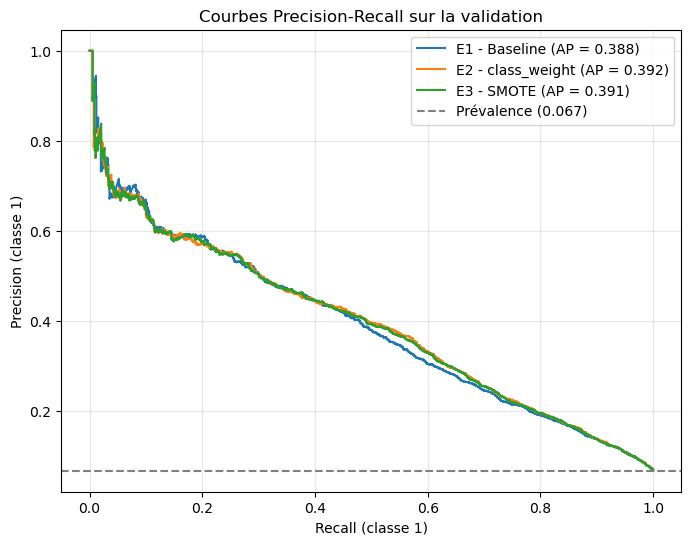

In [86]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

# Probabilités de chaque modèle sur la validation
probas_val = {nom: m.predict_proba(X_val)[:, 1] for nom, m in modeles.items()}

# 1. Tableau récapitulatif au seuil 0,5
tableau_05 = (pd.DataFrame(resultats_validation)
              .drop_duplicates(subset="Modèle", keep="last")
              .set_index("Modèle"))
print("Comparaison des trois modèles (validation, seuil = 0,5) :")
display(tableau_05[colonnes_metriques + ["VP", "FP", "FN", "VN"]].round(4))

# 2. Courbes Precision-Recall
fig, ax = plt.subplots(figsize=(8, 6))
for nom, proba in probas_val.items():
    prec, rec, _ = precision_recall_curve(y_val, proba)
    ap = average_precision_score(y_val, proba)
    ax.plot(rec, prec, label=f"{nom} (AP = {ap:.3f})")
ax.axhline(y_val.mean(), linestyle="--", color="grey",
           label=f"Prévalence ({y_val.mean():.3f})")
ax.set_xlabel("Recall (classe 1)")
ax.set_ylabel("Precision (classe 1)")
ax.set_title("Courbes Precision-Recall sur la validation")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [87]:
def point_fonctionnement(y_true, proba, precision_min):
    """Seuil donnant le Recall maximal avec une Precision >= precision_min."""
    prec, rec, seuils = precision_recall_curve(y_true, proba)
    prec, rec = prec[:-1], rec[:-1]          # alignés sur les seuils
    ok = prec >= precision_min
    if not ok.any():
        return None
    rec_max = rec[ok].max()
    i = np.where(ok & (rec == rec_max))[0][-1]
    return seuils[i], prec[i], rec[i]


# Recall maximal pour plusieurs niveaux de Precision minimale
lignes = []
for nom, proba in probas_val.items():
    for precision_min in [0.20, 0.30, 0.40, 0.50]:
        point = point_fonctionnement(y_val, proba, precision_min)
        if point is None:
            lignes.append({"Modèle": nom, "Precision min": precision_min})
        else:
            seuil, p, r = point
            lignes.append({
                "Modèle": nom,
                "Precision min": precision_min,
                "Seuil": seuil,
                "Precision": p,
                "Recall": r,
                "Alertes (% clients)": (proba >= seuil).mean() * 100
            })

print("Recall maximal pour une Precision minimale donnée (validation) :")
display(pd.DataFrame(lignes).round(4))

# Seuil maximisant le F1 de la classe 1, pour chaque modèle
lignes_f1 = []
for nom, proba in probas_val.items():
    prec, rec, seuils = precision_recall_curve(y_val, proba)
    prec, rec = prec[:-1], rec[:-1]
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    i = np.argmax(f1)
    lignes_f1.append({
        "Modèle": nom, "Seuil (F1 max)": seuils[i],
        "Precision": prec[i], "Recall": rec[i], "F1": f1[i]
    })

print("Seuil maximisant le F1 (validation) :")
display(pd.DataFrame(lignes_f1).round(4))

Recall maximal pour une Precision minimale donnée (validation) :


,Modèle,Precision min,Seuil,Precision,Recall,Alertes (% clients)
0,E1 - Baseline,0.2,0.0642,0.2019,0.7796,25.8780
1,E1 - Baseline,0.3,0.1201,0.3009,0.6112,13.6151
2,E1 - Baseline,0.4,0.1706,0.4016,0.4780,7.9789
3,E1 - Baseline,0.5,0.2947,0.5011,0.3036,4.0609
4,E2 - class_weight,0.2,0.4626,0.2024,0.7896,26.1457
5,E2 - class_weight,0.3,0.6307,0.3004,0.6345,14.1550
6,E2 - class_weight,0.4,0.7577,0.4002,0.4927,8.2511
7,E2 - class_weight,0.5,0.8982,0.5000,0.3049,4.0876
8,E3 - SMOTE,0.2,0.4604,0.2009,0.7903,26.3689
9,E3 - SMOTE,0.3,0.6382,0.3010,0.6365,14.1729


Seuil maximisant le F1 (validation) :


,Modèle,Seuil (F1 max),Precision,Recall,F1
0,E1 - Baseline,0.1711,0.4021,0.4774,0.4365
1,E2 - class_weight,0.7361,0.3917,0.5186,0.4463
2,E3 - SMOTE,0.7269,0.3832,0.5300,0.4448


### Interprétation — comparaison de E1, E2 et E3

D'après les résultats obtenus sur le jeu de validation, je remarque que :

- **Courbes Precision-Recall presque superposées :** les trois modèles ont des Average Precision très proches (0,388 ; 0,392 ; 0,391), bien supérieures à la prévalence de la classe 1 (0,067). E1 est légèrement en dessous des deux autres entre un Recall d'environ 0,4 et 0,6.
- **Comparaison au seuil 0,5 non équitable :** le Recall de 18,04 % pour E1 contre 76 % pour E2 et E3 s'explique surtout par l'échelle des probabilités. La pondération et SMOTE gonflent les probabilités de la classe 1, alors que E1 reste très prudent. À seuil équivalent, l'écart disparaît presque.
- **Points de fonctionnement équivalents :** pour une Precision minimale de 30 %, le Recall est de 61,12 % pour E1, 63,45 % pour E2 et 63,65 % pour E3. Pour 40 %, il est de 47,80 %, 49,27 % et 49,00 %. Pour 20 %, il est de 77,96 %, 78,96 % et 79,03 %. Pour 50 %, les trois modèles sont pratiquement identiques (environ 30 %).
- **Seuils différents :** pour une même Precision, les seuils de E2 et E3 (0,46 à 0,90) sont beaucoup plus élevés que ceux de E1 (0,06 à 0,29), ce qui confirme que leurs probabilités sont gonflées.
- **Coût opérationnel :** pour atteindre une Precision de 30 %, les modèles signalent environ 14 % des clients (13,6 % pour E1, 14,2 % pour E2 et E3) et détectent environ 61 à 64 % des défauts.
- **F1 maximal :** E1 atteint 0,4365, E2 0,4463 et E3 0,4448, avec des seuils respectifs de 0,171, 0,736 et 0,727.

**Conclusion :** les trois stratégies classent les clients de façon très proche. E2 et E3 sont légèrement meilleurs que E1 (environ 1 à 2,5 points de Recall à Precision égale dans la zone intermédiaire), et E2 et E3 sont équivalents entre eux. SMOTE n'apporte donc pas d'avantage par rapport à la simple pondération. Ces écarts étant faibles, je vérifierai s'ils sont significatifs avant de choisir le modèle final.

### 6.6. Choix du modèle final

Les écarts observés entre E1, E2 et E3 sont faibles. Pour savoir s'ils sont réels ou dus au hasard de l'échantillon de validation, je réalise un bootstrap apparié : je tire 1 000 échantillons de la validation avec remise, et je calcule à chaque fois les écarts d'Average Precision et de Recall (à Precision minimale de 30 %) entre les modèles.

Si l'intervalle de confiance à 95 % d'un écart contient 0, je considère que la différence n'est pas significative. Dans ce cas, je choisirai le modèle le plus simple.

Aucun modèle n'est ré-entraîné et le jeu de test n'est pas utilisé.

In [88]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_val.to_numpy()
noms = list(probas_val.keys())
B = 1000

ap_boot = {nom: np.empty(B) for nom in noms}
rec_boot = {nom: np.empty(B) for nom in noms}

for b in range(B):
    # Même échantillon pour les trois modèles (comparaison appariée)
    idx = rng.integers(0, len(y_arr), len(y_arr))
    yb = y_arr[idx]
    for nom in noms:
        pb = probas_val[nom][idx]
        ap_boot[nom][b] = average_precision_score(yb, pb)
        point = point_fonctionnement(yb, pb, 0.30)
        rec_boot[nom][b] = point[2] if point is not None else np.nan

lignes = []
comparaisons = [
    ("E2 - class_weight", "E1 - Baseline"),
    ("E3 - SMOTE", "E1 - Baseline"),
    ("E3 - SMOTE", "E2 - class_weight"),
]
for a, b_ in comparaisons:
    for metrique, tableau in [("Average Precision", ap_boot),
                              ("Recall (Precision >= 30 %)", rec_boot)]:
        ecart = tableau[a] - tableau[b_]
        bas, haut = np.nanpercentile(ecart, [2.5, 97.5])
        lignes.append({
            "Comparaison": f"{a} moins {b_}",
            "Métrique": metrique,
            "Écart moyen": np.nanmean(ecart),
            "IC 95 % bas": bas,
            "IC 95 % haut": haut,
            "Écart significatif": "oui" if (bas > 0 or haut < 0) else "non"
        })

print("Écarts entre modèles (bootstrap apparié, 1 000 tirages, validation) :")
display(pd.DataFrame(lignes).round(4))

Écarts entre modèles (bootstrap apparié, 1 000 tirages, validation) :


,Comparaison,Métrique,Écart moyen,IC 95 % bas,IC 95 % haut,Écart significatif
0,E2 - class_weight moins E1 - Baseline,Average Precision,0.0047,0.0014,0.0079,oui
1,E2 - class_weight moins E1 - Baseline,Recall (Precision >= 30 %),0.0258,0.0065,0.0448,oui
2,E3 - SMOTE moins E1 - Baseline,Average Precision,0.0037,0.0003,0.0067,oui
3,E3 - SMOTE moins E1 - Baseline,Recall (Precision >= 30 %),0.0260,0.0078,0.0453,oui
4,E3 - SMOTE moins E2 - class_weight,Average Precision,-0.0011,-0.0026,0.0005,non
5,E3 - SMOTE moins E2 - class_weight,Recall (Precision >= 30 %),0.0002,-0.0121,0.0122,non


### Interprétation des résultats — choix du modèle final

D'après le bootstrap apparié (1 000 tirages sur la validation), je remarque que :

- **E2 contre E1 :** E2 est significativement meilleur. L'Average Precision augmente de 0,0047 (IC 95 % : 0,0014 à 0,0079) et le Recall à Precision minimale de 30 % augmente de 2,58 points (IC 95 % : 0,65 à 4,48).
- **E3 contre E1 :** SMOTE est également significativement meilleur que le baseline : +0,0037 d'Average Precision (IC 95 % : 0,0003 à 0,0067) et +2,60 points de Recall (IC 95 % : 0,78 à 4,53).
- **E3 contre E2 :** aucune différence significative : -0,0011 d'Average Precision (IC 95 % : -0,0026 à 0,0005) et +0,02 point de Recall (IC 95 % : -1,21 à 1,22).
- **Ampleur des gains :** l'amélioration est réelle mais modeste. À Precision égale (30 %), E2 détecte environ 39 défauts de plus que E1 sur les 1 502 défauts de la validation.
- **Limite :** le bootstrap mesure l'incertitude liée à l'échantillon de validation, pas celle liée à un nouvel entraînement des modèles.

**Décision :** je retiens **E3 (SMOTE + Régression Logistique)** comme modèle final. SMOTE est significativement meilleur que le baseline E1 (+0,0037 d'Average Precision et +2,60 points de Recall à Precision minimale de 30 %). Il n'est pas significativement différent de la pondération des classes (E2), que je conserve comme modèle de référence : une pondération simple donne des performances équivalentes. SMOTE est appliqué uniquement sur les données d'entraînement.

### 6.7. Calibration et choix du seuil de décision

Le modèle final (E3, SMOTE + Régression Logistique) est entraîné sur des données rééquilibrées à 50 % de défauts, ce qui gonfle ses probabilités. Je vérifie donc leur calibration sur le jeu de validation et j'applique une correction de prior (ajout de ln(n1/n0) au logit), qui ne modifie pas le classement des clients mais rétablit l'échelle des probabilités.

Je compare E1, le modèle final brut et le modèle final corrigé avec la probabilité moyenne prédite, le score de Brier et la courbe de calibration.

Je fixe ensuite le seuil de décision sur la validation selon un critère déclaré : Recall maximal avec une Precision d'au moins 30 %. Le jeu de test n'est pas utilisé dans cette étape.

Modèle final : E3 - SMOTE
Effectifs du train : classe 0 = 97567 | classe 1 = 7006
Correction ajoutée au logit : -2.634


,Probabilité moyenne prédite,Taux de défaut observé,Score de Brier
E1 (baseline),0.0679,0.067,0.0506
E3 - SMOTE brut,0.3401,0.067,0.1463
E3 - SMOTE corrigé,0.0721,0.067,0.0514
Référence (prévalence constante),0.0670,0.067,0.0625


Average Precision brut    : 0.3914
Average Precision corrigé : 0.3914


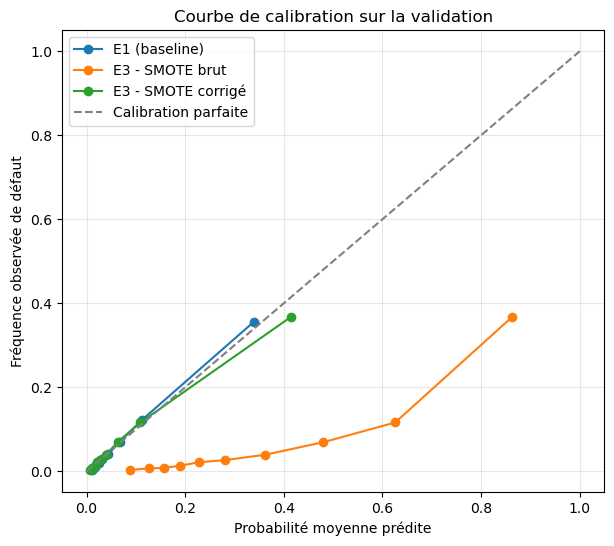

In [89]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Modèle final : "E3 - SMOTE" ou "E2 - class_weight"
MODELE_FINAL = "E3 - SMOTE"
modele_final = modeles[MODELE_FINAL]

# 1. Correction de prior (le train a été rééquilibré à 50 % de défauts)
n0 = int((y_train == 0).sum())
n1 = int((y_train == 1).sum())
decalage = np.log(n1 / n0)
print("Modèle final :", MODELE_FINAL)
print("Effectifs du train : classe 0 =", n0, "| classe 1 =", n1)
print("Correction ajoutée au logit :", round(decalage, 3))

# 2. Probabilités brutes et corrigées sur la validation
z_final = modele_final.decision_function(X_val)
proba_finale_brute = 1 / (1 + np.exp(-z_final))
proba_finale_corrigee = 1 / (1 + np.exp(-(z_final + decalage)))
proba_e1 = modeles["E1 - Baseline"].predict_proba(X_val)[:, 1]

versions = {
    "E1 (baseline)": proba_e1,
    f"{MODELE_FINAL} brut": proba_finale_brute,
    f"{MODELE_FINAL} corrigé": proba_finale_corrigee
}

# 3. Résumé : probabilité moyenne et score de Brier
resume = pd.DataFrame({
    nom: {
        "Probabilité moyenne prédite": p.mean(),
        "Taux de défaut observé": y_val.mean(),
        "Score de Brier": brier_score_loss(y_val, p)
    }
    for nom, p in versions.items()
}).T
resume.loc["Référence (prévalence constante)"] = [
    y_val.mean(), y_val.mean(),
    brier_score_loss(y_val, np.full(len(y_val), y_val.mean()))
]
display(resume.round(4))

# 4. La correction ne change pas le classement
print("Average Precision brut    :", round(average_precision_score(y_val, proba_finale_brute), 4))
print("Average Precision corrigé :", round(average_precision_score(y_val, proba_finale_corrigee), 4))

# 5. Courbe de calibration
fig, ax = plt.subplots(figsize=(7, 6))
for nom, p in versions.items():
    frequence_observee, proba_moyenne = calibration_curve(
        y_val, p, n_bins=10, strategy="quantile"
    )
    ax.plot(proba_moyenne, frequence_observee, marker="o", label=nom)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Calibration parfaite")
ax.set_xlabel("Probabilité moyenne prédite")
ax.set_ylabel("Fréquence observée de défaut")
ax.set_title("Courbe de calibration sur la validation")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [90]:
from sklearn.metrics import confusion_matrix

# Critère déclaré : Recall maximal avec une Precision minimale
PRECISION_MIN = 0.30

seuil, precision_val, recall_val = point_fonctionnement(
    y_val, proba_finale_corrigee, PRECISION_MIN
)

pred_val = (proba_finale_corrigee >= seuil).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val, pred_val).ravel()

# Seuil équivalent sur le score brut du modèle (avant correction)
seuil_brut = 1 / (1 + np.exp(-(np.log(seuil / (1 - seuil)) - decalage)))

bilan = pd.Series({
    "Modèle": MODELE_FINAL,
    "Critère": f"Recall maximal avec Precision >= {PRECISION_MIN:.0%}",
    "Seuil (probabilité corrigée)": round(seuil, 4),
    "Seuil équivalent (score brut)": round(seuil_brut, 4),
    "Recall (classe 1)": round(recall_score(y_val, pred_val), 4),
    "Precision (classe 1)": round(precision_score(y_val, pred_val), 4),
    "F1 (classe 1)": round(f1_score(y_val, pred_val), 4),
    "Spécificité": round(tn / (tn + fp), 4),
    "Alertes (% des clients)": round(pred_val.mean() * 100, 2)
}, name="Modèle final au seuil retenu (validation)")
display(bilan.to_frame())

print("Matrice de confusion (validation, seuil retenu) :")
display(pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Réel 0", "Réel 1"], columns=["Prédit 0", "Prédit 1"]
))

# Valeurs conservées pour l'export (étape suivante)
SEUIL_DECISION = float(seuil)
DECALAGE_LOGIT = float(decalage)

,Modèle final au seuil retenu (validation)
Modèle,E3 - SMOTE
Critère,Recall maximal avec Precision >= 30%
Seuil (probabilité corrigée),0.1124
Seuil équivalent (score brut),0.6382
Recall (classe 1),0.6365
Precision (classe 1),0.301
F1 (classe 1),0.4087
Spécificité,0.8938
Alertes (% des clients),14.17


Matrice de confusion (validation, seuil retenu) :


,Prédit 0,Prédit 1
Réel 0,18687,2220
Réel 1,546,956


### Interprétation des résultats — calibration et seuil

D'après les résultats obtenus sur le jeu de validation, je remarque que :

- **Probabilités brutes mal calibrées :** les probabilités de E3 ont une moyenne de 34,01 % alors que le taux de défaut observé est de 6,70 %. Leur score de Brier (0,1463) est pire que celui d'une prédiction constante égale à la prévalence (0,0625). La courbe de calibration confirme une forte surestimation : par exemple, les clients dont la probabilité brute est d'environ 63 % présentent en réalité un taux de défaut d'environ 12 %.
- **Correction efficace :** après la correction de prior (-2,634 ajouté au logit), la probabilité moyenne est de 7,21 %, proche du taux observé. Le score de Brier est de 0,0514, proche de celui de E1 (0,0506) et meilleur que la référence. La courbe corrigée suit la diagonale, avec une légère surestimation pour le groupe le plus risqué (environ 41 % prédits contre 37 % observés).
- **Classement inchangé :** l'Average Precision reste identique avant et après correction (0,3914), car la correction est monotone.
- **Seuil retenu :** le critère « Recall maximal avec une Precision d'au moins 30 % » donne un seuil de 0,1124 sur la probabilité corrigée (0,6382 sur le score brut). Sur la validation, il détecte 956 défauts sur 1 502 (Recall de 63,65 %), avec une Precision de 30,10 %, un F1 de 0,4087 et une spécificité de 89,38 %. Il signale 14,17 % des clients (2 220 fausses alertes, 546 défauts manqués).

**Décision :** j'utiliserai la probabilité corrigée comme score final, présentée comme une « probabilité estimée à calibration approximative » (surestimation modérée pour les scores les plus élevés). Je n'applique pas de calibration supplémentaire. Le seuil étant choisi sur la validation, ses performances y sont légèrement optimistes : le jeu de test donnera l'estimation honnête.

### 6.8. Niveaux de risque et évaluation finale sur le jeu de test

Je définis d'abord trois niveaux de risque indicatifs à partir de la probabilité corrigée, uniquement avec le jeu de validation :
- niveau élevé : probabilité supérieure ou égale au seuil de décision (Precision minimale de 30 %) ;
- niveau faible : probabilité inférieure au plus grand seuil conservant au moins 85 % des défauts au-dessus ;
- niveau modéré : entre les deux.

Ces niveaux sont indicatifs et ne constituent pas une décision de crédit.

J'évalue ensuite le modèle final, la correction de prior et le seuil figés sur le jeu de test, une seule fois. Les intervalles de confiance sont obtenus par bootstrap du jeu de test, sans aucun ré-entraînement ni ajustement.

In [91]:
# Seuil haut : seuil de décision (Precision >= 30 %)
SEUIL_ELEVE = SEUIL_DECISION

# Seuil bas : plus grand seuil conservant au moins 85 % des défauts au-dessus
RECALL_MIN_FAIBLE = 0.85
_, rec_courbe, seuils_courbe = precision_recall_curve(y_val, proba_finale_corrigee)
rec_courbe = rec_courbe[:-1]
SEUIL_FAIBLE = float(seuils_courbe[rec_courbe >= RECALL_MIN_FAIBLE][-1])

print("Seuil faible / modéré :", round(SEUIL_FAIBLE, 4))
print("Seuil modéré / élevé  :", round(SEUIL_ELEVE, 4))


def niveau_risque(p, seuil_faible, seuil_eleve):
    return np.where(p >= seuil_eleve, "élevé",
                    np.where(p >= seuil_faible, "modéré", "faible"))


def tableau_par_niveau(y, proba):
    df_n = pd.DataFrame({
        "Niveau": niveau_risque(proba, SEUIL_FAIBLE, SEUIL_ELEVE),
        "Défaut": np.asarray(y)
    })
    t = df_n.groupby("Niveau")["Défaut"].agg(
        Clients="count", Défauts="sum", Taux_de_défaut="mean"
    )
    t = t.reindex(["faible", "modéré", "élevé"])
    t["% des clients"] = t["Clients"] / t["Clients"].sum() * 100
    t["% des défauts"] = t["Défauts"] / t["Défauts"].sum() * 100
    t["Taux_de_défaut"] = t["Taux_de_défaut"] * 100
    return t


print("\nNiveaux de risque sur la validation :")
display(tableau_par_niveau(y_val, proba_finale_corrigee).round(2))

Seuil faible / modéré : 0.0409
Seuil modéré / élevé  : 0.1124

Niveaux de risque sur la validation :


,Clients,Défauts,Taux_de_défaut,% des clients,% des défauts
Niveau,,,,,
faible,14851,225,1.52,66.27,14.98
modéré,4382,321,7.33,19.55,21.37
élevé,3176,956,30.10,14.17,63.65


In [92]:
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix


def metriques_completes(y, proba, seuil):
    pred = (proba >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {
        "Recall (classe 1)": recall_score(y, pred),
        "Precision (classe 1)": precision_score(y, pred, zero_division=0),
        "F1 (classe 1)": f1_score(y, pred),
        "Spécificité": tn / (tn + fp),
        "Accuracy": accuracy_score(y, pred),
        "Average Precision": average_precision_score(y, proba),
        "ROC-AUC": roc_auc_score(y, proba),
        "Score de Brier": brier_score_loss(y, proba),
        "Alertes (% des clients)": pred.mean() * 100,
        "VP": int(tp), "FP": int(fp), "FN": int(fn), "VN": int(tn),
    }


# 1. Probabilités corrigées du modèle final sur le TEST (paramètres figés)
z_test = modele_final.decision_function(X_test)
proba_test = 1 / (1 + np.exp(-(z_test + DECALAGE_LOGIT)))
pred_test = (proba_test >= SEUIL_DECISION).astype(int)

# 2. Métriques validation / test
m_val = metriques_completes(y_val, proba_finale_corrigee, SEUIL_DECISION)
m_test = metriques_completes(y_test, proba_test, SEUIL_DECISION)

# 3. Intervalles de confiance par bootstrap du test (mesure uniquement)
rng = np.random.default_rng(RANDOM_STATE)
y_t = y_test.to_numpy()
boot = {"Recall (classe 1)": [], "Precision (classe 1)": [], "Average Precision": []}
for _ in range(1000):
    idx = rng.integers(0, len(y_t), len(y_t))
    yb, pb, db = y_t[idx], proba_test[idx], pred_test[idx]
    boot["Recall (classe 1)"].append(recall_score(yb, db))
    boot["Precision (classe 1)"].append(precision_score(yb, db, zero_division=0))
    boot["Average Precision"].append(average_precision_score(yb, pb))

comparaison = pd.DataFrame({"Validation": m_val, "Test": m_test})
comparaison["IC 95 % (test)"] = ""
for nom, valeurs in boot.items():
    bas, haut = np.percentile(valeurs, [2.5, 97.5])
    comparaison.loc[nom, "IC 95 % (test)"] = f"[{bas:.4f} ; {haut:.4f}]"

lignes_metriques = [l for l in comparaison.index if l not in ["VP", "FP", "FN", "VN"]]
print(f"Évaluation finale - {MODELE_FINAL} (seuil = {SEUIL_DECISION:.4f}) :")
display(comparaison.loc[lignes_metriques])

print("Matrice de confusion (test) :")
display(pd.DataFrame(
    [[m_test["VN"], m_test["FP"]], [m_test["FN"], m_test["VP"]]],
    index=["Réel 0", "Réel 1"], columns=["Prédit 0", "Prédit 1"]
))

print("Niveaux de risque sur le test :")
display(tableau_par_niveau(y_test, proba_test).round(2))

Évaluation finale - E3 - SMOTE (seuil = 0.1124) :


,Validation,Test,IC 95 % (test)
Recall (classe 1),0.636485,0.624250,[0.5988 ; 0.6474]
Precision (classe 1),0.301008,0.304815,[0.2872 ; 0.3209]
F1 (classe 1),0.408722,0.409617,
Spécificité,0.893815,0.897790,
Accuracy,0.876567,0.879468,
Average Precision,0.391376,0.396904,[0.3695 ; 0.4244]
ROC-AUC,0.862415,0.857347,
Score de Brier,0.051439,0.050976,
Alertes (% des clients),14.172877,13.717703,


Matrice de confusion (test) :


,Prédit 0,Prédit 1
Réel 0,18771,2137
Réel 1,564,937


Niveaux de risque sur le test :


,Clients,Défauts,Taux_de_défaut,% des clients,% des défauts
Niveau,,,,,
faible,14881,238,1.60,66.41,15.86
modéré,4454,326,7.32,19.88,21.72
élevé,3074,937,30.48,13.72,62.43


### 6.9. Export du pipeline d'inférence et des métadonnées

Dans cette étape, j'exporte le modèle final pour l'application. Je copie le pipeline, j'intègre la correction de prior dans l'intercept de la Régression Logistique et je retire SMOTE, qui n'est utilisé que pendant l'entraînement. Le pipeline exporté renvoie ainsi directement la probabilité corrigée à partir des données brutes d'un client.

Je vérifie qu'il donne les mêmes probabilités que celles évaluées sur le test, puis j'enregistre le modèle (`model.joblib`), ses métadonnées (`metadata.json`), ses métriques (`metrics.json`) et cinq exemples de référence (`exemples_reference.json`) dans `ml/artifacts/`.

Enfin, je recharge le modèle dans un processus Python indépendant pour vérifier qu'il fonctionne en dehors du notebook, comme le fera l'API.

In [93]:
import os
import copy
import json
import joblib
from sklearn.pipeline import Pipeline as SkPipeline

DOSSIER_ARTEFACTS = "../ml/artifacts"
os.makedirs(DOSSIER_ARTEFACTS, exist_ok=True)

# 1. Copie du modèle final (le modèle du notebook n'est pas modifié)
modele_copie = copy.deepcopy(modele_final)

# 2. Intégration de la correction de prior dans l'intercept
lr = modele_copie.named_steps["modele"]
lr.intercept_ = lr.intercept_ + DECALAGE_LOGIT

# 3. Pipeline d'inférence : sans SMOTE
modele_inference = SkPipeline(
    [(nom, etape) for nom, etape in modele_copie.steps if nom != "smote"]
)
print("Étapes du pipeline d'inférence :", [nom for nom, _ in modele_inference.steps])

# 4. Vérification : mêmes probabilités que l'évaluation sur le test
proba_inference = modele_inference.predict_proba(X_test)[:, 1]
print("Écart maximal avec les probabilités du notebook :",
      np.abs(proba_inference - proba_test).max())
print("Mêmes décisions au seuil retenu :",
      np.array_equal((proba_inference >= SEUIL_DECISION).astype(int), pred_test))

# 5. Sauvegarde
joblib.dump(modele_inference, f"{DOSSIER_ARTEFACTS}/model.joblib", compress=3)
print("Modèle sauvegardé :", os.path.abspath(f"{DOSSIER_ARTEFACTS}/model.joblib"))

Étapes du pipeline d'inférence : ['nettoyage', 'ecretage', 'log_debtratio', 'transformation', 'modele']
Écart maximal avec les probabilités du notebook : 6.938893903907228e-17
Mêmes décisions au seuil retenu : True
Modèle sauvegardé : c:\Users\espacegamers\Desktop\Master IAII\Cours\drive-download-20251005T182208Z-1-001\S3\Data mining\Projet\CreditRisk360\ml\artifacts\model.joblib


In [94]:
import hashlib
import datetime
import platform
import sklearn
import imblearn
from creditrisk_preprocessing import FEATURES, INDICATEURS


def sha256_fichier(chemin):
    h = hashlib.sha256()
    with open(chemin, "rb") as f:
        for bloc in iter(lambda: f.read(1024 * 1024), b""):
            h.update(bloc)
    return h.hexdigest()


def convertir(o):
    return o.item() if hasattr(o, "item") else str(o)


# Empreinte du dataset (adapte le chemin si besoin)
CHEMIN_DONNEES = "../data/raw/cs-training.csv"
if os.path.exists(CHEMIN_DONNEES):
    hash_donnees = sha256_fichier(CHEMIN_DONNEES)
else:
    hash_donnees = None
    print("Attention : fichier de données introuvable, dataset_hash laissé vide. Adapte CHEMIN_DONNEES.")

# Paramètres de SMOTE (si le modèle final l'utilise)
smote_params = None
if "smote" in modele_final.named_steps:
    p = modele_final.named_steps["smote"].get_params()
    smote_params = {k: p.get(k) for k in ["sampling_strategy", "k_neighbors", "random_state"]}

# 1. metadata.json
metadata = {
    "model_name": "CreditRisk360",
    "model_version": "v1.0.0",
    "threshold_version": "thresholds-v1",
    "trained_at": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "algorithm": f"{MODELE_FINAL} (Régression Logistique)",
    "score_type": "probability_prior_corrected_approx",
    "features": FEATURES,
    "feature_schema_hash": hashlib.sha256(json.dumps(FEATURES).encode("utf-8")).hexdigest(),
    "dataset_file": "cs-training.csv",
    "dataset_hash": hash_donnees,
    "random_state": RANDOM_STATE,
    "split": {"proportions": "70/15/15", "stratifie": True,
              "train": len(X_train), "validation": len(X_val), "test": len(X_test)},
    "prevalence": {"train": float(y_train.mean()), "validation": float(y_val.mean()),
                   "test": float(y_test.mean())},
    "preprocessing": {
        "valeurs_invalides": "âge hors [18, 120] et retards égaux à 96 ou 98 remplacés par NaN",
        "indicateurs": INDICATEURS,
        "bornes_ecretage": modele_final.named_steps["ecretage"].bornes_,
        "log1p": ["DebtRatio"],
        "imputation": "médiane apprise sur le train",
        "standardisation": "StandardScaler appris sur le train",
    },
    "smote": smote_params,
    "prior_correction": {"decalage_logit": DECALAGE_LOGIT, "integre_dans_intercept": True},
    "thresholds": {
        "faible_modere": SEUIL_FAIBLE,
        "modere_eleve": SEUIL_ELEVE,
        "decision": SEUIL_DECISION,
        "critere_decision": f"Recall maximal avec Precision >= {PRECISION_MIN:.0%} (validation)",
        "critere_faible": f"Plus grand seuil conservant au moins {RECALL_MIN_FAIBLE:.0%} des défauts au-dessus (validation)",
    },
    "libraries": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "imbalanced-learn": imblearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": joblib.__version__,
    },
}
with open(f"{DOSSIER_ARTEFACTS}/metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2, default=convertir)

# 2. metrics.json
metrics = {
    "modele": MODELE_FINAL,
    "seuil_decision": SEUIL_DECISION,
    "validation": m_val,
    "test": m_test,
    "intervalles_confiance_test": {
        nom: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))]
        for nom, v in boot.items()
    },
    "niveaux_risque_validation": tableau_par_niveau(y_val, proba_finale_corrigee).to_dict(orient="index"),
    "niveaux_risque_test": tableau_par_niveau(y_test, proba_test).to_dict(orient="index"),
    "comparaison_experiences_validation_seuil_0_5":
        tableau_05[colonnes_metriques + ["VP", "FP", "FN", "VN"]].to_dict(orient="index"),
    "calibration_validation": resume.to_dict(orient="index"),
}
with open(f"{DOSSIER_ARTEFACTS}/metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2, default=convertir)

# 3. exemples_reference.json : 5 clients valides avec leur score attendu
indices = (
    list(X_test.dropna().index[:3])
    + list(X_test[X_test["MonthlyIncome"].isnull() & X_test["NumberOfDependents"].notnull()].index[:1])
    + list(X_test[X_test["NumberOfDependents"].isnull()].index[:1])
)
etiquettes = (["profil complet"] * 3 + ["revenu manquant"]
              + ["revenu et personnes à charge manquants"])


def nombre_json(valeur):
    if pd.isnull(valeur):
        return None
    valeur = float(valeur)
    return int(valeur) if valeur.is_integer() else valeur


exemples = []
for etiquette, i in zip(etiquettes, indices):
    ligne = X_test.loc[[i]]
    score = float(modele_inference.predict_proba(ligne)[0, 1])
    exemples.append({
        "description": etiquette,
        "index_original": int(i),
        "features": {c: nombre_json(ligne.iloc[0][c]) for c in FEATURES},
        "risk_score": score,
        "risk_level": str(niveau_risque(np.array([score]), SEUIL_FAIBLE, SEUIL_ELEVE)[0]),
    })
with open(f"{DOSSIER_ARTEFACTS}/exemples_reference.json", "w", encoding="utf-8") as f:
    json.dump({"model_version": "v1.0.0", "exemples": exemples}, f, ensure_ascii=False, indent=2)

print("Fichiers créés dans", os.path.abspath(DOSSIER_ARTEFACTS), ":")
for nom_fichier in sorted(os.listdir(DOSSIER_ARTEFACTS)):
    taille = os.path.getsize(os.path.join(DOSSIER_ARTEFACTS, nom_fichier)) / 1024
    print(" -", nom_fichier, f"({taille:.1f} Ko)")

display(pd.DataFrame([
    {"Description": e["description"], "Score": round(e["risk_score"], 4), "Niveau": e["risk_level"]}
    for e in exemples
]))

Fichiers créés dans c:\Users\espacegamers\Desktop\Master IAII\Cours\drive-download-20251005T182208Z-1-001\S3\Data mining\Projet\CreditRisk360\ml\artifacts :
 - exemples_reference.json (3.0 Ko)
 - metadata.json (2.6 Ko)
 - metrics.json (4.7 Ko)
 - model.joblib (2.6 Ko)


,Description,Score,Niveau
0,profil complet,0.9462,élevé
1,profil complet,0.0151,faible
2,profil complet,0.9956,élevé
3,revenu manquant,0.0073,faible
4,revenu et personnes à charge manquants,0.0029,faible


In [96]:
import sys
import subprocess
import textwrap

code = textwrap.dedent('''
    import sys, json, joblib, pandas as pd
    sys.path.append("../ml/training")
    modele = joblib.load("../ml/artifacts/model.joblib")
    ref = json.load(open("../ml/artifacts/exemples_reference.json", encoding="utf-8"))
    X = pd.DataFrame([e["features"] for e in ref["exemples"]])
    scores = modele.predict_proba(X)[:, 1]
    attendus = [e["risk_score"] for e in ref["exemples"]]
    print("Écart maximal (processus indépendant) :",
          max(abs(a - b) for a, b in zip(scores, attendus)))
''')

resultat = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True)
print(resultat.stdout)
if resultat.returncode != 0:
    print("ERREUR :", resultat.stderr[-1500:])

Ã‰cart maximal (processus indÃ©pendant) : 4.7704895589362195e-18

